# **# AVANCE 1**

# Guia 1

In [ ]:
#CREAR ESTRUCTURA DE CARPETAS
!mkdir -p datos/crudos
!mkdir -p datos/procesados
!mkdir -p datos/externos

print('Carpetas creadas!!!!')


In [ ]:
#IMPORTAR LIBRERIAS
import pandas as pd
import sqlite3
import json
from pathlib import Path

print('Librerias importadas')

In [ ]:
#DEFINIR RUTA DE TRABAJO
BASE_DIR = Path("/content/")
DATA_RAW = BASE_DIR / "datos"/"crudos"
DATA_PROCESSED = BASE_DIR / "datos"/"procesados"
DATA_EXTERNAL = BASE_DIR / "datos"/"externos"

print (f"Datos crudos: {DATA_RAW}")
print (f"Datos procesados: {DATA_PROCESSED}")
print (f"Datos externos: {DATA_EXTERNAL}")


In [ ]:
# CREAR DATOS DE EMPLEADOS

empleados = pd.DataFrame({
    "id_empleado": [1,2,3,4,5,6,7,8,9,10],
    "nombre": ["Ana","Luis","Carlos","María","Sofía","José","Laura","Daniel","Paola","Miguel"],
    "departamento": ["Ventas","IT","Finanzas","RRHH","Marketing","IT","Ventas","Finanzas","RRHH","Marketing"],
    "edad": [25,31,28,35,29,26,40,33,27,38],
    "desempeño": [85,92,70,88,78,95,65,82,90,74],
    "salario": [550,900,650,750,700,950,600,800,720,680],
    "tiempo_empresa_anios": [2,5,1,7,3,2,10,6,2,8],
    "estado_empleado": ["Activo","Activo","Inactivo","Activo","Activo",
                        "Activo","Inactivo","Activo","Activo","Inactivo"]
})

print("Datos de empleados creados!!!!")
print(empleados)

In [ ]:
# CREAR ARCHIVO CSV
ruta_csv = DATA_RAW / "empleados.csv"
empleados.to_csv(ruta_csv, index=False, encoding="utf-8")

print(f"Archivo CSV guardado en: {ruta_csv}")

In [ ]:
# LEER ARCHIVO CSV
df_empleados = pd.read_csv(ruta_csv)

print("Leyendo el archivo CSV")
print(df_empleados.head())

In [ ]:
# CREAR COLUMNA CALCULADA - SALARIO ANUAL = SALARIO MENSUAL * 12
df_empleados["salario_anual"] = df_empleados["salario"] * 12

print("Empleados con salario anual calculado:\n")
print(df_empleados[["id_empleado", "nombre", "salario", "salario_anual"]])

In [ ]:
# CREAR BASE DE DATOS SQL - CONECTAMOS A SQLITE
conexion = sqlite3.connect(DATA_RAW / "empresa_hr_analytics.db")
cursor = conexion.cursor()
print("Base de datos conectada")

In [ ]:
# CREAR TABLA CAPACITACIONES
cursor.execute("""
CREATE TABLE IF NOT EXISTS capacitaciones (
    id_capacitacion INTEGER PRIMARY KEY,
    id_empleado INTEGER NOT NULL,
    curso TEXT NOT NULL,
    horas INTEGER NOT NULL,
    resultado TEXT NOT NULL
)
""")

conexion.commit()

print("Tabla 'capacitaciones' creada")

In [ ]:
# INSERTAR CAPACITACIONES
capacitaciones = [
    (1, 1, "Excel avanzado", 10, "Aprobado"),
    (2, 2, "Comunicación efectiva", 8, "Aprobado"),
    (3, 3, "Liderazgo", 12, "Reprobado"),
    (4, 4, "Trabajo en equipo", 6, "Aprobado"),
    (5, 5, "Power BI", 10, "Aprobado"),
    (6, 6, "Gestión del tiempo", 6, "Aprobado"),
    (7, 7, "Resolución de conflictos", 8, "Reprobado"),
    (8, 8, "Inteligencia emocional", 8, "Aprobado"),
    (9, 9, "Análisis de datos", 12, "Aprobado"),
    (10, 10, "Seguridad informática", 10, "Aprobado")
]

cursor.executemany("""
INSERT OR REPLACE INTO capacitaciones
(id_capacitacion, id_empleado, curso, horas, resultado)
VALUES (?, ?, ?, ?, ?)
""", capacitaciones)

conexion.commit()

print("10 capacitaciones insertadas")

In [ ]:
# CONSULTAR CAPACITACIONES
df_capacitaciones = pd.read_sql_query("SELECT * FROM capacitaciones;",conexion)

print("\nCapacitaciones en la base de datos\n")
df_capacitaciones

In [ ]:
# INTEGRAR EMPLEADOS + CAPACITACIONES
df_integrado = pd.merge(df_empleados, df_capacitaciones, on="id_empleado",how="left")

print("Empleados con información de capacitaciones\n")
df_integrado[["id_empleado", "nombre", "departamento", "desempeño","curso", "horas", "resultado"]]

In [ ]:
# CALCULAR INDICADOR - HORAS DE CAPACITACION POR EMPLEADO
df_integrado["horas_capacitacion"] = df_integrado["horas"]

print("\nEmpleados con horas de capacitación:")
df_integrado[["id_empleado", "nombre", "horas_capacitacion"]]

In [ ]:
# CREAR ARCHIVO JSON
datos_adicionales = [
    {"id_empleado": 1, "satisfaccion": 4, "horas_extra": 5},
    {"id_empleado": 2, "satisfaccion": 5, "horas_extra": 3},
    {"id_empleado": 3, "satisfaccion": 2, "horas_extra": 12},
    {"id_empleado": 4, "satisfaccion": 4, "horas_extra": 4},
    {"id_empleado": 5, "satisfaccion": 3, "horas_extra": 8},
    {"id_empleado": 6, "satisfaccion": 5, "horas_extra": 2},
    {"id_empleado": 7, "satisfaccion": 2, "horas_extra": 14},
    {"id_empleado": 8, "satisfaccion": 4, "horas_extra": 5},
    {"id_empleado": 9, "satisfaccion": 5, "horas_extra": 3},
    {"id_empleado": 10, "satisfaccion": 3, "horas_extra": 9}
]

print("Datos adicionales de empleados:")
for dato in datos_adicionales:
    print(f" Empleado {dato['id_empleado']}: satisfacción {dato['satisfaccion']} y horas extra: {dato['horas_extra']}")

In [ ]:
# GUARDAR JSON

ruta_json = DATA_EXTERNAL / "datos_adicionales.json"
with open(ruta_json, "w", encoding="utf-8") as archivo:
    json.dump(datos_adicionales, archivo, ensure_ascii=False, indent=4)

print(f"Archivo JSON guardado en: {ruta_json}")

In [ ]:
# LEER JSON
df_laborales = pd.read_json(ruta_json)

print("Datos adicionales como DataFrame")
df_laborales

In [ ]:
# INTEGRAR DATOS DEL JSON
df_final = pd.merge(df_integrado, df_laborales, on="id_empleado", how="left")

print("\nDataset final con información de las tres fuentes:")

df_final[["id_empleado", "nombre", "departamento", "desempeño", "horas_capacitacion", "satisfaccion", "horas_extra", "estado_empleado"]]

In [ ]:
# VALIDACIÓN DE CARDINALIDAD

filas_antes = len(df_integrado)
filas_despues = len(df_final)

columnas_antes = len(df_integrado.columns)
columnas_despues = len(df_final.columns)

duplicados_antes = df_integrado.duplicated().sum()
duplicados_despues = df_final.duplicated().sum()

print("VALIDACIÓN DE CARDINALIDAD")
print("Filas antes:", filas_antes)
print("Filas después:", filas_despues)
print("Columnas antes:", columnas_antes)
print("Columnas después:", columnas_despues)
print("Duplicados antes:", duplicados_antes)
print("Duplicados después:", duplicados_despues)

In [ ]:
# VALORES NULOS

print("VALORES NULOS: ")

nulos = df_final.isnull().sum()

print(nulos)



In [ ]:
# EVALUAR DUPLICADOS
print("Cantidad de filas duplicadas:")
duplicados = df_final.duplicated().sum()
print(f"Resgistros duplicados: {duplicados}")


In [ ]:
# REVISAR TIPOS DE DATOS
print("Tipos de datos:")
print(df_final.dtypes)

In [ ]:
# CALCULAR TRES INDICADORES INICIALES

total_empleados = len(df_final)
empleados_inactivos = (df_final["estado_empleado"] == "Inactivo").sum()

porcentaje_inactivos = (empleados_inactivos / total_empleados) * 100
promedio_desempeño = df_final["desempeño"].mean()
promedio_satisfaccion = df_final["satisfaccion"].mean()

print("Indicadores iniciales:")
print("Porcentaje de empleados inactivos:", porcentaje_inactivos)
print("Promedio de desempeño:", promedio_desempeño)
print("Promedio de satisfacción:", promedio_satisfaccion)

In [ ]:
# CREAR INVENTARIO DE FUENTES
inventario_fuentes = pd.DataFrame({
    "fuente": ["Empleados", "Capacitaciones", "Datos adicionales"],
    "tipo": ["CSV", "SQL", "JSON"],
    "ubicacion": [
        "datos/crudos/empleados.csv",
        "datos/crudos/empresa_hr_analytics.db",
        "datos/externos/datos_adicionales.json"
    ],
    "descripcion": [
        "Datos generales y desempeño de empleados",
        "Información de cursos y horas de capacitación",
        "Satisfacción y horas extra"
    ]
})

print("Inventario de fuentes:")
print(inventario_fuentes)

In [ ]:
# GUARDAR DATASET FINAL
df_final.to_csv(DATA_PROCESSED/"dataset_integrado_HRTech_People_Analytics.csv", index=False)

print(f" Dataset guardado en: {DATA_PROCESSED / 'dataset_integrado_HRTech_People_Analytics.csv'}")

print("Archivos generados")
print("datos/crudos: ")
!ls -la datos/crudos/

print("datos/externos: ")
!ls -la datos/externos/

print("datos/procesados: ")
!ls -la datos/procesados/


In [ ]:
# GUARDAR INDICADORES

indicadores = pd.DataFrame({
    "indicador": [
        "Porcentaje de empleados inactivos (%)",
        "Promedio de desempeño",
        "Promedio de satisfacción"
    ],
    "valor": [
        porcentaje_inactivos,
        promedio_desempeño,
        promedio_satisfaccion
    ]
})

ruta_indicadores = DATA_PROCESSED / "indicadores_iniciales.csv"
indicadores.to_csv(ruta_indicadores, index=False)

print("Indicadores guardados en:", ruta_indicadores)

In [ ]:
# DESCARGAR ARCHIVO
from google.colab import files

files.download("/content/datos/procesados/dataset_integrado_HRTech_People_Analytics.csv")

print("Archivo descargado")


# **Guia 2**

In [ ]:
import numpy as np
print("----- Libreria Importada -----")

In [ ]:
#DEFINIR RUTAS - MANTENEMOS LA MISMA ESTRUCTURA
BASE_DIR = Path("/content/")
DATA_PROCESSED = BASE_DIR/"datos"/"procesados"
DOCUMENTOS = BASE_DIR/"documentos"

#CREAR CARPETAS SI NO EXISTEN
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
DOCUMENTOS.mkdir(parents=True, exist_ok=True)

print(f"Datos procesados: {DATA_PROCESSED}")
print(f"Documentos: {DOCUMENTOS}")

In [ ]:
#CARGAR DATASET DE LA GUIA 1
ruta_entrada = DATA_PROCESSED / "dataset_integrado_HRTech_People_Analytics.csv"
df = pd.read_csv(ruta_entrada)

print(f"Dataset cargado: {ruta_entrada}")
print(f"Dimensiones:  {df.shape[0]} filas, {df.shape[1]} columnas")

df.head()

In [ ]:
#CREAR COPIAS DE TRABAJO - PARA NO PERDER EL ORIGINAL

df_original = df.copy() #Copia inalterada para compara después
df_limpio = df.copy() #Copia que vamos a modificar

print("Copias de trabajo creadas: -------")
print(f"Dataset original: {df_original.shape}")
print(f"Para limpiar:  {df_limpio.shape}")

In [ ]:
#DIAGNOSTICO INICIAL DE CALIDAD

#DIMENSIONES - ¿CUANTOS DATOS TENEMOS?
print("Dimensiones: ------")
print(f"Filas: {df_limpio.shape[0]}, Columnas: {df_limpio.shape[1]}\n")

#NOMBRES DE COLUMNAS - ¿ESTÁN BIEN ESCRITOS?
print("Nombres de las columnas: ------")
print(df_limpio.columns.tolist())

In [ ]:
#TIPOS DE DATOS - ¿CADA COLUMNA TIENE EL TIPO CORRECTO?

print("\nTipos de datos: --------")
print(df_limpio.dtypes)


In [ ]:
#INFORMACIÓN GENERAL - RESUMEN COMPLETO

print("Información General: --------")
df_limpio.info()

In [ ]:
#VALORES NULOS - ¿HAY DATOS FALTANTES?

print("\nVALORES NULOS: ----------")
nulos = df_limpio.isnull().sum()
print(nulos)

#PORCENTAJES DE NULOS
print("\nPorcentajes de nulos: --------")
porcentaje_nulos = (df_limpio.isnull().mean() * 100).round(2)
print(porcentaje_nulos)

In [ ]:
#REGISTROS DUPLICADOS - ¿HAY FILAS REPETIDAS?

print("Registros duplicados: ---------")

duplicados = df_limpio.duplicated().sum()
print(f"Registros duplicadas: {duplicados}")

In [ ]:
#VALORES UNICOS EN CATEGORIAS - ¿ESTAN CONSISTENTES?

print("Valores únicos en categorías: --------")
columnas_categorias = df_limpio.select_dtypes(include='object').columns

for columna in columnas_categorias:
    print(f"\n{columna}: ")
    print(df_limpio[columna].unique())

In [ ]:
# CREAR DATASET CON ERRORES CONTROLADOS
# SIMULACIÓN DE PROBLEMAS REALES EN EL DATASET DE EMPLEADOS

df_errores = df_limpio.copy()

# ERROR 1: Espacios y mayúsculas/minúsculas en departamento
df_errores.loc[0, 'departamento'] = ' ventas '   # Espacios al inicio y al final
df_errores.loc[1, 'departamento'] = 'it'         # En minúsculas
df_errores.loc[4, 'departamento'] = 'MARKETING ' # Mayúsculas con espacio

# ERROR 2: Valor nulo en una columna categórica o de métrica
df_errores.loc[3, 'resultado'] = np.nan

# ERROR 3: Salario negativo (dato numérico inválido)
df_errores.loc[2, 'salario'] = -650

# ERROR 4: Registro duplicado (repetir la primera fila)
df_errores = pd.concat([df_errores, df_errores.iloc[[0]]], ignore_index=True)

print("----- DATASET CON ERRORES -----")
print(df_errores[['id_empleado', 'nombre', 'departamento', 'salario', 'resultado']])

In [ ]:
#GUARDAR EL DATASET CON ERRORES
ruta_errores = DATA_PROCESSED/"dataset_con_errores_HRTech_People_Analytics.csv"

df_errores.to_csv(ruta_errores, index=False, encoding='utf-8')
print(f"Dataset con errores guardado en: {ruta_errores}")

df_limpio = df_errores.copy()

In [ ]:
#LIMPIEZA DE NOMBRES DE COLUMNAS
print("Nombres de columnas - antes: ")
print(df_limpio.columns.tolist())

df_limpio.columns = (
    df_limpio.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_', regex=False)
)
print("\nNombres de columnas - después: ")
print(df_limpio.columns.tolist())

In [ ]:
#ELIMINAR ESPACIOS EN TEXTOS

#TODAS LAS COLUMNAS DE TEXTO DEBEN TENER SUS VALORES LIMPIOS
columnas_texto = df_limpio.select_dtypes(include='object').columns
print(f"Columnas de texto: {columnas_texto.tolist()}")

for columna in columnas_texto:
    df_limpio[columna] = df_limpio[columna].astype('string').str.strip()

    print("Espacios eliminados de las columnas de texto")

In [ ]:
# NORMALIZAR DEPARTAMENTO

print("DEPARTAMENTO - ANTES: ", df_limpio['departamento'].unique().tolist())

# CONVERTIR A MINÚSCULAS PRIMERO Y QUITAR ESPACIOS RESIDUALES
df_limpio['departamento'] = df_limpio['departamento'].astype(str).str.strip().str.lower()

# DICCIONARIO DE ESTANDARIZACIÓN
mapeo_departamentos = {
    'ventas': 'Ventas',
    'it': 'IT',
    'finanzas': 'Finanzas',
    'rrhh': 'RRHH',
    'marketing': 'Marketing'
}

df_limpio['departamento'] = df_limpio['departamento'].replace(mapeo_departamentos)

print("DEPARTAMENTO - DESPUÉS: ", df_limpio['departamento'].unique().tolist())

In [ ]:
# NORMALIZAR CATEGORIAS PRINCIPALES
# ESTANDARIZAR FORMATO DE DEPARTAMENTO, CURSO, RESULTADO Y ESTADO DEL EMPLEADO

columnas_normalizar = ['departamento', 'curso', 'resultado', 'estado_empleado']

for columna in columnas_normalizar:
    if columna in df_limpio.columns:
        df_limpio[columna] = (
            df_limpio[columna]
            .astype('string')
            .str.strip()
            .str.title()
        )

        if columna == 'departamento':
            df_limpio[columna] = df_limpio[columna].replace({
                'It': 'IT',
                'Rrhh': 'RRHH'
            })

        print(f"{columna} normalizada: {df_limpio[columna].unique().tolist()}")


In [ ]:
#RESTAURAR VALORES NULOS

df_limpio = df_limpio.replace({'nan': np.nan, '<NA>': np.nan, 'None': np.nan})

print("VALORES NULOS DESPUÉS DE RESTAURAR: ------------")

print(df_limpio[['resultado']].isnull().sum())

In [ ]:
#COMPLETAR VALORES AUSENTES

df_limpio['curso'] = df_limpio['curso'].fillna('Sin curso asignado')

df_limpio['resultado'] = df_limpio['resultado'].fillna('Sin evaluar')

print("VALORES COMPLETADOS: ------------")

print(df_limpio[['curso', 'resultado']].head(7))


In [ ]:
#ELIMINAR DUPLICADOS

print(f"Duplicados antes: {df_limpio.duplicated().sum()}")

df_limpio = df_limpio.drop_duplicates().reset_index(drop=True)

print(f"Duplicados después: {df_limpio.duplicated().sum()}")

print(f"Nuevas dimensiones: {df_limpio.shape}")

In [ ]:
#CONVERTIR COLUMNAS NUMÉRICAS

columnas_numericas = [
    'edad', 'desempeño', 'tiempo_empresa_anios', 'horas',
    'satisfaccion', 'horas_extra'
]

columnas_salarios = ['salario', 'salario_anual']

for columna in columnas_numericas:
    df_limpio[columna] = pd.to_numeric(df_limpio[columna], errors='coerce')

for columna in columnas_salarios:
    df_limpio[columna] = pd.to_numeric(df_limpio[columna], errors='coerce').astype(float)

print("Columnas numéricas convertidas: -------------")
print(df_limpio[columnas_numericas + columnas_salarios].dtypes)


In [ ]:
#CORREGIR SALARIOS NEGATIVOS

salarios_negativos = df_limpio[df_limpio['salario'] < 0]
print(f"Salarios negativos encontrados: {len(salarios_negativos)}")

if len(salarios_negativos) > 0:
  print(salarios_negativos[['id_empleado', 'salario', 'salario_anual']])

df_limpio['salario'] = df_limpio['salario'].abs()
df_limpio['salario_anual'] = df_limpio['salario_anual'].abs()

print("Salarios negativos corregidos")


In [ ]:
#RECALCULAR VARIABLES DERIVADAS

df_limpio['salario_anual'] = df_limpio['salario'] * 12

df_limpio['salario_por_hora'] = df_limpio['salario'] / df_limpio['horas']

print("Variables recalculadas: -----")
print(df_limpio[['id_empleado', 'salario', 'horas', 'salario_anual', 'salario_por_hora']].head())


In [ ]:
#CARACTERISTICAS TEMPORALES
#ANTIGÜEDAD

df_limpio['anios_redondeados'] = df_limpio['tiempo_empresa_anios'].round()

df_limpio['es_antiguo'] = df_limpio['tiempo_empresa_anios'] >= 5

def asignar_categoria(anios):
    if anios >= 5:
        return 'Senior'
    else:
        return 'Junior'


df_limpio['categoria_antiguedad'] = df_limpio['tiempo_empresa_anios'].apply(asignar_categoria)

def asignar_rango_edad(edad):
    if edad < 30: return 'Joven (<30)'
    elif edad <= 50: return 'Adulto (30-50)'
    else: return 'Mayor (>50)'

df_limpio['rango_edad'] = df_limpio['edad'].apply(asignar_rango_edad)

df_limpio['requiere_capacitacion'] = df_limpio['resultado'] == 'Reprobado'


print("Características de antigüedad creadas: -----")
print(df_limpio[['id_empleado', 'tiempo_empresa_anios', 'anios_redondeados', 'es_antiguo', 'categoria_antiguedad', 'rango_edad', 'requiere_capacitacion']].head())

In [ ]:
# REPORTE DE CALIDAD

reporte_calidad = pd.DataFrame({
    'columna': df_limpio.columns,
    'tipo_dato': [str(df_limpio[col].dtype) for col in df_limpio.columns],
    'valores_nulos': [df_limpio[col].isnull().sum() for col in df_limpio.columns],
    'valores_unicos': [df_limpio[col].nunique() for col in df_limpio.columns]
})

print("REPORTE CALIDAD")
reporte_calidad

In [ ]:
#GUARDAR REPORTE EN EXCEL
ruta_reporte = DOCUMENTOS / "reporte_calidad_HRTech_People_Analytics.xlsx"
reporte_calidad.to_excel(ruta_reporte, index=False)
print(f"Reporte guardado: {ruta_reporte}")

In [ ]:
# GUARDAR DATASET LIMPIO
ruta_salida = DATA_PROCESSED / "dataset_limpio_HRTech_People_Analytics.csv"
df_limpio.to_csv(ruta_salida, index=False, encoding='utf-8')
print(f"Dataset limpio guardado: {ruta_salida}")

# **Guia 3**

In [ ]:
#INSTALAR PYSPARK

%pip install pyspark
print("Pyspark instalado")

In [ ]:
#IMPORTAR LIBRERIAS
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *
from pathlib import Path
import pandas as pd
import time

print("Librerias importadas---------------")

In [ ]:
#CREAR SESION DE SPARK

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("HRTech_PeopleAnalytics_Arquitectura") \
    .getOrCreate()

print(f"Spark version: {spark.version}")
print(f"Paralelismo: {spark.sparkContext.defaultParallelism}")

In [ ]:
#DEFINIR RUTAS

BASE_DIR = Path("/content")
DATA_PROCESSED = BASE_DIR / "datos" / "procesados"
DATA_ANALYTICS = BASE_DIR / "datos" / "analiticos"
DOCUMENTOS = BASE_DIR / "documentos"

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
DATA_ANALYTICS.mkdir(parents=True, exist_ok=True)
DOCUMENTOS.mkdir(parents=True, exist_ok=True)

print(f"Datos procesados: {DATA_PROCESSED}")
print(f"Datos analiticos: {DATA_ANALYTICS}")
print(f"Documentos: {DOCUMENTOS}")

In [ ]:
#CARGAR DATASET LIMPIO
ruta_entrada = DATA_PROCESSED / "dataset_limpio_HRTech_People_Analytics.csv"

print(f"Leyendo: {ruta_entrada}")

df = spark.read \
    .option("header", True) \
    .option("inferSchema", True) \
    .csv(str(ruta_entrada))

print("Dataset cargado en Spark")
print(f"Filas: {df.count()}")
print(f"Columnas: {len(df.columns)}")

In [ ]:
#1. EXPLORACION BASICA - ESQUEMA Y ESTRUCTURA DEL DATASET
print("Esquema de datos:-------------")
df.printSchema()

print("\nPrimeras filas: ")
df.show(10, truncate=False)

In [ ]:
#ESTADISTICAS DESCRIPTIVAS
print("Estadisticas descriptivas (describe):-------------")
df.describe().show(truncate=False)

#ESTADISTICAS SOLO DE COLUMNAS NUMERICAS CLAVE
print("\nEstadisticas de columnas clave:")
df.describe("edad", "desempeño", "salario", "satisfaccion", "tiempo_empresa_anios").show(truncate=False)

Estadisticas descriptivas (describe):-------------
+-------+------------------+------+------------+-----------------+-----------------+------------------+--------------------+---------------+------------------+------------------+-----------------+------------------+-----------+------------------+------------------+-----------------+------------------+-----------------+--------------------+--------------+
|summary|id_empleado       |nombre|departamento|edad             |desempeño        |salario           |tiempo_empresa_anios|estado_empleado|salario_anual     |id_capacitacion   |curso            |horas             |resultado  |horas_capacitacion|satisfaccion      |horas_extra      |salario_por_hora  |anios_redondeados|categoria_antiguedad|rango_edad    |
+-------+------------------+------+------------+-----------------+-----------------+------------------+--------------------+---------------+------------------+------------------+-----------------+------------------+-----------+--------

In [ ]:
#PARTICIONES - CON SPARK
print("Particiones iniciales:", df.rdd.getNumPartitions())

Particiones iniciales: 1


In [ ]:
#TRANSFORMACION 1 - FILTER: EMPLEADOS ACTIVOS
df_activos = df.filter(F.col("estado_empleado") == "Activo")

print(f"Registros totales: {df.count()}")
print(f"Empleados activos: {df_activos.count()}")
print(f"Empleados inactivos: {df.count() - df_activos.count()}")

df_activos.select("id_empleado", "nombre", "departamento", "estado_empleado").show(truncate=False)

Registros totales: 10
Empleados activos: 7
Empleados inactivos: 3
+-----------+------+------------+---------------+
|id_empleado|nombre|departamento|estado_empleado|
+-----------+------+------------+---------------+
|1          |Ana   |Ventas      |Activo         |
|2          |Luis  |IT          |Activo         |
|4          |María |RRHH        |Activo         |
|5          |Sofía |Marketing   |Activo         |
|6          |José  |IT          |Activo         |
|8          |Daniel|Finanzas    |Activo         |
|9          |Paola |RRHH        |Activo         |
+-----------+------+------------+---------------+



In [ ]:
#TRANSFORMACION 2 - WITHCOLUMN: COLUMNA DERIVADA
#BONO ESTIMADO = SALARIO * (DESEMPEÑO / 100) * 0.10

df_enriquecido = df_activos.withColumn(
    "bono_estimado",
    F.round(F.col("salario") * (F.col("desempeño") / 100) * 0.10, 2)
)

print("Columna 'bono_estimado' creada---------------------")
df_enriquecido.select("id_empleado", "nombre", "salario", "desempeño", "bono_estimado").show(truncate=False)

Columna 'bono_estimado' creada---------------------
+-----------+------+-------+---------+-------------+
|id_empleado|nombre|salario|desempeño|bono_estimado|
+-----------+------+-------+---------+-------------+
|1          |Ana   |550.0  |85       |46.75        |
|2          |Luis  |900.0  |92       |82.8         |
|4          |María |750.0  |88       |66.0         |
|5          |Sofía |700.0  |78       |54.6         |
|6          |José  |950.0  |95       |90.25        |
|8          |Daniel|800.0  |82       |65.6         |
|9          |Paola |720.0  |90       |64.8         |
+-----------+------+-------+---------+-------------+



In [ ]:
#TRANSFORMACION 3 - GROUPBY + ORDERBY: RESUMEN POR DEPARTAMENTO

resumen_departamento = df_activos.groupBy("departamento").agg(
    F.round(F.avg("salario"), 2).alias("salario_promedio"),
    F.round(F.avg("desempeño"), 2).alias("desempeño_promedio"),
    F.round(F.avg("satisfaccion"), 2).alias("satisfaccion_promedio"),
    F.count("*").alias("cantidad_empleados")
).orderBy(F.desc("salario_promedio"))

print("Resumen por departamento----------------")
resumen_departamento.show(truncate=False)

Resumen por departamento----------------
+------------+----------------+------------------+---------------------+------------------+
|departamento|salario_promedio|desempeño_promedio|satisfaccion_promedio|cantidad_empleados|
+------------+----------------+------------------+---------------------+------------------+
|IT          |925.0           |93.5              |5.0                  |2                 |
|Finanzas    |800.0           |82.0              |4.0                  |1                 |
|RRHH        |735.0           |89.0              |4.5                  |2                 |
|Marketing   |700.0           |78.0              |3.0                  |1                 |
|Ventas      |550.0           |85.0              |4.0                  |1                 |
+------------+----------------+------------------+---------------------+------------------+



In [ ]:
#TRANSFORMACION 4 - GROUPBY + ORDERBY: RESUMEN POR CATEGORIA DE ANTIGÜEDAD

resumen_antiguedad = df_activos.groupBy("categoria_antiguedad").agg(
    F.count("*").alias("cantidad_empleados"),
    F.round(F.avg("horas_extra"), 2).alias("horas_extra_promedio")
).orderBy(F.desc("cantidad_empleados"))

print("Resumen por categoria de antiguedad----------------")
resumen_antiguedad.show(truncate=False)

Resumen por categoria de antiguedad----------------
+--------------------+------------------+--------------------+
|categoria_antiguedad|cantidad_empleados|horas_extra_promedio|
+--------------------+------------------+--------------------+
|Junior              |4                 |4.5                 |
|Senior              |3                 |4.0                 |
+--------------------+------------------+--------------------+



In [ ]:
#TRANSFORMACION 5 - JOIN CON TABLA DE DIMENSION (NIVEL DE PRIORIDAD POR DEPARTAMENTO)

departamentos_prioridad = [
    ("Ventas", "Comercial", "Alto"),
    ("IT", "Tecnologia", "Alto"),
    ("Finanzas", "Administrativo", "Medio"),
    ("RRHH", "Administrativo", "Medio"),
    ("Marketing", "Comercial", "Alto"),
]

df_prioridad = spark.createDataFrame(
    departamentos_prioridad, ["departamento", "area", "nivel_prioridad"]
)

print("Tabla de prioridad por departamento: -----------------")
df_prioridad.show()

df_con_prioridad = df_enriquecido.join(df_prioridad, on="departamento", how="left")
print(f"Filas antes: {df_enriquecido.count()}")
print(f"Filas despues: {df_con_prioridad.count()}")

print("Datos con area y nivel de prioridad: ----------")
df_con_prioridad.select(
    "id_empleado", "nombre", "departamento", "area", "nivel_prioridad", "bono_estimado"
).orderBy(F.desc("bono_estimado")).show(10, truncate=False)

Tabla de prioridad por departamento: -----------------
+------------+--------------+---------------+
|departamento|          area|nivel_prioridad|
+------------+--------------+---------------+
|      Ventas|     Comercial|           Alto|
|          IT|    Tecnologia|           Alto|
|    Finanzas|Administrativo|          Medio|
|        RRHH|Administrativo|          Medio|
|   Marketing|     Comercial|           Alto|
+------------+--------------+---------------+

Filas antes: 7
Filas despues: 7
Datos con area y nivel de prioridad: ----------
+-----------+------+------------+--------------+---------------+-------------+
|id_empleado|nombre|departamento|area          |nivel_prioridad|bono_estimado|
+-----------+------+------------+--------------+---------------+-------------+
|6          |José  |IT          |Tecnologia    |Alto           |90.25        |
|2          |Luis  |IT          |Tecnologia    |Alto           |82.8         |
|4          |María |RRHH        |Administrativo|Medio  

In [ ]:
#CREAR VISTA TEMPORAL
df_con_prioridad.createOrReplaceTempView("empleados_analiticos")
print("Vista temporal 'empleados_analiticos' creada")

Vista temporal 'empleados_analiticos' creada


In [ ]:
#CONSULTA SQL - RESUMEN POR DEPARTAMENTO Y NIVEL DE PRIORIDAD

consulta = """
    SELECT
        departamento,
        area,
        nivel_prioridad,
        COUNT(*) AS cantidad_empleados,
        ROUND(AVG(salario), 2) AS salario_promedio,
        ROUND(AVG(`desempeño`), 2) AS desempeno_promedio,
        ROUND(SUM(bono_estimado), 2) AS bono_total
    FROM empleados_analiticos
    GROUP BY departamento, area, nivel_prioridad
    ORDER BY salario_promedio DESC
"""

resultado_sql = spark.sql(consulta)
print("CONSULTA SQL - RESUMEN POR DEPARTAMENTO -----------------")
resultado_sql.show(truncate=False)

CONSULTA SQL - RESUMEN POR DEPARTAMENTO -----------------
+------------+--------------+---------------+------------------+----------------+------------------+----------+
|departamento|area          |nivel_prioridad|cantidad_empleados|salario_promedio|desempeno_promedio|bono_total|
+------------+--------------+---------------+------------------+----------------+------------------+----------+
|IT          |Tecnologia    |Alto           |2                 |925.0           |93.5              |173.05    |
|Finanzas    |Administrativo|Medio          |1                 |800.0           |82.0              |65.6      |
|RRHH        |Administrativo|Medio          |2                 |735.0           |89.0              |130.8     |
|Marketing   |Comercial     |Alto           |1                 |700.0           |78.0              |54.6      |
|Ventas      |Comercial     |Alto           |1                 |550.0           |85.0              |46.75     |
+------------+--------------+---------------+-

In [ ]:
#SEGUNDA CONSULTA SQL - EMPLEADOS CON MEJOR DESEMPEÑO

consulta_top = """
    SELECT nombre, departamento, `desempeño`, satisfaccion, bono_estimado
    FROM empleados_analiticos
    ORDER BY `desempeño` DESC
    LIMIT 5
"""

top_empleados = spark.sql(consulta_top)
print("CONSULTA SQL - TOP 5 EMPLEADOS POR DESEMPEÑO -----------------")
top_empleados.show(truncate=False)

CONSULTA SQL - TOP 5 EMPLEADOS POR DESEMPEÑO -----------------
+------+------------+---------+------------+-------------+
|nombre|departamento|desempeño|satisfaccion|bono_estimado|
+------+------------+---------+------------+-------------+
|José  |IT          |95       |5           |90.25        |
|Luis  |IT          |92       |5           |82.8         |
|Paola |RRHH        |90       |5           |64.8         |
|María |RRHH        |88       |4           |66.0         |
|Ana   |Ventas      |85       |4           |46.75        |
+------+------------+---------+------------+-------------+



In [ ]:
#VER PLAN DE EJECUCION

print("Plan de ejecucion formateado:----------------------")
resultado_sql.explain("formatted")

Plan de ejecucion formateado:----------------------
== Physical Plan ==
AdaptiveSparkPlan (16)
+- Sort (15)
   +- Exchange (14)
      +- HashAggregate (13)
         +- HashAggregate (12)
            +- Project (11)
               +- SortMergeJoin LeftOuter (10)
                  :- Sort (5)
                  :  +- Exchange (4)
                  :     +- Project (3)
                  :        +- Filter (2)
                  :           +- Scan csv  (1)
                  +- Sort (9)
                     +- Exchange (8)
                        +- Filter (7)
                           +- Scan ExistingRDD (6)


(1) Scan csv 
Output [4]: [departamento#19, desempeño#21, salario#22, estado_empleado#24]
Batched: false
Location: InMemoryFileIndex [file:/content/datos/procesados/dataset_limpio_HRTech_People_Analytics.csv]
PushedFilters: [IsNotNull(estado_empleado), EqualTo(estado_empleado,Activo)]
ReadSchema: struct<departamento:string,desempeño:int,salario:double,estado_empleado:string>

(2) Fil

In [ ]:
#INSPECCIONAR PARTICIONES ACTUALES
print(f"Particiones actuales: {df_con_prioridad.rdd.getNumPartitions()}")

Particiones actuales: 1


In [ ]:
#REPARTICIONAR EN 4

df_particionado = df_con_prioridad.repartition(4)
print(f"Nuevas particiones: {df_particionado.rdd.getNumPartitions()}")

Nuevas particiones: 4


In [ ]:
#GUARDAR EN PARQUET

ruta_parquet = DATA_ANALYTICS / "empleados_analiticos_parquet"

df_particionado.write \
    .mode("overwrite") \
    .parquet(str(ruta_parquet))

print(f"Parquet guardado en: {ruta_parquet}")

Parquet guardado en: /content/datos/analiticos/empleados_analiticos_parquet


In [ ]:
#LEER PARQUET PARA VERIFICAR
df_leido = spark.read.parquet(str(ruta_parquet))

print(f"Filas leidas: {df_leido.count()}")
print("Primeras filas: -----------------")
df_leido.show(5, truncate=False)

Filas leidas: 7
Primeras filas: -----------------
+------------+-----------+------+----+---------+-------+--------------------+---------------+-------------+---------------+----------------------+-----+-----------+------------------+------------+-----------+----------------+-----------------+----------+--------------------+--------------+---------------------+-------------+--------------+---------------+
|departamento|id_empleado|nombre|edad|desempeño|salario|tiempo_empresa_anios|estado_empleado|salario_anual|id_capacitacion|curso                 |horas|resultado  |horas_capacitacion|satisfaccion|horas_extra|salario_por_hora|anios_redondeados|es_antiguo|categoria_antiguedad|rango_edad    |requiere_capacitacion|bono_estimado|area          |nivel_prioridad|
+------------+-----------+------+----+---------+-------+--------------------+---------------+-------------+---------------+----------------------+-----+-----------+------------------+------------+-----------+----------------+---------

In [ ]:
#AGREGACION CON PANDAS (CON MEDICION DE TIEMPO)

inicio_pd = time.perf_counter()

df_pd = pd.read_csv(DATA_PROCESSED / "dataset_limpio_HRTech_People_Analytics.csv")
pd_departamento = (
    df_pd[df_pd["estado_empleado"] == "Activo"]
    .groupby("departamento")["salario"]
    .mean()
    .round(2)
    .reset_index()
)
pd_departamento.columns = ["departamento", "salario_promedio_pandas"]

fin_pd = time.perf_counter()
tiempo_pandas = fin_pd - inicio_pd

print(f"Tiempo Pandas: {tiempo_pandas:.4f} segundos")
print("Pandas - salario promedio por departamento")
print(pd_departamento)

Tiempo Pandas: 0.0368 segundos
Pandas - salario promedio por departamento
  departamento  salario_promedio_pandas
0     Finanzas                    800.0
1           IT                    925.0
2    Marketing                    700.0
3         RRHH                    735.0
4       Ventas                    550.0


In [ ]:
#MISMA AGREGACION CON SPARK (CON MEDICION DE TIEMPO)

inicio_spark = time.perf_counter()

sp_departamento = (
    df_activos.groupBy("departamento")
    .agg(F.round(F.avg("salario"), 2).alias("salario_promedio_spark"))
    .orderBy("departamento")
    .toPandas()
)

fin_spark = time.perf_counter()
tiempo_spark = fin_spark - inicio_spark

print(f"Tiempo Spark: {tiempo_spark:.4f} segundos")
print("\nSpark - salario promedio por departamento")
print(sp_departamento)

Tiempo Spark: 1.3634 segundos

Spark - salario promedio por departamento
  departamento  salario_promedio_spark
0     Finanzas                   800.0
1           IT                   925.0
2    Marketing                   700.0
3         RRHH                   735.0
4       Ventas                   550.0


In [ ]:
#COMPARAR RESULTADOS Y TIEMPOS

print("Comparacion Pandas vs Spark (resultados)")
comparacion = pd.merge(pd_departamento, sp_departamento, on="departamento")
print(comparacion)

print("\nComparacion de tiempos de ejecucion")
print(f"Pandas: {tiempo_pandas:.4f} s")
print(f"Spark:  {tiempo_spark:.4f} s")

if tiempo_pandas < tiempo_spark:
    diferencia = tiempo_spark / tiempo_pandas
    print(f"\nPandas fue {diferencia:.1f}x mas rapido que Spark en esta prueba.")
else:
    diferencia = tiempo_pandas / tiempo_spark
    print(f"\nSpark fue {diferencia:.1f}x mas rapido que Pandas en esta prueba.")

Comparacion Pandas vs Spark (resultados)
  departamento  salario_promedio_pandas  salario_promedio_spark
0     Finanzas                    800.0                   800.0
1           IT                    925.0                   925.0
2    Marketing                    700.0                   700.0
3         RRHH                    735.0                   735.0
4       Ventas                    550.0                   550.0

Comparacion de tiempos de ejecucion
Pandas: 0.0368 s
Spark:  1.3634 s

Pandas fue 37.0x mas rapido que Spark en esta prueba.


In [ ]:
#REPORTE DE ARQUITECTURA - GUIA 3 - PROYECTO HRTECH

print("\nREPORTE DE ARQUITECTURA - GUIA 3 - HRTECH PEOPLE ANALYTICS")
print("=" * 60)
print(f"Version de Spark: {spark.version}")
print(f"Dataset de entrada: dataset_limpio_HRTech_People_Analytics.csv")
print(f"Filas procesadas: {df_activos.count()}")
print(f"Columnas originales: {len(df.columns)}")
print(f"Columnas finales: {len(df_particionado.columns)}")
print(f"Particiones iniciales: {df.rdd.getNumPartitions()}")
print(f"Particiones finales: {df_particionado.rdd.getNumPartitions()}")
print(f"Salida Parquet: {ruta_parquet}")
print(f"Formato: Parquet")
print(f"Tiempo Pandas (agregacion): {tiempo_pandas:.4f} s")
print(f"Tiempo Spark (agregacion): {tiempo_spark:.4f} s")
print("=" * 60)


REPORTE DE ARQUITECTURA - GUIA 3 - HRTECH PEOPLE ANALYTICS
Version de Spark: 4.0.5
Dataset de entrada: dataset_limpio_HRTech_People_Analytics.csv
Filas procesadas: 7
Columnas originales: 22
Columnas finales: 25
Particiones iniciales: 1
Particiones finales: 4
Salida Parquet: /content/datos/analiticos/empleados_analiticos_parquet
Formato: Parquet
Tiempo Pandas (agregacion): 0.0368 s
Tiempo Spark (agregacion): 1.3634 s


In [ ]:
# DESCARGAR PARQUET (ZIP automático)

!zip -r /content/empleados_analiticos_parquet.zip /content/  Datos/analiticos/empleados_analiticos_parquet/


from google.colab import files

files.download("/content/empleados_analiticos_parquet.zip")

print("Parquet descargado!")

	zip warning: name not matched: Datos/analiticos/empleados_analiticos_parquet/
  adding: content/ (stored 0%)
  adding: content/.config/ (stored 0%)
  adding: content/.config/active_config (stored 0%)
  adding: content/.config/.last_survey_prompt.yaml (stored 0%)
  adding: content/.config/config_sentinel (stored 0%)
  adding: content/.config/.last_opt_in_prompt.yaml (stored 0%)
  adding: content/.config/.last_update_check.json (deflated 22%)
  adding: content/.config/configurations/ (stored 0%)
  adding: content/.config/configurations/config_default (deflated 15%)
  adding: content/.config/logs/ (stored 0%)
  adding: content/.config/logs/2026.10.26/ (stored 0%)
  adding: content/.config/logs/2026.10.26/22.18.45.880512.log (deflated 58%)
  adding: content/.config/logs/2026.10.26/22.18.15.518759.log (deflated 92%)
  adding: content/.config/logs/2026.10.26/22.18.38.571729.log (deflated 58%)
  adding: content/.config/logs/2026.10.26/22.18.52.867204.log (deflated 57%)
  adding: content/.con

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Parquet descargado!


# **Guia 4**

In [ ]:
  #IMPORTAR LIBRERIAS

import pandas as pd
import numpy as np
import hashlib
from pathlib import Path


print("Librerias importadas --------------")

Librerias importadas --------------


In [ ]:
#CREAR CARPETAS PARA GOBERNANZA

BASE_DIR = Path("/content")
DATA_PROCESSED = BASE_DIR / "datos" / "procesados"
DATA_GOV = BASE_DIR / "datos" / "gobernanza"
DOCS_DIR = BASE_DIR / "documentos"

DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
DATA_GOV.mkdir(parents=True, exist_ok=True)
DOCS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Datos procesados: {DATA_PROCESSED}")
print(f"Datos gobernanza: {DATA_GOV}")
print(f"Documentos: {DOCS_DIR}")

Datos procesados: /content/datos/procesados
Datos gobernanza: /content/datos/gobernanza
Documentos: /content/documentos


In [ ]:
#CARGAR DATASET LIMPIO DE EMPLEADOS (GUIA 2)
ruta_entrada = DATA_PROCESSED / "dataset_limpio_HRTech_People_Analytics.csv"

empleados = pd.read_csv(ruta_entrada)

print("Dataset de empleados cargado --------------------")
print(f"Filas: {empleados.shape[0]}, Columnas: {empleados.shape[1]}")
empleados

Dataset de empleados cargado --------------------
Filas: 10, Columnas: 22


,id_empleado,nombre,departamento,edad,desempeño,salario,tiempo_empresa_anios,estado_empleado,salario_anual,id_capacitacion,...,resultado,horas_capacitacion,satisfaccion,horas_extra,salario_por_hora,anios_redondeados,es_antiguo,categoria_antiguedad,rango_edad,requiere_capacitacion
0,1,Ana,Ventas,25,85,550.0,2,Activo,6600.0,1,...,Aprobado,10,4,5,55.000000,2,False,Junior,Joven (<30),False
1,2,Luis,IT,31,92,900.0,5,Activo,10800.0,2,...,Aprobado,8,5,3,112.500000,5,True,Senior,Adulto (30-50),False
2,3,Carlos,Finanzas,28,70,650.0,1,Inactivo,7800.0,3,...,Reprobado,12,2,12,54.166667,1,False,Junior,Joven (<30),True
3,4,María,RRHH,35,88,750.0,7,Activo,9000.0,4,...,Sin evaluar,6,4,4,125.000000,7,True,Senior,Adulto (30-50),False
4,5,Sofía,Marketing,29,78,700.0,3,Activo,8400.0,5,...,Aprobado,10,3,8,70.000000,3,False,Junior,Joven (<30),False
5,6,José,IT,26,95,950.0,2,Activo,11400.0,6,...,Aprobado,6,5,2,158.333333,2,False,Junior,Joven (<30),False
6,7,Laura,Ventas,40,65,600.0,10,Inactivo,7200.0,7,...,Reprobado,8,2,14,75.000000,10,True,Senior,Adulto (30-50),True
7,8,Daniel,Finanzas,33,82,800.0,6,Activo,9600.0,8,...,Aprobado,8,4,5,100.000000,6,True,Senior,Adulto (30-50),False
8,9,Paola,RRHH,27,90,720.0,2,Activo,8640.0,9,...,Aprobado,12,5,3,60.000000,2,False,Junior,Joven (<30),False
9,10,Miguel,Marketing,38,74,680.0,8,Inactivo,8160.0,10,...,Aprobado,10,3,9,68.000000,8,True,Senior,Adulto (30-50),False


In [ ]:
#CLASIFICACION DE DATOS DEL PROYECTO HRTECH
#NIVELES: PUBLICO, INTERNO, CONFIDENCIAL, RESTRINGIDO

clasificacion = pd.DataFrame([
    ["id_empleado",          "Identificador interno",     "Confidencial", "Vincular registros entre fuentes",        "Seudonimizar"],
    ["nombre",                "Identificador directo",     "Restringido",  "Contacto / identificacion humana",        "Enmascarar o excluir de vistas analiticas"],
    ["departamento",          "Organizacional",            "Interno",      "Segmentacion y analitica por area",       "Conservar"],
    ["edad",                  "Demografico",                "Confidencial", "Analisis demografico / antiguedad",       "Generalizar por rango"],
    ["desempeño",             "Evaluacion de desempeño",   "Restringido",  "Gestion de talento, bonos",                "Generalizar en categorias"],
    ["salario",                "Compensacion economica",    "Restringido",  "Analisis de compensacion",                "Generalizar por rango salarial"],
    ["salario_anual",          "Compensacion economica",    "Restringido",  "Analisis de compensacion",                "Generalizar por rango salarial"],
    ["salario_por_hora",       "Compensacion economica",    "Restringido",  "Analisis de compensacion",                "Generalizar por rango salarial"],
    ["tiempo_empresa_anios",   "Historial laboral",         "Interno",      "Antiguedad, retencion de talento",        "Conservar (agregado)"],
    ["estado_empleado",        "Estatus laboral",           "Confidencial", "Gestion de rotacion / bajas",             "Restringir acceso, usar en agregados"],
    ["id_capacitacion",        "Identificador interno",     "Interno",      "Vincular capacitaciones",                 "Conservar"],
    ["curso",                  "Formacion",                  "Interno",      "Analisis de capacitacion",                "Conservar"],
    ["horas",                  "Formacion",                  "Interno",      "Analisis de capacitacion",                "Conservar"],
    ["resultado",              "Evaluacion de formacion",   "Confidencial", "Seguimiento de aprendizaje",              "Conservar (agregado)"],
    ["horas_capacitacion",     "Formacion",                  "Interno",      "Analisis de capacitacion",                "Conservar"],
    ["satisfaccion",           "Bienestar / clima laboral",  "Confidencial", "Clima organizacional",                    "Generalizar en categorias"],
    ["horas_extra",            "Carga laboral",              "Interno",      "Analisis de carga de trabajo",            "Conservar (agregado)"],
    ["anios_redondeados",      "Historial laboral",         "Interno",      "Antiguedad",                               "Conservar"],
    ["es_antiguo",             "Historial laboral",         "Interno",      "Antiguedad",                               "Conservar"],
    ["categoria_antiguedad",   "Historial laboral",         "Interno",      "Segmentacion por antiguedad",             "Conservar"],
],
columns=["campo", "tipo", "clasificacion", "finalidad", "control"])

print("Matriz de clasificacion de campos -------------------------------")
clasificacion

Matriz de clasificacion de campos -------------------------------


,campo,tipo,clasificacion,finalidad,control
0,id_empleado,Identificador interno,Confidencial,Vincular registros entre fuentes,Seudonimizar
1,nombre,Identificador directo,Restringido,Contacto / identificacion humana,Enmascarar o excluir de vistas analiticas
2,departamento,Organizacional,Interno,Segmentacion y analitica por area,Conservar
3,edad,Demografico,Confidencial,Analisis demografico / antiguedad,Generalizar por rango
4,desempeño,Evaluacion de desempeño,Restringido,"Gestion de talento, bonos",Generalizar en categorias
5,salario,Compensacion economica,Restringido,Analisis de compensacion,Generalizar por rango salarial
6,salario_anual,Compensacion economica,Restringido,Analisis de compensacion,Generalizar por rango salarial
7,salario_por_hora,Compensacion economica,Restringido,Analisis de compensacion,Generalizar por rango salarial
8,tiempo_empresa_anios,Historial laboral,Interno,"Antiguedad, retencion de talento",Conservar (agregado)
9,estado_empleado,Estatus laboral,Confidencial,Gestion de rotacion / bajas,"Restringir acceso, usar en agregados"


In [ ]:
#GUARDAR CLASIFICACION
ruta_clasificacion = DOCS_DIR / "clasificacion_datos_HRTech_People_Analytics.xlsx"

clasificacion.to_excel(ruta_clasificacion, index=False)

print(f"Clasificacion guardada en: {ruta_clasificacion}")

Clasificacion guardada en: /content/documentos/clasificacion_datos_HRTech_People_Analytics.xlsx


In [ ]:
#TECNICA 1 - SEUDONIMIZACION: HASH DEL ID DE EMPLEADO

SALT = "hrtech-people-analytics-guia04"

def tokenizar(valor):
    """Convierte un valor en un codigo unico e irreversible de 12 caracteres."""
    texto = f"{SALT}|{valor}".encode("utf-8")
    return hashlib.sha256(texto).hexdigest()[:12]

empleados["empleado_token"] = empleados["id_empleado"].astype(str).apply(tokenizar)

print("Seudonimizacion aplicada --------------------")
empleados[["id_empleado", "nombre", "empleado_token"]]

Seudonimizacion aplicada --------------------


,id_empleado,nombre,empleado_token
0,1,Ana,37fad88dd199
1,2,Luis,25c2d136019a
2,3,Carlos,b38e2409821d
3,4,María,4507262c47f0
4,5,Sofía,f0fa22a9cb20
5,6,José,d61efe0e5cfe
6,7,Laura,84994585320c
7,8,Daniel,d2a49211fa37
8,9,Paola,727cfecb2ebf
9,10,Miguel,b4a7e0099a0b


In [ ]:
#TECNICA 2 - ENMASCARAMIENTO DEL NOMBRE

def enmascarar_nombre(nombre):
    """Muestra solo la primera letra del nombre."""
    nombre = str(nombre).strip()
    if len(nombre) == 0:
        return "***"
    return f"{nombre[0]}***"

empleados["nombre_mask"] = empleados["nombre"].apply(enmascarar_nombre)

print("Nombre enmascarado --------------------")
empleados[["nombre", "nombre_mask"]]

Nombre enmascarado --------------------


,nombre,nombre_mask
0,Ana,A***
1,Luis,L***
2,Carlos,C***
3,María,M***
4,Sofía,S***
5,José,J***
6,Laura,L***
7,Daniel,D***
8,Paola,P***
9,Miguel,M***


In [ ]:
#TECNICA 3 - GENERALIZACION DE EDAD POR RANGOS

bins_edad = [0, 24, 29, 34, 39, 44, 200]
labels_edad = ["<=24", "25-29", "30-34", "35-39", "40-44", "45+"]

empleados["rango_edad"] = pd.cut(empleados["edad"], bins=bins_edad, labels=labels_edad)

print("Edad generalizada ---------------------------")
empleados[["edad", "rango_edad"]]

Edad generalizada ---------------------------


,edad,rango_edad
0,25,25-29
1,31,30-34
2,28,25-29
3,35,35-39
4,29,25-29
5,26,25-29
6,40,40-44
7,33,30-34
8,27,25-29
9,38,35-39


In [ ]:
#TECNICA 4 - GENERALIZACION DE SALARIO Y DESEMPEÑO POR RANGOS/CATEGORIAS

bins_salario = [0, 600, 700, 800, 900, 100000]
labels_salario = ["<=600", "601-700", "701-800", "801-900", "901+"]
empleados["rango_salarial"] = pd.cut(empleados["salario"], bins=bins_salario, labels=labels_salario)

def categorizar_desempeño(valor):
    if valor >= 90:
        return "Excelente"
    elif valor >= 80:
        return "Bueno"
    elif valor >= 70:
        return "Regular"
    else:
        return "Bajo"

empleados["categoria_desempeño"] = empleados["desempeño"].apply(categorizar_desempeño)

print("Salario y desempeño generalizados ---------------------------")
empleados[["salario", "rango_salarial", "desempeño", "categoria_desempeño"]]

Salario y desempeño generalizados ---------------------------


,salario,rango_salarial,desempeño,categoria_desempeño
0,550.0,<=600,85,Bueno
1,900.0,801-900,92,Excelente
2,650.0,601-700,70,Regular
3,750.0,701-800,88,Bueno
4,700.0,601-700,78,Regular
5,950.0,901+,95,Excelente
6,600.0,<=600,65,Bajo
7,800.0,701-800,82,Bueno
8,720.0,701-800,90,Excelente
9,680.0,601-700,74,Regular


In [ ]:
#PRINCIPIO DE MINIMIZACION - VISTA ANALITICA PROTEGIDA

vista_analitica = empleados[[
    "empleado_token",
    "departamento",
    "rango_edad",
    "categoria_desempeño",
    "rango_salarial",
    "estado_empleado",
    "categoria_antiguedad",
    "satisfaccion",
    "horas_extra",
]].copy()

print("VISTA ANALITICA PROTEGIDA (SIN IDENTIFICADORES DIRECTOS NI VALORES EXACTOS)")
vista_analitica

VISTA ANALITICA PROTEGIDA (SIN IDENTIFICADORES DIRECTOS NI VALORES EXACTOS)


,empleado_token,departamento,rango_edad,categoria_desempeño,rango_salarial,estado_empleado,categoria_antiguedad,satisfaccion,horas_extra
0,37fad88dd199,Ventas,25-29,Bueno,<=600,Activo,Junior,4,5
1,25c2d136019a,IT,30-34,Excelente,801-900,Activo,Senior,5,3
2,b38e2409821d,Finanzas,25-29,Regular,601-700,Inactivo,Junior,2,12
3,4507262c47f0,RRHH,35-39,Bueno,701-800,Activo,Senior,4,4
4,f0fa22a9cb20,Marketing,25-29,Regular,601-700,Activo,Junior,3,8
5,d61efe0e5cfe,IT,25-29,Excelente,901+,Activo,Junior,5,2
6,84994585320c,Ventas,40-44,Bajo,<=600,Inactivo,Senior,2,14
7,d2a49211fa37,Finanzas,30-34,Bueno,701-800,Activo,Senior,4,5
8,727cfecb2ebf,RRHH,25-29,Excelente,701-800,Activo,Junior,5,3
9,b4a7e0099a0b,Marketing,35-39,Regular,601-700,Inactivo,Senior,3,9


In [ ]:
#GUARDAR VISTA PROTEGIDA
ruta_publicable = DATA_GOV / "dataset_publicable_HRTech_People_Analytics.csv"
vista_analitica.to_csv(ruta_publicable, index=False, encoding="utf-8")
print(f"Vista protegida guardada: {ruta_publicable}")

Vista protegida guardada: /content/datos/gobernanza/dataset_publicable_HRTech_People_Analytics.csv


In [ ]:
#VALIDACION AUTOMATICA DE IDENTIFICADORES DIRECTOS

identificadores_directos = {"nombre", "correo", "telefono", "id_empleado", "salario", "edad", "desempeño"}
expuestos = identificadores_directos.intersection(vista_analitica.columns)

print("Verificando identificadores directos y valores exactos sensibles: -----------------")
print(f"Campos expuestos: {expuestos}")

if len(expuestos) == 0:
    print("Ningun identificador directo ni valor exacto sensible expuesto!!!!!")
else:
    print("ALERTA: hay campos sensibles expuestos!!!!!!!!")

Verificando identificadores directos y valores exactos sensibles: -----------------
Campos expuestos: set()
Ningun identificador directo ni valor exacto sensible expuesto!!!!!


In [ ]:
#MATRIZ DE RIESGOS - PROYECTO HRTECH PEOPLE ANALYTICS

riesgos = pd.DataFrame([
    ["Exposicion de identificadores directos (nombre)",              4, 5, "Enmascarar o excluir de vistas analiticas",           "Lider de datos / RRHH",     "Dataset protegido"],
    ["Filtracion de datos de compensacion (salario)",                 3, 5, "Generalizar por rango, cifrar en reposo",             "Administrador de sistemas", "Vista protegida + control de acceso"],
    ["Reidentificacion por combinacion de atributos (dept+edad+salario)", 3, 4, "Generalizar variables y revisar granularidad",  "Analista de datos",         "Analisis de grupos minimos (k-anonimidad)"],
    ["Acceso excesivo al dataset crudo de RRHH",                      3, 5, "Control de acceso basado en roles (RBAC)",            "Administrador",             "Matriz de acceso por rol"],
    ["Sesgo o discriminacion en decisiones basadas en desempeño",     3, 5, "Revision etica de modelos/criterios de evaluacion",   "Equipo analitico / RRHH",   "Auditoria de criterios"],
    ["Uso de datos de satisfaccion para acciones punitivas",          2, 5, "Politica de uso agregado, no individual",             "Direccion de RRHH",         "Politica de uso"],
    ["Retencion indefinida de datos de exempleados",                  3, 3, "Regla de retencion y eliminacion",                    "Lider de proyecto",         "Bitacora de eliminacion"],
    ["Uso del dato para finalidad no definida originalmente",         2, 4, "Registrar y limitar el proposito del dato",           "Propietario del dato",      "Ficha de finalidad"],
],
columns=["riesgo", "probabilidad", "impacto", "control", "responsable", "evidencia"])

riesgos["puntaje"] = riesgos["probabilidad"] * riesgos["impacto"]
riesgos["nivel"] = riesgos["puntaje"].apply(
    lambda x: "Critico" if x >= 16 else "Alto" if x >= 10 else "Moderado" if x >= 5 else "Bajo"
)

print("MATRIZ DE RIESGOS:")
riesgos.sort_values("puntaje", ascending=False)

MATRIZ DE RIESGOS:


,riesgo,probabilidad,impacto,control,responsable,evidencia,puntaje,nivel
0,Exposicion de identificadores directos (nombre),4,5,Enmascarar o excluir de vistas analiticas,Lider de datos / RRHH,Dataset protegido,20,Critico
1,Filtracion de datos de compensacion (salario),3,5,"Generalizar por rango, cifrar en reposo",Administrador de sistemas,Vista protegida + control de acceso,15,Alto
3,Acceso excesivo al dataset crudo de RRHH,3,5,Control de acceso basado en roles (RBAC),Administrador,Matriz de acceso por rol,15,Alto
4,Sesgo o discriminacion en decisiones basadas e...,3,5,Revision etica de modelos/criterios de evaluacion,Equipo analitico / RRHH,Auditoria de criterios,15,Alto
2,Reidentificacion por combinacion de atributos ...,3,4,Generalizar variables y revisar granularidad,Analista de datos,Analisis de grupos minimos (k-anonimidad),12,Alto
5,Uso de datos de satisfaccion para acciones pun...,2,5,"Politica de uso agregado, no individual",Direccion de RRHH,Politica de uso,10,Alto
6,Retencion indefinida de datos de exempleados,3,3,Regla de retencion y eliminacion,Lider de proyecto,Bitacora de eliminacion,9,Moderado
7,Uso del dato para finalidad no definida origin...,2,4,Registrar y limitar el proposito del dato,Propietario del dato,Ficha de finalidad,8,Moderado


In [ ]:
#GUARDAR LA MATRIZ DE RIESGOS
ruta_riesgos = DOCS_DIR / "matriz_riesgos_HRTech_People_Analytics.xlsx"
riesgos.to_excel(ruta_riesgos, index=False)
print(f"Matriz de riesgos guardada -------------------- {ruta_riesgos}")

Matriz de riesgos guardada -------------------- /content/documentos/matriz_riesgos_HRTech_People_Analytics.xlsx


In [ ]:
# POLITICA DE GOBERNANZA - PROYECTO HRTECH PEOPLE ANALYTICS

politica = """
# Politica de Gobernanza de Datos - HRTech People Analytics

## 1. Proposito
Definir como se usan, protegen, comparten y eliminan los datos de empleados
del proyecto HRTech People Analytics, minimizando el riesgo de exposicion
indebida de informacion personal, de desempeno y de compensacion.

## 2. Clasificacion de los datos
- **Publico**: agregados generales sin posibilidad de reidentificacion
  (ej. numero total de empleados por departamento).
- **Interno**: uso dentro del equipo de People Analytics
  (departamento, antiguedad, horas de capacitacion, horas extra).
- **Confidencial**: requiere proteccion y justificacion de uso
  (id_empleado, edad, estado_empleado, resultado de evaluaciones, satisfaccion).
- **Restringido**: acceso limitado a roles autorizados unicamente
  (nombre, salario, salario_anual, salario_por_hora, desempeño).

## 3. Acceso por rol
- **Administrador de RRHH**: acceso total al dataset crudo (identificado),
  bajo justificacion de negocio y registro de auditoria.
- **Analista de People Analytics**: acceso unicamente a la **vista
  analitica protegida** (`dataset_publicable_HRTech_People_Analytics.csv`),
  sin identificadores directos ni valores exactos de salario/edad/desempeño.
- **Auditor / Comite de etica**: acceso de solo lectura a la evidencia de
  gobernanza (clasificacion, matriz de riesgos, bitacoras), no a los datos
  crudos.
- **Empleado (titular del dato)**: derecho a solicitar que informacion
  personal propia le sea mostrada o corregida, conforme a los principios de
  transparencia.

## 4. Minimizacion
Solo se incluyen en la vista analitica los campos estrictamente necesarios
para los analisis de RRHH (rotacion, desempeño agregado, clima laboral,
capacitacion). Los identificadores directos y los valores exactos de
variables Restringidas se sustituyen por tokens, mascaras o rangos antes de
compartir cualquier dataset fuera del equipo de Administracion.

## 5. Retencion
- Datos de empleados **activos**: se conservan mientras dure la relacion
  laboral, mas el periodo minimo exigido por la normativa laboral/fiscal
  aplicable.
- Datos de empleados **inactivos**: se conservan un maximo definido por
  politica interna (ej. 2 anios) y luego se anonimizan o eliminan,
  salvo obligacion legal de conservarlos.
- Vistas analiticas protegidas: se regeneran a partir del dataset crudo
  cuando se requieran; no se mantienen copias antiguas sin control de
  version.

## 6. Etica
- No se toman decisiones automatizadas de contratacion, despido o ascenso
  basadas unicamente en los datos de este proyecto sin revision humana.
- No se usan variables sensibles (edad, salario, desempeño) para generar
  perfiles individuales fuera del proposito declarado de People Analytics.
- Las conclusiones se presentan siempre de forma agregada (por
  departamento, rango, categoria) y nunca senalando a un empleado en
  particular en reportes de uso general.
- Se revisa periodicamente que los criterios de evaluacion de desempeño no
  generen sesgos hacia algun departamento, rango de edad o antiguedad.
"""

print("Politica de gobernanza redactada --------------------")
print(politica[:400], "...")

Politica de gobernanza redactada --------------------

# Politica de Gobernanza de Datos - HRTech People Analytics

## 1. Proposito
Definir como se usan, protegen, comparten y eliminan los datos de empleados
del proyecto HRTech People Analytics, minimizando el riesgo de exposicion
indebida de informacion personal, de desempeno y de compensacion.

## 2. Clasificacion de los datos
- **Publico**: agregados generales sin posibilidad de reidentificacion
  ...


In [ ]:
#GUARDAR POLITICA
ruta_politica = DOCS_DIR / "politica_gobernanza_HRTech_People_Analytics.md"
with open(ruta_politica, "w", encoding="utf-8") as f:
    f.write(politica)

print(f"Politica guardada: {ruta_politica}")

Politica guardada: /content/documentos/politica_gobernanza_HRTech_People_Analytics.md


In [ ]:
#VERIFICAR ARCHIVOS GENERADOS
import subprocess

print("----------- ARCHIVOS GENERADOS ------------")
print("=" * 50)
!ls -la /content/datos/gobernanza/

print("\n----------- ARCHIVOS GENERADOS: DOCUMENTOS ------------")
print("=" * 50)
!ls -la /content/documentos/

----------- ARCHIVOS GENERADOS ------------
total 12
drwxr-xr-x 2 root root 4096 Nov 18 17:15 .
drwxr-xr-x 7 root root 4096 Nov 18 17:15 ..
-rw-r--r-- 1 root root  733 Nov 18 17:15 dataset_publicable_HRTech_People_Analytics.csv

----------- ARCHIVOS GENERADOS: DOCUMENTOS ------------
total 36
drwxr-xr-x 2 root root 4096 Nov 18 17:15 .
drwxr-xr-x 1 root root 4096 Nov 18 17:15 ..
-rw-r--r-- 1 root root 5961 Nov 18 17:15 clasificacion_datos_HRTech_People_Analytics.xlsx
-rw-r--r-- 1 root root 5873 Nov 18 17:15 matriz_riesgos_HRTech_People_Analytics.xlsx
-rw-r--r-- 1 root root 3063 Nov 18 17:15 politica_gobernanza_HRTech_People_Analytics.md
-rw-r--r-- 1 root root 5548 Nov 18 17:13 reporte_calidad_HRTech_People_Analytics.xlsx


# **# AVANCE 2**




# **Guia 5**

In [ ]:
# VALORES FUENTE PARA VALIDAR POWER BI (sección 2.6 del documento)
import pandas as pd
from pathlib import Path

BASE = Path('/content')
(BASE / 'documentos').mkdir(parents=True, exist_ok=True)

df_g5 = pd.read_csv(BASE / 'datos' / 'procesados' / 'dataset_limpio_HRTech_People_Analytics.csv')

valores_fuente = pd.DataFrame({
    'KPI': ['Total Colaboradores', 'Desempeño Promedio', 'Tasa de Inactividad',
            'Antigüedad Promedio', 'Horas de Capacitación'],
    'valor_fuente': [
        df_g5['id_empleado'].nunique(),
        round(df_g5['desempeño'].mean(), 2),
        round((df_g5['estado_empleado'] == 'Inactivo').mean() * 100, 1),
        round(df_g5['tiempo_empresa_anios'].mean(), 2),
        int(df_g5['horas'].sum()),
    ],
    'unidad': ['Conteo', 'Puntos', '%', 'Años', 'Horas'],
    'filtro': ['Todos los colaboradores (activos e inactivos)'] * 5,
})

ruta_vf = BASE / 'documentos' / 'valores_fuente_guia05_HRTech.csv'
valores_fuente.to_csv(ruta_vf, index=False, encoding='utf-8')
print('VALORES FUENTE PARA LA TABLA 2.6')
print(valores_fuente.to_string(index=False))
print(f'\nGuardado en: {ruta_vf}')

VALORES FUENTE PARA LA TABLA 2.6
                  KPI  valor_fuente unidad                                        filtro
  Total Colaboradores          10.0 Conteo Todos los colaboradores (activos e inactivos)
   Desempeño Promedio          81.9 Puntos Todos los colaboradores (activos e inactivos)
  Tasa de Inactividad          30.0      % Todos los colaboradores (activos e inactivos)
  Antigüedad Promedio           4.6   Años Todos los colaboradores (activos e inactivos)
Horas de Capacitación          90.0  Horas Todos los colaboradores (activos e inactivos)

Guardado en: /content/documentos/valores_fuente_guia05_HRTech.csv


# **Guia 6**

In [ ]:
#IMPORTAR LIBRERIAS
import pandas as pd
import numpy as np
from pathlib import Path

print("----- Librerias importadas -----")

----- Librerias importadas -----


In [ ]:
#CREAR ESTRUCTURA DE CARPETAS DE LA GUIA 6
BASE = Path("/content")   # misma base que el resto del proyecto

carpetas = [
    "datos/geo",
    "documentos/geo",
    "evidencias/geo",
    "visualizaciones",
    "notebooks",
]

for c in carpetas:
    (BASE / c).mkdir(parents=True, exist_ok=True)

print("Estructura creada: --------------------")
for c in carpetas:
    print(" ", c + "/")

Estructura creada: --------------------
  datos/geo/
  documentos/geo/
  evidencias/geo/
  visualizaciones/
  notebooks/


In [ ]:
#ESTRUCTURA DEL DATASET (3.1.1)
estructura = pd.DataFrame({
    "campo": ["municipio", "departamento", "region", "latitud", "longitud",
              "ventas_mes", "variacion_pct", "canal", "ticket_promedio"],
    "tipo": ["Texto", "Texto", "Texto", "Decimal", "Decimal",
             "Decimal", "Decimal", "Texto", "Decimal"],
    "descripcion": ["Municipio", "Departamento", "Región", "Coordenada", "Coordenada",
                    "Ventas mensuales", "Variación porcentual", "Canal principal",
                    "Ticket promedio"],
    "valores": ["Lista", "Lista", "Centro, Occidente, Oriente", "13 a 15", "-91 a -87",
                "> 0", "Cualquiera", "Web, App, Tienda", "> 0"],
})

print("ESTRUCTURA DEL DATASET GEOGRAFICO (3.1.1)")
estructura

ESTRUCTURA DEL DATASET GEOGRAFICO (3.1.1)


,campo,tipo,descripcion,valores
0,municipio,Texto,Municipio,Lista
1,departamento,Texto,Departamento,Lista
2,region,Texto,Región,"Centro, Occidente, Oriente"
3,latitud,Decimal,Coordenada,13 a 15
4,longitud,Decimal,Coordenada,-91 a -87
5,ventas_mes,Decimal,Ventas mensuales,> 0
6,variacion_pct,Decimal,Variación porcentual,Cualquiera
7,canal,Texto,Canal principal,"Web, App, Tienda"
8,ticket_promedio,Decimal,Ticket promedio,> 0


In [ ]:
#CREAR DATOS DE SUCURSALES (SINTETICOS) - 20 MUNICIPIOS REALES
columnas = ["municipio", "departamento", "region", "latitud", "longitud",
            "ventas_mes", "variacion_pct", "canal", "ticket_promedio"]

filas = [
    # Centro (zona metropolitana, paracentral y norte)
    ["San Salvador",        "San Salvador", "Centro",    13.6929, -89.2182, 48500,  6.2, "Tienda", 85.00],
    ["Santa Tecla",         "La Libertad",  "Centro",    13.6769, -89.2797, 41200,  4.8, "App",    78.50],
    ["Soyapango",           "San Salvador", "Centro",    13.7100, -89.1392, 39800,  3.1, "Tienda", 72.00],
    ["Antiguo Cuscatlán",   "La Libertad",  "Centro",    13.6700, -89.2500, 36400,  5.5, "Web",    92.00],
    ["Mejicanos",           "San Salvador", "Centro",    13.7400, -89.2100, 28900, -1.4, "Tienda", 64.00],
    ["Apopa",               "San Salvador", "Centro",    13.8069, -89.1814, 24600, -2.7, "App",    58.50],
    ["Zacatecoluca",        "La Paz",       "Centro",    13.5058, -88.8697, 14200, -3.9, "Tienda", 52.00],
    ["Cojutepeque",         "Cuscatlán",    "Centro",    13.7167, -88.9333, 11800, -5.2, "Web",    49.50],
    ["San Vicente",         "San Vicente",  "Centro",    13.6414, -88.7836, 10900, -4.1, "Tienda", 47.00],
    ["Chalatenango",        "Chalatenango", "Centro",    14.0333, -88.9333,  8300, -7.5, "Web",    43.50],
    ["Sensuntepeque",       "Cabañas",      "Centro",    13.8667, -88.6333,  7600, -6.8, "Tienda", 41.00],
    # Occidente
    ["Santa Ana",           "Santa Ana",    "Occidente", 13.9942, -89.5597, 33700,  2.9, "Tienda", 70.00],
    ["Sonsonate",           "Sonsonate",    "Occidente", 13.7189, -89.7242, 22100,  1.6, "App",    61.00],
    ["Chalchuapa",          "Santa Ana",    "Occidente", 13.9833, -89.6833, 13400,  0.8, "Web",    50.00],
    ["Ahuachapán",          "Ahuachapán",   "Occidente", 13.9214, -89.8450, 12600, -2.3, "Tienda", 46.50],
    # Oriente
    ["San Miguel",          "San Miguel",   "Oriente",   13.4833, -88.1833, 38500,  9.4, "App",    76.50],
    ["Usulután",            "Usulután",     "Oriente",   13.3500, -88.4500, 17800,  4.2, "Tienda", 55.00],
    ["La Unión",            "La Unión",     "Oriente",   13.3369, -87.8439, 15200,  2.5, "Web",    53.00],
    ["Santa Rosa de Lima",  "La Unión",     "Oriente",   13.6244, -87.8922,  9400, -3.2, "Tienda", 44.00],
    ["San Francisco Gotera","Morazán",      "Oriente",   13.6989, -88.1006,  8100, -4.6, "Tienda", 42.00],
]

df_suc = pd.DataFrame(filas, columns=columnas)

print(f"Sucursales creadas: {len(df_suc)}")
df_suc.head(10)

Sucursales creadas: 20


,municipio,departamento,region,latitud,longitud,ventas_mes,variacion_pct,canal,ticket_promedio
0,San Salvador,San Salvador,Centro,13.6929,-89.2182,48500,6.2,Tienda,85.0
1,Santa Tecla,La Libertad,Centro,13.6769,-89.2797,41200,4.8,App,78.5
2,Soyapango,San Salvador,Centro,13.7100,-89.1392,39800,3.1,Tienda,72.0
3,Antiguo Cuscatlán,La Libertad,Centro,13.6700,-89.2500,36400,5.5,Web,92.0
4,Mejicanos,San Salvador,Centro,13.7400,-89.2100,28900,-1.4,Tienda,64.0
5,Apopa,San Salvador,Centro,13.8069,-89.1814,24600,-2.7,App,58.5
6,Zacatecoluca,La Paz,Centro,13.5058,-88.8697,14200,-3.9,Tienda,52.0
7,Cojutepeque,Cuscatlán,Centro,13.7167,-88.9333,11800,-5.2,Web,49.5
8,San Vicente,San Vicente,Centro,13.6414,-88.7836,10900,-4.1,Tienda,47.0
9,Chalatenango,Chalatenango,Centro,14.0333,-88.9333,8300,-7.5,Web,43.5


In [ ]:
#GUARDAR CSV DE SUCURSALES
ruta_suc = BASE / "datos" / "geo" / "sucursales_hrtech_guia06.csv"
df_suc.to_csv(ruta_suc, index=False, encoding="utf-8")

print(f"Archivo guardado: {ruta_suc}")

Archivo guardado: /content/datos/geo/sucursales_hrtech_guia06.csv


In [ ]:
#CREAR DATOS DE DEMANDA (EVENTOS SINTETICOS PARA MAPA DE CALOR)
rng = np.random.default_rng(42)
TOTAL_EVENTOS = 900

peso = df_suc["ventas_mes"] / df_suc["ventas_mes"].sum()
eventos = []

for (_, s), p in zip(df_suc.iterrows(), peso):
    n = max(5, int(round(p * TOTAL_EVENTOS)))
    lat = rng.normal(s["latitud"], 0.02, n)
    lon = rng.normal(s["longitud"], 0.02, n)
    for la, lo in zip(lat, lon):
        eventos.append([s["municipio"], s["region"], round(la, 6), round(lo, 6)])

df_dem_gen = pd.DataFrame(eventos, columns=["municipio", "region", "latitud", "longitud"])
df_dem_gen.insert(0, "id_evento", range(1, len(df_dem_gen) + 1))

print(f"Eventos de demanda creados: {len(df_dem_gen)}")
print(df_dem_gen.groupby("region").size())
df_dem_gen.head()

Eventos de demanda creados: 900
region
Centro       554
Occidente    166
Oriente      180
dtype: int64


,id_evento,municipio,region,latitud,longitud
0,1,San Salvador,Centro,13.698994,-89.236310
1,2,San Salvador,Centro,13.672100,-89.225763
2,3,San Salvador,Centro,13.707909,-89.192215
3,4,San Salvador,Centro,13.711711,-89.225325
4,5,San Salvador,Centro,13.653879,-89.203450


In [ ]:
#GUARDAR CSV DE DEMANDA
ruta_dem_gen = BASE / "datos" / "geo" / "demanda_hrtech_guia06.csv"
df_dem_gen.to_csv(ruta_dem_gen, index=False, encoding="utf-8")

print(f"Archivo guardado: {ruta_dem_gen}")

Archivo guardado: /content/datos/geo/demanda_hrtech_guia06.csv


In [ ]:
#3.2 CAPAS CONFIGURADAS
capas = pd.DataFrame([
    ["Sucursales", "Puntos", "CSV", "ventas_mes",    "Tamaño",        "Magnitud",      "Pública"],
    ["Sucursales", "Puntos", "CSV", "variacion_pct", "Color",         "Crecimiento",   "Pública"],
    ["Demanda",    "Puntos", "CSV", "(densidad)",    "Mapa de calor", "Concentración", "Sintética"],
], columns=["capa", "tipo", "fuente", "variable_principal", "estilo", "proposito", "privacidad"])

#3.3 SIMBOLOGIA Y ESTILOS
simbologia = pd.DataFrame([
    ["Magnitud (ventas)",       "ventas_mes",        "Recuentos y cantidades",   "Tamaño proporcional",              "mapa_ventas_sucursales.png"],
    ["Crecimiento (variación)", "variacion_pct",     "Color, rampa divergente",  "Rojo (negativo) / Verde (positivo)", "mapa_variacion_sucursales.png"],
    ["Densidad (demanda)",      "Eventos sintéticos","Mapa de calor",            "Intensidad ajustada",              "mapa_calor_demanda.png"],
], columns=["vista", "variable", "estilo", "simbologia", "captura"])

#3.4.1 FILTROS CONFIGURADOS
filtros = pd.DataFrame([
    ["Región", "region", "Centro, Occidente, Oriente", "Comparar territorios"],
    ["Canal",  "canal",  "Web, App, Tienda",           "Análisis por canal"],
], columns=["filtro", "campo", "valores", "proposito"])

#3.4.2 POP-UPS CONFIGURADOS
popups = pd.DataFrame([
    ["municipio",       "Sí", "Texto"],
    ["departamento",    "Sí", "Texto"],
    ["region",          "Sí", "Texto"],
    ["ventas_mes",      "Sí", "Moneda"],
    ["variacion_pct",   "Sí", "Porcentaje"],
    ["ticket_promedio", "Sí", "Moneda"],
], columns=["campo", "visible", "formato"])

ruta_doc = BASE / "documentos" / "geo" / "documentacion_geo_guia06_HRTech.xlsx"
with pd.ExcelWriter(ruta_doc) as xl:
    estructura.to_excel(xl, sheet_name="3.1.1_estructura", index=False)
    capas.to_excel(xl,      sheet_name="3.2_capas",        index=False)
    simbologia.to_excel(xl, sheet_name="3.3_simbologia",   index=False)
    filtros.to_excel(xl,    sheet_name="3.4.1_filtros",    index=False)
    popups.to_excel(xl,     sheet_name="3.4.2_popups",     index=False)

print(f"Documentación guardada: {ruta_doc}")
print("\n3.2 CAPAS CONFIGURADAS"); display(capas)
print("3.3 SIMBOLOGIA Y ESTILOS"); display(simbologia)
print("3.4.1 FILTROS CONFIGURADOS"); display(filtros)
print("3.4.2 POP-UPS CONFIGURADOS"); display(popups)

Documentación guardada: /content/documentos/geo/documentacion_geo_guia06_HRTech.xlsx

3.2 CAPAS CONFIGURADAS


,capa,tipo,fuente,variable_principal,estilo,proposito,privacidad
0,Sucursales,Puntos,CSV,ventas_mes,Tamaño,Magnitud,Pública
1,Sucursales,Puntos,CSV,variacion_pct,Color,Crecimiento,Pública
2,Demanda,Puntos,CSV,(densidad),Mapa de calor,Concentración,Sintética


3.3 SIMBOLOGIA Y ESTILOS


,vista,variable,estilo,simbologia,captura
0,Magnitud (ventas),ventas_mes,Recuentos y cantidades,Tamaño proporcional,mapa_ventas_sucursales.png
1,Crecimiento (variación),variacion_pct,"Color, rampa divergente",Rojo (negativo) / Verde (positivo),mapa_variacion_sucursales.png
2,Densidad (demanda),Eventos sintéticos,Mapa de calor,Intensidad ajustada,mapa_calor_demanda.png


3.4.1 FILTROS CONFIGURADOS


,filtro,campo,valores,proposito
0,Región,region,"Centro, Occidente, Oriente",Comparar territorios
1,Canal,canal,"Web, App, Tienda",Análisis por canal


3.4.2 POP-UPS CONFIGURADOS


,campo,visible,formato
0,municipio,Sí,Texto
1,departamento,Sí,Texto
2,region,Sí,Texto
3,ventas_mes,Sí,Moneda
4,variacion_pct,Sí,Porcentaje
5,ticket_promedio,Sí,Moneda


In [ ]:
# DEFINIR RUTA DEL CSV DE SUCURSALES
ruta = BASE / "datos" / "geo" / "sucursales_hrtech_guia06.csv"

# DEFINIR RUTA DEL CSV DE DEMANDA
ruta_dem = BASE / "datos" / "geo" / "demanda_hrtech_guia06.csv"

faltantes = [r for r in (ruta, ruta_dem) if not r.exists()]
if faltantes:
    raise FileNotFoundError(f"Faltan: {faltantes}")
else:
    print("Ambos archivos CSV existen y están listos para usar")

Ambos archivos CSV existen y están listos para usar


In [ ]:
# DEFINIR RUTA DEL CSV DE SUCURSALES
ruta = BASE / "datos" / "geo" / "sucursales_hrtech_guia06.csv"

# DEFINIR RUTA DEL CSV DE DEMANDA
ruta_dem = BASE / "datos" / "geo" / "demanda_hrtech_guia06.csv"

faltantes = [r for r in (ruta, ruta_dem) if not r.exists()]
if faltantes:
    raise FileNotFoundError(f"Faltan: {faltantes}")
else:
    print("Ambos archivos CSV existen y están listos para usar")

Ambos archivos CSV existen y están listos para usar


In [ ]:
#LEER CSV DE SUCURSALES
df = pd.read_csv(ruta)

#LEER CSV DE DEMANDA
df_dem = pd.read_csv(ruta_dem)

print("\n----- Archivo Sucursales -----\n")
print(f"Registros: {len(df)}")
print(f"Columnas: {df.columns.to_list()}")
print(df.head())

print("\n----- Archivo Demanda -----\n")
print(f"Registros: {len(df_dem)}")
print(f"Columnas: {df_dem.columns.to_list()}")
print(df_dem.head())

print(f"\nTipos de datos (sucursales): \n{df.dtypes}")


----- Archivo Sucursales -----

Registros: 20
Columnas: ['municipio', 'departamento', 'region', 'latitud', 'longitud', 'ventas_mes', 'variacion_pct', 'canal', 'ticket_promedio']
           municipio  departamento  region  latitud  longitud  ventas_mes  \
0       San Salvador  San Salvador  Centro  13.6929  -89.2182       48500   
1        Santa Tecla   La Libertad  Centro  13.6769  -89.2797       41200   
2          Soyapango  San Salvador  Centro  13.7100  -89.1392       39800   
3  Antiguo Cuscatlán   La Libertad  Centro  13.6700  -89.2500       36400   
4          Mejicanos  San Salvador  Centro  13.7400  -89.2100       28900   

   variacion_pct   canal  ticket_promedio  
0            6.2  Tienda             85.0  
1            4.8     App             78.5  
2            3.1  Tienda             72.0  
3            5.5     Web             92.0  
4           -1.4  Tienda             64.0  

----- Archivo Demanda -----

Registros: 900
Columnas: ['id_evento', 'municipio', 'region', 'l

In [ ]:
#CONVERTIR COORDENADAS A NÚMERO
df["latitud"] = pd.to_numeric(df["latitud"], errors="coerce")
df["longitud"] = pd.to_numeric(df["longitud"], errors="coerce")

df_dem["latitud"] = pd.to_numeric(df_dem["latitud"], errors="coerce")
df_dem["longitud"] = pd.to_numeric(df_dem["longitud"], errors="coerce")

print("Coordenadas convertidas a numérico -----------------------")
print("-----Sucursales -----")
print(df[["municipio", "latitud", "longitud"]])

Coordenadas convertidas a numérico -----------------------
-----Sucursales -----
               municipio  latitud  longitud
0           San Salvador  13.6929  -89.2182
1            Santa Tecla  13.6769  -89.2797
2              Soyapango  13.7100  -89.1392
3      Antiguo Cuscatlán  13.6700  -89.2500
4              Mejicanos  13.7400  -89.2100
5                  Apopa  13.8069  -89.1814
6           Zacatecoluca  13.5058  -88.8697
7            Cojutepeque  13.7167  -88.9333
8            San Vicente  13.6414  -88.7836
9           Chalatenango  14.0333  -88.9333
10         Sensuntepeque  13.8667  -88.6333
11             Santa Ana  13.9942  -89.5597
12             Sonsonate  13.7189  -89.7242
13            Chalchuapa  13.9833  -89.6833
14            Ahuachapán  13.9214  -89.8450
15            San Miguel  13.4833  -88.1833
16              Usulután  13.3500  -88.4500
17              La Unión  13.3369  -87.8439
18    Santa Rosa de Lima  13.6244  -87.8922
19  San Francisco Gotera  13.6989  -88.

In [ ]:
# VALIDACIÓN DE PLAUSIBILIDAD PARA EL SALVADOR (SUCURSALES)
mask_valida = (
    df["latitud"].between(13, 15) &
    df["longitud"].between(-91, -87)
)

print("----- Sucursales -----")
print(f"Total de registros: {len(df)}")
print(f"Coordenadas válidas: {mask_valida.sum()}")
print(f"Coordenadas a revisar: {(~mask_valida).sum()}")

if (~mask_valida).sum() > 0:
    print("\nCoordenadas Inválidas: ------------")
    print(df[~mask_valida])
else:
    print("\nTodas las coordenadas están dentro de El Salvador -------")

# MISMA VALIDACIÓN PARA DEMANDA
mask_dem = (
    df_dem["latitud"].between(13, 15) &
    df_dem["longitud"].between(-91, -87)
)

print("\n----- Demanda -----")
print(f"Total de registros: {len(df_dem)}")
print(f"Coordenadas válidas: {mask_dem.sum()}")
print(f"Coordenadas a revisar: {(~mask_dem).sum()}")

----- Sucursales -----
Total de registros: 20
Coordenadas válidas: 20
Coordenadas a revisar: 0

Todas las coordenadas están dentro de El Salvador -------

----- Demanda -----
Total de registros: 900
Coordenadas válidas: 900
Coordenadas a revisar: 0


In [ ]:
#PRUEBA: INYECTAR COORDENADAS INCORRECTAS EN UNA COPIA
df_prueba = df.copy()
df_prueba.loc[0, "latitud"] = 31.7      # fuera de rango
df_prueba.loc[1, "longitud"] = 89.2     # signo positivo (error común)

mask_prueba = (
    df_prueba["latitud"].between(13, 15) &
    df_prueba["longitud"].between(-91, -87)
)

print(f"Coordenadas a revisar en la prueba: {(~mask_prueba).sum()}")
print(df_prueba.loc[~mask_prueba, ["municipio", "latitud", "longitud"]])

Coordenadas a revisar en la prueba: 2
      municipio  latitud  longitud
0  San Salvador  31.7000  -89.2182
1   Santa Tecla  13.6769   89.2000


In [ ]:
#REVISAR NULOS EN SUCURSALES
print("Nulos en sucursales -----------")
print(df.isna().sum())

#REVISAR DUPLICADOS EN SUCURSALES
print(f"\nDuplicados en sucursales: {df.duplicated().sum()}")

#REVISAR COORDENADAS REPETIDAS EN SUCURSALES
duplicados_coords = df.duplicated(subset=["latitud", "longitud"]).sum()
print(f"Coordenadas repetidas: {duplicados_coords}")

#REVISAR NULOS EN DEMANDA
print("\nNulos en demanda ----")
print(df_dem.isna().sum())

#REVISAR DUPLICADOS EN DEMANDA
print(f"\nDuplicados en demanda: {df_dem.duplicated().sum()}")

Nulos en sucursales -----------
municipio          0
departamento       0
region             0
latitud            0
longitud           0
ventas_mes         0
variacion_pct      0
canal              0
ticket_promedio    0
dtype: int64

Duplicados en sucursales: 0
Coordenadas repetidas: 0

Nulos en demanda ----
id_evento    0
municipio    0
region       0
latitud      0
longitud     0
dtype: int64

Duplicados en demanda: 0


In [ ]:
#VALIDAR REGLAS DE LA ESTRUCTURA (3.1.1)
reglas = pd.DataFrame({
    "regla": [
        "region en {Centro, Occidente, Oriente}",
        "canal en {Web, App, Tienda}",
        "ventas_mes > 0",
        "ticket_promedio > 0",
        "variacion_pct numérico",
    ],
    "incumplen": [
        (~df["region"].isin(["Centro", "Occidente", "Oriente"])).sum(),
        (~df["canal"].isin(["Web", "App", "Tienda"])).sum(),
        (df["ventas_mes"] <= 0).sum(),
        (df["ticket_promedio"] <= 0).sum(),
        pd.to_numeric(df["variacion_pct"], errors="coerce").isna().sum(),
    ],
})
reglas["resultado"] = reglas["incumplen"].apply(lambda x: "OK" if x == 0 else "REVISAR")

print("VALIDACIÓN DE REGLAS DEL DATASET")
reglas

VALIDACIÓN DE REGLAS DEL DATASET


,regla,incumplen,resultado
0,"region en {Centro, Occidente, Oriente}",0,OK
1,"canal en {Web, App, Tienda}",0,OK
2,ventas_mes > 0,0,OK
3,ticket_promedio > 0,0,OK
4,variacion_pct numérico,0,OK


In [ ]:
ruta_salida = BASE / "datos" / "geo" / "sucursales_hrtech_guia06_validado.csv"
df.to_csv(ruta_salida, index=False, encoding="utf-8")

ruta_dem_val = BASE / "datos" / "geo" / "demanda_hrtech_guia06_validado.csv"
df_dem.to_csv(ruta_dem_val, index=False, encoding="utf-8")

print(f"Archivo validado guardado: {ruta_salida}")
print(f"Archivo validado guardado: {ruta_dem_val}")

Archivo validado guardado: /content/datos/geo/sucursales_hrtech_guia06_validado.csv
Archivo validado guardado: /content/datos/geo/demanda_hrtech_guia06_validado.csv


In [ ]:
#DESCARGAR LOS CSV Y LA DOCUMENTACION (solo en Google Colab)
try:
    from google.colab import files
    for f in (ruta, ruta_dem, ruta_salida, ruta_dem_val, ruta_doc):
        files.download(str(f))
except ImportError:
    print("No estás en Colab: los archivos están en la carpeta datos/geo y documentos/geo")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("TOP 5 SUCURSALES POR VENTAS")
display(df.nlargest(5, "ventas_mes")[["municipio", "region", "ventas_mes", "variacion_pct"]])

print("RESUMEN POR REGION")
resumen_region = df.groupby("region").agg(
    sucursales=("municipio", "count"),
    ventas_total=("ventas_mes", "sum"),
    variacion_prom=("variacion_pct", "mean"),
).round(2)
resumen_region["pct_ventas"] = (resumen_region["ventas_total"] / resumen_region["ventas_total"].sum() * 100).round(1)
display(resumen_region)

print("SUCURSALES CON MAYOR CRECIMIENTO")
display(df.nlargest(3, "variacion_pct")[["municipio", "ventas_mes", "variacion_pct"]])

print("SUCURSALES CON MENOR VOLUMEN")
display(df.nsmallest(3, "ventas_mes")[["municipio", "departamento", "ventas_mes", "variacion_pct"]])

TOP 5 SUCURSALES POR VENTAS


,municipio,region,ventas_mes,variacion_pct
0,San Salvador,Centro,48500,6.2
1,Santa Tecla,Centro,41200,4.8
2,Soyapango,Centro,39800,3.1
15,San Miguel,Oriente,38500,9.4
3,Antiguo Cuscatlán,Centro,36400,5.5


RESUMEN POR REGION


,sucursales,ventas_total,variacion_prom,pct_ventas
region,,,,
Centro,11,272200,-1.09,61.4
Occidente,4,81800,0.75,18.5
Oriente,5,89000,1.66,20.1


SUCURSALES CON MAYOR CRECIMIENTO


,municipio,ventas_mes,variacion_pct
15,San Miguel,38500,9.4
0,San Salvador,48500,6.2
3,Antiguo Cuscatlán,36400,5.5


SUCURSALES CON MENOR VOLUMEN


,municipio,departamento,ventas_mes,variacion_pct
10,Sensuntepeque,Cabañas,7600,-6.8
19,San Francisco Gotera,Morazán,8100,-4.6
9,Chalatenango,Chalatenango,8300,-7.5


In [ ]:
# 3.5 HALLAZGOS TERRITORIALES (evidencia calculada para los 3 hallazgos del documento)
suc = pd.read_csv(BASE / 'datos' / 'geo' / 'sucursales_hrtech_guia06.csv')
dem = pd.read_csv(BASE / 'datos' / 'geo' / 'demanda_hrtech_guia06.csv')

suc = suc.merge(dem.groupby('municipio').size().rename('eventos_demanda'),
                on='municipio', how='left')

# --- Hallazgo 1: concentración central -------------------------------------
top3 = suc.nlargest(3, 'ventas_mes')
pct_top3 = top3['ventas_mes'].sum() / suc['ventas_mes'].sum() * 100
print('HALLAZGO 1 - CONCENTRACIÓN CENTRAL')
print(top3[['municipio', 'region', 'ventas_mes']].to_string(index=False))
print(f'Estas 3 sucursales reúnen el {pct_top3:.1f}% de las ventas de las 20 sucursales\n')

# --- Hallazgo 2: crecimiento oriental --------------------------------------
sm = suc.loc[suc['variacion_pct'].idxmax()]
print('HALLAZGO 2 - CRECIMIENTO ORIENTAL')
print(f"{sm['municipio']} ({sm['region']}): ventas ${sm['ventas_mes']:,.0f}, variación {sm['variacion_pct']:+.1f}% (la mayor de las 20)\n")

# --- Hallazgo 3: menor intensidad norte / paracentral -----------------------
norte_paracentral = ['Chalatenango', 'Sensuntepeque', 'Zacatecoluca', 'Cojutepeque', 'San Vicente']
suc['zona'] = np.where(suc['municipio'].isin(norte_paracentral), 'Norte/Paracentral', 'Resto del país')
comp = suc.groupby('zona').agg(
    sucursales=('municipio', 'count'),
    ventas_promedio=('ventas_mes', 'mean'),
    variacion_promedio=('variacion_pct', 'mean'),
    ticket_promedio=('ticket_promedio', 'mean'),
    eventos_demanda_prom=('eventos_demanda', 'mean'),
).round(2)
print('HALLAZGO 3 - MENOR INTENSIDAD NORTE / PARACENTRAL')
print(comp.to_string())

hallazgos_geo = pd.DataFrame([
    ['1. Concentración central',
     f"San Salvador, Santa Tecla y Soyapango reúnen el {pct_top3:.1f}% de las ventas",
     'Existe concentración de actividad en el área central',
     'Comparar población atendida, campañas, capacidad y cobertura antes de ampliar la inversión',
     'El mapa no explica por sí solo la causa'],
    ['2. Crecimiento oriental',
     f"{sm['municipio']} presenta ventas de ${sm['ventas_mes']:,.0f} y variación de {sm['variacion_pct']:+.1f}%",
     'El crecimiento puede indicar una oportunidad territorial',
     'Revisar la evolución de 3 a 6 periodos y la capacidad operativa de la zona',
     'Requiere validación temporal (datos de un solo periodo)'],
    ['3. Menor intensidad norte / paracentral',
     f"Ventas promedio ${comp.loc['Norte/Paracentral','ventas_promedio']:,.0f} vs ${comp.loc['Resto del país','ventas_promedio']:,.0f}; "
     f"variación {comp.loc['Norte/Paracentral','variacion_promedio']:+.1f}% vs {comp.loc['Resto del país','variacion_promedio']:+.1f}%; "
     f"{comp.loc['Norte/Paracentral','eventos_demanda_prom']:.0f} vs {comp.loc['Resto del país','eventos_demanda_prom']:.0f} eventos de demanda por municipio",
     'Puede existir menor demanda, menor cobertura o sesgo en la captura',
     'Contrastar con población objetivo, disponibilidad de canales y calidad de la fuente',
     'No se puede afirmar causalidad; datos sintéticos'],
], columns=['hallazgo', 'evidencia', 'interpretacion', 'accion_sugerida', 'limitacion'])

ruta_hall = BASE / 'documentos' / 'geo' / 'hallazgos_territoriales_HRTech.xlsx'
hallazgos_geo.to_excel(ruta_hall, index=False)
print(f'\nHallazgos territoriales guardados en: {ruta_hall}')

HALLAZGO 1 - CONCENTRACIÓN CENTRAL
   municipio region  ventas_mes
San Salvador Centro       48500
 Santa Tecla Centro       41200
   Soyapango Centro       39800
Estas 3 sucursales reúnen el 29.2% de las ventas de las 20 sucursales

HALLAZGO 2 - CRECIMIENTO ORIENTAL
San Miguel (Oriente): ventas $38,500, variación +9.4% (la mayor de las 20)

HALLAZGO 3 - MENOR INTENSIDAD NORTE / PARACENTRAL
                   sucursales  ventas_promedio  variacion_promedio  ticket_promedio  eventos_demanda_prom
zona                                                                                                     
Norte/Paracentral           5         10560.00               -5.50             46.6                 21.40
Resto del país             15         26013.33                1.79             63.2                 52.87

Hallazgos territoriales guardados en: /content/documentos/geo/hallazgos_territoriales_HRTech.xlsx


# **Guia 7**

In [ ]:
#INSTALAR LIBRERIAS
!pip install jinja2 weasyprint python-docx -q


In [ ]:
#CREAR ESTRUCTURA DE CARPETAS
# Carpeta base del proyecto
from pathlib import Path

BASE = Path('/content/')

# Lista de todas las carpetas que necesitamos
carpetas = [
    'datos/procesados',      # Datasets limpios (Guía 1 y 2)
    'datos/gobernanza',      # Dataset protegido (Guía 4)
    'datos/geo',             # Datasets geográficos (Guía 6)
    'documentos',            # Documentos generales
    'documentos/geo',        # Documentos geográficos
    'documentos/reporte',    # Informes (Guía 7)
    'evidencias',            # Capturas generales
    'evidencias/geo',        # Capturas geográficas
    'evidencias/reporte',    # Gráficos del informe
    'visualizaciones',       # Archivos de Power BI (Guía 5)
    'exportaciones',         # PDFs y DOCXs finales
    'templates',             # Plantillas Jinja2
    'scripts',               # Scripts del pipeline
]

# Crear cada carpeta
for c in carpetas:
    (BASE / c).mkdir(parents=True, exist_ok=True)

print("Estructura de carpetas creada:")
print(f"Base: {BASE}")
print("\nCarpetas disponibles:")
for c in carpetas:
    print(f"   ├──  {c}/")

Estructura de carpetas creada:
Base: /content

Carpetas disponibles:
   ├──  datos/procesados/
   ├──  datos/gobernanza/
   ├──  datos/geo/
   ├──  documentos/
   ├──  documentos/geo/
   ├──  documentos/reporte/
   ├──  evidencias/
   ├──  evidencias/geo/
   ├──  evidencias/reporte/
   ├──  visualizaciones/
   ├──  exportaciones/
   ├──  templates/
   ├──  scripts/


In [ ]:
# IMPORTAR LIBRERÍAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt              # Gráficos estáticos (estable)
from pathlib import Path
from datetime import datetime
from jinja2 import Template
import base64
import json
import warnings
warnings.filterwarnings('ignore')  # Ignorar warnings menores

# CONFIGURAR MATPLOTLIB
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print(" Librerías importadas")
print(f"   - pandas: {pd.__version__}")
print(f"   - matplotlib: {plt.matplotlib.__version__}")

# CARGAR DATASETS
df = pd.read_csv(BASE / 'datos' / 'procesados' / 'dataset_limpio_HRTech_People_Analytics.csv')

df_sucursales = pd.read_csv(BASE / 'datos' / 'geo' / 'sucursales_hrtech_guia06.csv')
df_demanda = pd.read_csv(BASE / 'datos' / 'geo' / 'demanda_hrtech_guia06.csv')

print(f"\nDatasets cargados:")
print(f"   - Empleados: {df.shape[0]} filas × {df.shape[1]} columnas")
print(f"   - Sucursales: {df_sucursales.shape[0]} filas")
print(f"   - Demanda: {df_demanda.shape[0]} filas")

print(f"\nPrimeras 3 filas del dataset principal:")
print(df.head(3).to_string())

 Librerías importadas
   - pandas: 2.2.3
   - matplotlib: 3.10.0

Datasets cargados:
   - Empleados: 10 filas × 22 columnas
   - Sucursales: 20 filas
   - Demanda: 900 filas

Primeras 3 filas del dataset principal:
   id_empleado  nombre departamento  edad  desempeño  salario  tiempo_empresa_anios estado_empleado  salario_anual  id_capacitacion                  curso  horas  resultado  horas_capacitacion  satisfaccion  horas_extra  salario_por_hora  anios_redondeados  es_antiguo categoria_antiguedad      rango_edad  requiere_capacitacion
0            1     Ana       Ventas    25         85    550.0                     2          Activo         6600.0                1         Excel Avanzado     10   Aprobado                  10             4            5         55.000000                  2       False               Junior     Joven (<30)                  False
1            2    Luis           IT    31         92    900.0                     5          Activo        10800.0             

In [ ]:
#CALCULAR KPIs
# NOTA: los KPIs se calculan sobre los 10 colaboradores (activos + inactivos); NO se filtra por estatus.
# El documento (sección 4.2) debe decir lo mismo.
kpis = {
    'total_empleados':     len(df),
    'promedio_desempeno':  df['desempeño'].mean(),
    'promedio_satisfac':   df['satisfaccion'].mean(),
    'total_horas_extra':   df['horas_extra'].sum(),
    'horas_capacitacion':  df['horas'].sum(),

    'empleados_activos':   (df['estado_empleado'] == 'Activo').sum(),
    'empleados_inactivos': (df['estado_empleado'] == 'Inactivo').sum(),
    'masa_salarial_mes':   df['salario'].sum(),
    'masa_salarial_anual': df['salario_anual'].sum()
}

print("KPIs DEL PERIODO")
print("=" * 50)
print(f"1. Total Colaboradores:    {kpis['total_empleados']:>10} empleados")
print(f"2. Promedio de Desempeño:  {kpis['promedio_desempeno']:>10.1f} / 100")
print(f"3. Satisfacción Laboral:   {kpis['promedio_satisfac']:>10.1f} / 5")
print(f"4. Total Horas Extra:      {kpis['total_horas_extra']:>10,} horas")
print(f"5. Horas de Capacitación:  {kpis['horas_capacitacion']:>10,} horas")
print("-" * 50)
print(f"• Datos de Soporte: Nómina Mensual Total de ${kpis['masa_salarial_mes']:,.2f}")
print("=" * 50)

KPIs DEL PERIODO
1. Total Colaboradores:            10 empleados
2. Promedio de Desempeño:        81.9 / 100
3. Satisfacción Laboral:          3.7 / 5
4. Total Horas Extra:              65 horas
5. Horas de Capacitación:          90 horas
--------------------------------------------------
• Datos de Soporte: Nómina Mensual Total de $7,300.00


In [ ]:
# ANÁLISIS POR CATEGORÍA (Cursos)
df_categoria = df.groupby('curso').agg(
    salario_total=('salario', 'sum'),
    horas_totales=('horas', 'sum'),
    colaboradores=('id_empleado', 'count')
).reset_index()

# Calculamos el promedio de horas de capacitación por curso
df_categoria['horas_promedio'] = df_categoria['horas_totales'] / df_categoria['colaboradores']
df_categoria = df_categoria.sort_values('colaboradores', ascending=False)

print("ANÁLISIS POR CURSO (CATEGORÍA):")
print(df_categoria.to_string(index=False))


# ANÁLISIS POR CANAL (Departamentos)
df_canal = df.groupby('departamento').agg(
    total_nomina=('salario', 'sum'),
    promedio_desempeño=('desempeño', 'mean'),
    operaciones=('id_empleado', 'count')
).reset_index()

# Calculamos el desempeño relativo por cada dólar invertido en la nómina del departamento
df_canal['desempeño_por_salario'] = (df_canal['promedio_desempeño'] / df_canal['total_nomina']) * 100
df_canal = df_canal.sort_values('total_nomina', ascending=False)

print("\nANÁLISIS POR DEPARTAMENTO (CANAL):")
print(df_canal.to_string(index=False))

# ANÁLISIS POR REGIÓN (Sucursales)
df_region = df_sucursales.groupby('region').agg(
    ventas_totales=('ventas_mes', 'sum'),
    variacion_promedio=('variacion_pct', 'mean'),
    sucursales=('municipio', 'count')
).reset_index()
df_region = df_region.sort_values('ventas_totales', ascending=False)

print("\nANÁLISIS POR REGIÓN: (SUCURSALES)")
print(df_region.to_string(index=False))


ANÁLISIS POR CURSO (CATEGORÍA):
                   curso  salario_total  horas_totales  colaboradores  horas_promedio
       Análisis De Datos          720.0             12              1            12.0
   Comunicación Efectiva          900.0              8              1             8.0
          Excel Avanzado          550.0             10              1            10.0
      Gestión Del Tiempo          950.0              6              1             6.0
  Inteligencia Emocional          800.0              8              1             8.0
               Liderazgo          650.0             12              1            12.0
                Power Bi          700.0             10              1            10.0
Resolución De Conflictos          600.0              8              1             8.0
   Seguridad Informática          680.0             10              1            10.0
       Trabajo En Equipo          750.0              6              1             6.0

ANÁLISIS POR DEPARTAM

In [ ]:
# ===================================================================
# GRÁFICO 1: Tendencia laboral (líneas)
# ===================================================================
df_orden = df.sort_values('desempeño')
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_orden['desempeño'], df_orden['satisfaccion'],
        marker='o', linewidth=2.5, markersize=10,
        color='#2c7bb6', markerfacecolor='#1a5490')
ax.fill_between(df_orden['desempeño'], df_orden['satisfaccion'], alpha=0.2, color='#2c7bb6')
ax.set_title('Relación de Satisfacción Laboral por Nivel de Desempeño', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Evaluación de Desempeño', fontsize=11)
ax.set_ylabel('Satisfacción Laboral', fontsize=11)
ax.grid(True, alpha=0.3, linestyle='--')
ax.tick_params(axis='x', rotation=45)

for desempeño, valor in zip(df_orden['desempeño'], df_orden['satisfaccion']):
    ax.annotate(f'{valor:.1f}', (desempeño, valor),
                textcoords="offset points", xytext=(0, 10),
                ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
ruta_tendencia = BASE / 'evidencias' / 'reporte' / 'grafico_tendencia.png'
ruta_tendencia.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(ruta_tendencia, dpi=150, bbox_inches='tight', facecolor='white')
plt.close()
print(f"------ Gráfico 1: {ruta_tendencia.name}")

# ===================================================================
# GRÁFICO 2: Colaboradores por curso (barras)
# ===================================================================
fig, ax = plt.subplots(figsize=(12, 6))
colores = plt.cm.Blues(np.linspace(0.4, 0.9, len(df_categoria)))
barras = ax.bar(df_categoria['curso'], df_categoria['colaboradores'],
                color=colores, edgecolor='#1a5490', linewidth=1.5)

ax.set_title('Distribución de Colaboradores por Curso de Capacitación', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Cursos Académicos (Categorías)', fontsize=11)
ax.set_ylabel('Cantidad de Empleados', fontsize=11)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

ax.set_xticks(range(len(df_categoria)))
ax.set_xticklabels(df_categoria['curso'], rotation=35, ha='right', fontsize=9)

from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(integer=True))

for barra, valor in zip(barras, df_categoria['colaboradores']):
    height = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2., height,
            f'{int(valor)}', ha='center', va='bottom',
            fontsize=11, fontweight='bold')

plt.tight_layout()
ruta_categoria = BASE / 'evidencias' / 'reporte' / 'grafico_categorias.png'
plt.savefig(ruta_categoria, dpi=150, bbox_inches='tight', facecolor='white')
plt.close()
print(f"------ Gráfico 2: {ruta_categoria.name}")

# ===================================================================
# GRÁFICO 3: Nómina por departamento (barras)
# ===================================================================
fig, ax = plt.subplots(figsize=(10, 6))
colores = ['#2D677A', '#2D7A6D', '#324B69']
barras = ax.bar(df_canal['departamento'], df_canal['total_nomina'],
                color=colores[:len(df_canal)], edgecolor='#2c3e50', linewidth=1.5)
ax.set_title('Inversión de Nómina Mensual por Departamento', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Departamento Organizacional (Canal)', fontsize=11)
ax.set_ylabel('Costo Total de Nómina ($)', fontsize=11)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

for barra, valor in zip(barras, df_canal['total_nomina']):
    height = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2., height,
            f'${valor:,.2f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold')

plt.tight_layout()
ruta_canal = BASE / 'evidencias' / 'reporte' / 'grafico_canal.png'
plt.savefig(ruta_canal, dpi=150, bbox_inches='tight', facecolor='white')
plt.close()
print(f"------ Gráfico 3: {ruta_canal.name}")

# ===================================================================
# GRÁFICO 4: Presupuesto operativo por región (barras)
# ===================================================================

fig, ax = plt.subplots(figsize=(10, 6))
colores = plt.cm.Greens(np.linspace(0.4, 0.9, len(df_region)))
barras = ax.bar(df_region['region'], df_region['ventas_totales'],
                color=colores, edgecolor='#1a5490', linewidth=1.5)
ax.set_title('Ventas Mensuales por Región Geográfica', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Región de El Salvador', fontsize=11)
ax.set_ylabel('Ventas Mensuales ($)', fontsize=11)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

for barra, valor in zip(barras, df_region['ventas_totales']):
    height = barra.get_height()
    ax.text(barra.get_x() + barra.get_width()/2., height,
            f'${valor:,.0f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold')

plt.tight_layout()
ruta_region = BASE / 'evidencias' / 'reporte' / 'grafico_region.png'
plt.savefig(ruta_region, dpi=150, bbox_inches='tight', facecolor='white')
plt.close()
print(f"------ Gráfico 4: {ruta_region.name}")

print("\n¡Los 4 gráficos de Recursos Humanos se generaron correctamente SIN reiniciar Colab!")

------ Gráfico 1: grafico_tendencia.png
------ Gráfico 2: grafico_categorias.png
------ Gráfico 3: grafico_canal.png
------ Gráfico 4: grafico_region.png

¡Los 4 gráficos de Recursos Humanos se generaron correctamente SIN reiniciar Colab!


In [ ]:
# VERIFICAR LOS 4 GRÁFICOS
graficos = {
    'Tendencia':   ruta_tendencia,
    'Categorías':  ruta_categoria,
    'Canal':       ruta_canal,
    'Región':      ruta_region,
}

print("VERIFICANDO GRÁFICOS:\n")
for nombre, ruta in graficos.items():
    if ruta.exists():
        tamaño = ruta.stat().st_size / 1024
        print(f"OK {nombre}: {ruta.name} ({tamaño:.1f} KB)")
    else:
        print(f"FAILED {nombre}: NO ENCONTRADO")

# DESCARGAR
from google.colab import files
print("\nDescargando gráficos...")
for nombre, ruta in graficos.items():
    if ruta.exists():
        files.download(str(ruta))

VERIFICANDO GRÁFICOS:

OK Tendencia: grafico_tendencia.png (66.0 KB)
OK Categorías: grafico_categorias.png (96.7 KB)
OK Canal: grafico_canal.png (68.6 KB)
OK Región: grafico_region.png (53.6 KB)

Descargando gráficos...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# INSTALAR HARFBUZZ-SUBSET
!apt-get update -qq
!apt-get install -y libharfbuzz-subset0 -qq

# Reinstalar WeasyPrint con soporte para HarfBuzz
!pip install -U weasyprint -q

print("HarfBuzz-Subset instalado")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libharfbuzz-subset0:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../libharfbuzz-subset0_8.3.0-2build2_amd64.deb ...
Unpacking libharfbuzz-subset0:amd64 (8.3.0-2build2) ...
Setting up libharfbuzz-subset0:amd64 (8.3.0-2build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_0.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtcm.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbmalloc_proxy.so.2 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_

In [ ]:
# TEMPLATE HTML CON JINJA2
template_informe = """
<!DOCTYPE html>
<html lang="es">
<head>
    <meta charset="UTF-8">
    <title>Informe Gerencial - HRTech People Analytics</title>
    <style>
        @page { size: A4; margin: 2cm; }
        :root {
            --primary: #1e3a8a;
            --secondary: #0284c7;
            --accent: #f59e0b;
            --bg-light: #f8fafc;
            --text-main: #1e293b;
            --border-color: #e2e8f0;
        }
        body { font-family: 'Segoe UI', Arial, sans-serif; margin: 0; color: var(--text-main); line-height: 1.5; background-color: #ffffff; font-size: 13px; }

        /* Portada Ejecutiva */
        .portada { text-align: center; margin-bottom: 20px; padding: 20px; background: linear-gradient(135deg, #f0fdf4 0%, #eff6ff 100%); border-radius: 12px; border: 1px solid var(--border-color); }
        .portada h1 { border: none; font-size: 26px; color: var(--primary); margin: 0 0 6px 0; font-weight: 700; }
        .portada h2 { border: none; color: var(--secondary); margin: 0; font-size: 17px; font-weight: 500; }
        .portada-meta { margin-top: 12px; font-size: 12px; color: #64748b; }
        .portada-meta span { margin: 0 8px; }

        /* Encabezados de sección */
        h2 { color: var(--primary); margin-top: 28px; border-bottom: 2px solid var(--primary); padding-bottom: 5px; font-size: 18px; }
        h3 { color: #334155; margin-top: 18px; font-size: 14px; }

        .hallazgo, .kpi-card, table, .bloque-visual { page-break-inside: avoid; }
        .salto { page-break-after: always; }

        /* KPIs Grid */
        .kpi-grid { display: grid; grid-template-columns: repeat(3, 1fr); gap: 10px; margin: 10px 0; }
        .kpi-card { background: var(--bg-light); padding: 10px 12px; border-left: 4px solid var(--secondary); border-radius: 6px; }
        .kpi-valor { font-size: 20px; font-weight: bold; color: var(--primary); }
        .kpi-label { font-size: 10px; color: #64748b; text-transform: uppercase; letter-spacing: 0.5px; font-weight: 600; }

        /* Resumen ejecutivo */
        .resumen-bloque { margin: 8px 0; }
        .resumen-bloque ol, .resumen-bloque ul { margin: 4px 0; padding-left: 22px; }
        .prioridad { font-weight: bold; }

        /* Bloques especiales */
        .hallazgo { background: #fffbeb; padding: 12px 20px; border-left: 5px solid var(--accent); margin: 14px 0; border-radius: 8px; }
        .hallazgo h3 { margin-top: 0; color: #b45309; }
        .hallazgo p { margin: 4px 0; }
        .metodologia { background: #f8fafc; padding: 14px; border-radius: 8px; margin: 14px 0; border: 1px solid var(--border-color); }

        /* Tablas */
        table { border-collapse: collapse; width: 100%; margin: 14px 0; border: 1px solid var(--border-color); }
        th, td { padding: 7px 8px; text-align: left; font-size: 11px; vertical-align: top; }
        th { background: var(--primary); color: white; font-weight: 600; text-transform: uppercase; font-size: 10px; }
        tr:nth-child(even) { background: #f8fafc; }

        /* Imágenes y Pie */
        img { display: block; max-width: 88%; height: auto; margin: 10px auto; border: 1px solid var(--border-color); border-radius: 8px; }
        .pie { font-size: 11px; color: #94a3b8; margin-top: 30px; border-top: 1px solid var(--border-color); padding-top: 10px; text-align: center; }
    </style>
</head>
<body>

<div class="portada">
    <h1>INFORME GERENCIAL DE TALENTO HUMANO</h1>
    <h2>HRTech People Analytics</h2>
    <div class="portada-meta">
        <span><strong>Periodo:</strong> {{ periodo }}</span>
        <span><strong>Fecha:</strong> {{ fecha_generacion }}</span>
        <span><strong>Versión:</strong> {{ version }}</span>
        <span><strong>Equipo:</strong> {{ equipo }}</span>
    </div>
</div>

<!-- ============ 1. RESUMEN EJECUTIVO (una sola página) ============ -->
<div class="salto">
<h2>1. Resumen Ejecutivo</h2>

<div class="resumen-bloque"><strong>Propósito:</strong> Evaluar el desempeño del talento humano, el clima laboral y la distribución territorial de operaciones de HRTech para orientar decisiones de retención, cargas de trabajo y capacitación.</div>
<div class="resumen-bloque"><strong>Periodo analizado:</strong> {{ periodo }}</div>

<div class="resumen-bloque"><strong>KPIs principales:</strong></div>
<div class="kpi-grid">
    <div class="kpi-card"><div class="kpi-label">Total Colaboradores</div><div class="kpi-valor">{{ kpis.total_colaboradores }}</div></div>
    <div class="kpi-card"><div class="kpi-label">Promedio Desempeño</div><div class="kpi-valor">{{ "%.1f"|format(kpis.promedio_desempeno) }}/100</div></div>
    <div class="kpi-card"><div class="kpi-label">Satisfacción Laboral</div><div class="kpi-valor">{{ "%.1f"|format(kpis.promedio_satisfaccion) }}/5.0</div></div>
    <div class="kpi-card"><div class="kpi-label">Total Horas Extra</div><div class="kpi-valor">{{ kpis.total_horas_extra }} hrs</div></div>
    <div class="kpi-card"><div class="kpi-label">Horas de Capacitación</div><div class="kpi-valor">{{ kpis.total_horas_capacitacion }} hrs</div></div>
    <div class="kpi-card"><div class="kpi-label">Índice de Retención</div><div class="kpi-valor">{{ "%.1f"|format(kpis.indice_retencion) }}%</div></div>
</div>

<div class="resumen-bloque"><strong>Hallazgos clave:</strong>
    <ol>
    {% for h in hallazgos %}<li>{{ h.titulo }}.</li>{% endfor %}
    </ol>
</div>

<div class="resumen-bloque"><strong>Recomendaciones priorizadas:</strong>
    <ol>
    {% for r in recomendaciones %}<li><span class="prioridad">[{{ r.prioridad }}]</span> {{ r.accion }}.</li>{% endfor %}
    </ol>
</div>

<div class="resumen-bloque"><strong>Riesgos y limitaciones:</strong>
    <ul>
    {% for l in limitaciones %}<li>{{ l.limitacion }}.</li>{% endfor %}
    </ul>
</div>
</div>

<!-- ============ 2. CONTEXTO Y METODOLOGÍA ============ -->
<h2>2. Contexto y Metodología</h2>
<div class="metodologia">
    <p><strong>Problema empresarial:</strong> La información de personal estaba dispersa en varios archivos y formatos, lo que impedía analizar el desempeño, la inactividad laboral y la efectividad de las capacitaciones.</p>
    <p><strong>Usuarios beneficiados:</strong> Gerencia de Recursos Humanos y analistas de datos.</p>
    <p><strong>Fuentes de datos unificadas:</strong> Registros de empleados (CSV), base transaccional de nómina y desempeño (SQLite) y registros complementarios de formación (JSON).</p>
    <p><strong>Proceso analítico:</strong> Ingesta → Limpieza y homologación (id de empleado, nombres de departamentos, valores negativos) → Análisis exploratorio → Análisis geoespacial (ArcGIS) → Reportería automatizada (Jinja2 + WeasyPrint).</p>
    <p><strong>Alcance y filtros:</strong> Periodo {{ periodo }}, personal activo e inactivo, sucursales agrupadas en tres regiones de El Salvador (Centro, Occidente y Oriente).</p>
</div>

<!-- ============ 3. RESULTADOS GENERALES ============ -->
<h2>3. Resultados Generales</h2>

<h3>3.1 KPIs principales</h3>
<table>
    <thead><tr><th>KPI</th><th>Valor</th><th>Unidad</th><th>Periodo</th></tr></thead>
    <tbody>
        <tr><td>Total colaboradores</td><td>{{ kpis.total_colaboradores }}</td><td>Empleados</td><td>{{ periodo }}</td></tr>
        <tr><td>Promedio de desempeño</td><td>{{ "%.1f"|format(kpis.promedio_desempeno) }}</td><td>Puntos (0-100)</td><td>{{ periodo }}</td></tr>
        <tr><td>Satisfacción laboral</td><td>{{ "%.1f"|format(kpis.promedio_satisfaccion) }}</td><td>Puntos (1-5)</td><td>{{ periodo }}</td></tr>
        <tr><td>Total horas extra</td><td>{{ kpis.total_horas_extra }}</td><td>Horas</td><td>{{ periodo }}</td></tr>
        <tr><td>Horas de capacitación</td><td>{{ kpis.total_horas_capacitacion }}</td><td>Horas</td><td>{{ periodo }}</td></tr>
    </tbody>
</table>

{% for v in visuales %}
<div class="bloque-visual">
<h3>3.{{ loop.index + 1 }} {{ v.titulo }}</h3>
{% if v.imagen %}<img src="{{ v.imagen }}" alt="{{ v.titulo }}">{% endif %}
<p><strong>Lectura:</strong> {{ v.lectura }}</p>
</div>
{% endfor %}

<!-- ============ 4. ANÁLISIS GEOESPACIAL ============ -->
<h2>4. Análisis Geoespacial y Territorial</h2>
{% if ruta_geoespacial %}<img src="{{ ruta_geoespacial }}" alt="Mapa de sucursales - HRTech">{% endif %}
{% if ruta_region %}<img src="{{ ruta_region }}" alt="Ventas por región">{% endif %}
<p><strong>Patrón observado:</strong> {{ lectura_geo }}</p>

<!-- ============ 5. HALLAZGOS ============ -->
<h2>5. Hallazgos Principales</h2>
{% for h in hallazgos %}
<div class="hallazgo">
    <h3>{{ loop.index }}. {{ h.titulo }}</h3>
    <p><strong>Evidencia:</strong> {{ h.evidencia }}</p>
    <p><strong>Interpretación:</strong> {{ h.interpretacion }}</p>
    <p><strong>Impacto organizacional:</strong> {{ h.impacto }}</p>
    <p><strong>Decisión sugerida:</strong> {{ h.decision }}</p>
    <p><em>Limitación asociada: {{ h.limitacion }}</em></p>
</div>
{% endfor %}

<!-- ============ 6. RECOMENDACIONES ============ -->
<h2>6. Matriz de Recomendaciones</h2>
<table>
    <thead>
        <tr><th>#</th><th>Hallazgo</th><th>Acción recomendada</th><th>Prioridad</th><th>Responsable</th><th>Plazo</th><th>KPI de seguimiento</th><th>Riesgo</th></tr>
    </thead>
    <tbody>
        {% for r in recomendaciones %}
        <tr>
            <td>{{ loop.index }}</td>
            <td>{{ r.hallazgo }}</td>
            <td>{{ r.accion }}</td>
            <td><strong>{{ r.prioridad }}</strong></td>
            <td>{{ r.responsable }}</td>
            <td>{{ r.plazo }}</td>
            <td>{{ r.kpi }}</td>
            <td>{{ r.riesgo }}</td>
        </tr>
        {% endfor %}
    </tbody>
</table>

<!-- ============ 7. LIMITACIONES ============ -->
<h2>7. Limitaciones</h2>
<table>
    <thead><tr><th>Limitación</th><th>Impacto</th><th>Mitigación</th></tr></thead>
    <tbody>
        {% for l in limitaciones %}
        <tr><td>{{ l.limitacion }}</td><td>{{ l.impacto }}</td><td>{{ l.mitigacion }}</td></tr>
        {% endfor %}
    </tbody>
</table>

<!-- ============ 8. CONCLUSIONES ============ -->
<h2>8. Conclusiones</h2>
<p>El análisis del periodo {{ periodo }} refleja un desempeño general estable en HRTech, con un promedio de {{ "%.1f"|format(kpis.promedio_desempeno) }}/100 y una satisfacción de {{ "%.1f"|format(kpis.promedio_satisfaccion) }}/5.
La prioridad inmediata es rebalancear las cargas de trabajo en {{ depto_alto_he }}, replicar las buenas prácticas de {{ depto_top_desempeno }} en las áreas con menor desempeño y validar el crecimiento observado en la región Oriente antes de ampliar operaciones.</p>

<div class="pie">
    <p>Informe automatizado de Talento Humano - HRTech People Analytics</p>
    <p>Proyecto Integrador - Ingeniería en Desarrollo de Software - Guía Práctica N.º 7</p>
</div>

</body>
</html>
"""

print("Template Jinja2 definido")
print(f"Longitud: {len(template_informe):,} caracteres")


Template Jinja2 definido
Longitud: 10,723 caracteres


In [ ]:
# =====================================================================
# CELDA: GENERAR INFORME GERENCIAL (HTML + PDF)
# =====================================================================

# GENERAR INFORME GERENCIAL (HTML + PDF) CON JINJA2 Y WEASYPRINT
import base64
from datetime import datetime
from jinja2 import Template
from google.colab import files
from weasyprint import HTML
from pathlib import Path

BASE = Path('/content/')

# FUNCIÓN PARA CONVERTIR IMAGEN A BASE64 (para incrustarla en el HTML)
def imagen_a_base64(ruta):
    try:
        with open(ruta, 'rb') as f:
            return f"data:image/png;base64,{base64.b64encode(f.read()).decode()}"
    except FileNotFoundError:
        print(f"AVISO: no se encontró la imagen {ruta}")
        return ""

# RUTAS DE LOS 4 GRÁFICOS (los mismos de la tabla 4.3.2) Y DEL MAPA
ruta_tendencia = BASE / 'evidencias' / 'reporte' / 'grafico_tendencia.png'
ruta_categoria = BASE / 'evidencias' / 'reporte' / 'grafico_categorias.png'
ruta_canal = BASE / 'evidencias' / 'reporte' / 'grafico_canal.png'
ruta_region = BASE / 'evidencias' / 'reporte' / 'grafico_region.png'
ruta_geoespacial = BASE / 'mapa_geo.png'   # Captura del mapa de ArcGIS (Guía 6), subirla a /content

# ===================================================================
# CALCULAR LOS DATOS DEL INFORME A PARTIR DE LOS DATAFRAMES
# ===================================================================

# 1. Desempeño por departamento
desempeno_depto = df.groupby('departamento')['desempeño'].mean().sort_values(ascending=False)
depto_top_nombre = desempeno_depto.index[0]
depto_top_val = desempeno_depto.iloc[0]
depto_bajo_nombre = desempeno_depto.index[-1]
depto_bajo_val = desempeno_depto.iloc[-1]

# 2. Horas extra por departamento
horas_extra_depto = df.groupby('departamento')['horas_extra'].sum().sort_values(ascending=False)
depto_he_nombre = horas_extra_depto.index[0]
total_he_depto = int(horas_extra_depto.iloc[0])
pct_he_depto = total_he_depto / df['horas_extra'].sum() * 100

# 3. Relación desempeño - satisfacción
correlacion = df['desempeño'].corr(df['satisfaccion'])

# 4. Cursos con más horas
max_horas_curso = df_categoria['horas_totales'].max()
cursos_mas_horas = df_categoria[df_categoria['horas_totales'] == max_horas_curso]['curso'].tolist()

# 5. Nómina por departamento
depto_nomina_nombre = df_canal.iloc[0]['departamento']
depto_nomina_val = df_canal.iloc[0]['total_nomina']

# 6. Sucursales y regiones
ventas_region = df_sucursales.groupby('region')['ventas_mes'].sum()
pct_centro = ventas_region['Centro'] / ventas_region.sum() * 100
suc_crecimiento = df_sucursales.sort_values('variacion_pct', ascending=False).iloc[0]

# KPIs
empleados_activos = (df['estado_empleado'] == 'Activo').sum()
kpis_mapeados = {
    'total_colaboradores': kpis['total_empleados'],
    'promedio_desempeno': kpis['promedio_desempeno'],
    'promedio_satisfaccion': kpis['promedio_satisfac'],
    'total_horas_extra': kpis['total_horas_extra'],
    'total_horas_capacitacion': kpis['horas_capacitacion'],
    'indice_retencion': empleados_activos / kpis['total_empleados'] * 100
}

print("DATOS CALCULADOS PARA EL INFORME")
print("=" * 50)
print(f"Mayor desempeño:     {depto_top_nombre} ({depto_top_val:.1f})")
print(f"Menor desempeño:     {depto_bajo_nombre} ({depto_bajo_val:.1f})")
print(f"Más horas extra:     {depto_he_nombre} ({total_he_depto} h, {pct_he_depto:.0f}% del total)")
print(f"Correlación desempeño-satisfacción: {correlacion:.2f}")
print(f"Cursos con más horas: {', '.join(cursos_mas_horas)} ({max_horas_curso} h)")
print(f"Mayor nómina:        {depto_nomina_nombre} (${depto_nomina_val:,.2f})")
print(f"Ventas región Centro: {pct_centro:.1f}%")
print(f"Mayor crecimiento:   {suc_crecimiento['municipio']} ({suc_crecimiento['variacion_pct']:+.1f}%)")

# ===================================================================
# CONTENIDO DEL INFORME
# ===================================================================
datos_template = {
    'periodo': 'Ciclo Operativo Actual (Octubre 2026)',
    'fecha_generacion': datetime.now().strftime('%d/%m/%Y %H:%M'),
    'version': '1.0',
    'equipo': 'Equipo HRTech People Analytics',
    'kpis': kpis_mapeados,
    'depto_top_desempeno': depto_top_nombre,
    'depto_alto_he': depto_he_nombre,

    # Los 4 visuales de la tabla 4.3.2 (mismo orden)
    'visuales': [
        {
            'titulo': 'Relación entre Desempeño y Satisfacción Laboral',
            'imagen': imagen_a_base64(ruta_tendencia),
            'lectura': (f'A mayor desempeño, mayor satisfacción laboral (correlación de {correlacion:.2f}). Los colaboradores con evaluaciones más bajas son también los menos satisfechos.'
                        if correlacion > 0 else
                        f'No se observa que un mayor desempeño vaya acompañado de mayor satisfacción (correlación de {correlacion:.2f}).')
        },
        {
            'titulo': 'Distribución de Colaboradores por Curso de Capacitación',
            'imagen': imagen_a_base64(ruta_categoria),
            'lectura': f'Los {kpis["total_empleados"]} colaboradores están distribuidos en {len(df_categoria)} cursos distintos (1 por curso). Los cursos con más horas son {", ".join(cursos_mas_horas)} ({max_horas_curso} h cada uno).'
        },
        {
            'titulo': 'Inversión de Nómina Mensual por Departamento',
            'imagen': imagen_a_base64(ruta_canal),
            'lectura': f'{depto_nomina_nombre} es el departamento con mayor costo de nómina mensual (${depto_nomina_val:,.2f}).'
                       + (' También es el de mejor desempeño promedio.' if depto_nomina_nombre == depto_top_nombre else '')
        },
    ],
    'ruta_region': imagen_a_base64(ruta_region),
    'ruta_geoespacial': imagen_a_base64(ruta_geoespacial),
    'lectura_geo': (f'La región Centro concentra el {pct_centro:.1f}% de las ventas mensuales, con San Salvador, Santa Tecla y Soyapango a la cabeza. '
                    f'{suc_crecimiento["municipio"]} ({suc_crecimiento["region"]}) es la sucursal con mayor crecimiento ({suc_crecimiento["variacion_pct"]:+.1f}%), '
                    f'mientras que las sucursales del norte y la zona paracentral muestran menor volumen.'),

    # 3 HALLAZGOS
    'hallazgos': [
        {
            'titulo': f'Alto rendimiento en el departamento de {depto_top_nombre}',
            'evidencia': f'{depto_top_nombre} registra un desempeño promedio de {depto_top_val:.1f} puntos, frente a {kpis["promedio_desempeno"]:.1f} del promedio general y {depto_bajo_val:.1f} de {depto_bajo_nombre}.',
            'interpretacion': 'Las prácticas de trabajo y las competencias técnicas de esta área están bien alineadas con sus metas.',
            'impacto': 'Sirve como modelo de referencia que puede replicarse en las áreas con menor desempeño.',
            'decision': f'Documentar sus buenas prácticas y organizar mentorías con {depto_bajo_nombre}.',
            'limitacion': 'Cada departamento tiene solo 2 colaboradores, por lo que el promedio es sensible a una sola persona.'
        },
        {
            'titulo': f'Concentración de horas extra en el área de {depto_he_nombre}',
            'evidencia': f'{depto_he_nombre} acumula {total_he_depto} de las {kpis["total_horas_extra"]} horas extra del periodo ({pct_he_depto:.0f}% del total).',
            'interpretacion': 'Existe un desbalance en la asignación de tareas y posible saturación operativa.',
            'impacto': 'Eleva el riesgo de fatiga, baja la satisfacción y aumenta la probabilidad de rotación.',
            'decision': 'Redistribuir cargas de trabajo y establecer un tope de horas extra por colaborador.',
            'limitacion': 'El registro no detalla qué proyectos o tareas generaron las horas extra.'
        },
        {
            'titulo': f'Crecimiento territorial en {suc_crecimiento["municipio"]} (región {suc_crecimiento["region"]})',
            'evidencia': f'{suc_crecimiento["municipio"]} presenta ventas de ${suc_crecimiento["ventas_mes"]:,.0f} y una variación de {suc_crecimiento["variacion_pct"]:+.1f}%, la más alta de las 20 sucursales.',
            'interpretacion': 'El crecimiento puede indicar una oportunidad de expansión en la zona oriental.',
            'impacto': 'Podría requerir más personal y capacitación en esa región para sostener el crecimiento.',
            'decision': 'Revisar la evolución de 3 a 6 periodos y la capacidad operativa de la zona antes de invertir.',
            'limitacion': 'Los datos de sucursales son sintéticos y de un solo periodo; requiere validación temporal.'
        }
    ],

    # 3 RECOMENDACIONES (Alta / Media / Baja)
    'recomendaciones': [
        {
            'hallazgo': f'Horas extra en {depto_he_nombre}',
            'accion': f'Rebalancear la carga operativa y establecer topes de horas extra en {depto_he_nombre}',
            'prioridad': 'Alta',
            'responsable': 'Gerencia de Operaciones / RRHH',
            'plazo': '2 semanas',
            'kpi': 'Total de horas extra por departamento',
            'riesgo': 'Afectar metas comerciales en el corto plazo'
        },
        {
            'hallazgo': f'Alto rendimiento en {depto_top_nombre}',
            'accion': f'Replicar las buenas prácticas de {depto_top_nombre} mediante mentorías con {depto_bajo_nombre}',
            'prioridad': 'Media',
            'responsable': 'Talento Humano / Capacitación',
            'plazo': '6 semanas',
            'kpi': 'Desempeño promedio por departamento',
            'riesgo': 'Baja participación de los colaboradores'
        },
        {
            'hallazgo': f'Crecimiento en {suc_crecimiento["municipio"]}',
            'accion': f'Evaluar la capacidad operativa y de personal en la región {suc_crecimiento["region"]} antes de ampliar',
            'prioridad': 'Baja',
            'responsable': 'Gerencia de Operaciones',
            'plazo': '3 meses',
            'kpi': 'Variación % de ventas por sucursal',
            'riesgo': 'Que el crecimiento no se sostenga en el tiempo'
        }
    ],

    # 3 LIMITACIONES (Limitación / Impacto / Mitigación)
    'limitaciones': [
        {
            'limitacion': f'Muestra pequeña ({kpis["total_empleados"]} colaboradores)',
            'impacto': 'Los promedios por departamento cambian mucho con una sola persona',
            'mitigacion': 'Ampliar la base con más colaboradores y periodos'
        },
        {
            'limitacion': 'Un solo periodo analizado (octubre 2026)',
            'impacto': 'No se pueden observar tendencias ni estacionalidad',
            'mitigacion': 'Acumular un histórico mensual de indicadores'
        },
        {
            'limitacion': 'Datos de sucursales sintéticos',
            'impacto': 'Los hallazgos territoriales son ilustrativos',
            'mitigacion': 'Validar con datos reales de operación de cada sucursal'
        }
    ]
}

# ===================================================================
# GENERAR HTML Y PDF
# ===================================================================
ruta_plantilla = BASE / 'templates' / 'plantilla_hrtech.html'
ruta_html = BASE / 'documentos' / 'reporte' / 'informe_hrtech.html'
ruta_pdf = BASE / 'documentos' / 'reporte' / 'informe_hrtech.pdf'
ruta_plantilla.parent.mkdir(parents=True, exist_ok=True)
ruta_html.parent.mkdir(parents=True, exist_ok=True)

# Guardar la plantilla HTML base
with open(ruta_plantilla, 'w', encoding='utf-8') as f:
    f.write(template_informe)
print(f"\nPlantilla guardada en: {ruta_plantilla}")

# Renderizar template con los datos
template = Template(template_informe)
html_renderizado = template.render(**datos_template)

with open(ruta_html, 'w', encoding='utf-8') as f:
    f.write(html_renderizado)
print(f"HTML generado en: {ruta_html}")

# Convertir a PDF con WeasyPrint
HTML(string=html_renderizado).write_pdf(str(ruta_pdf))
print(f"PDF generado en: {ruta_pdf}")
print(f"Tamaño del archivo: {ruta_pdf.stat().st_size / 1024:.1f} KB")

# Descargar el PDF
files.download(str(ruta_pdf))
print("Descarga iniciada.")


DATOS CALCULADOS PARA EL INFORME
Mayor desempeño:     IT (93.5)
Menor desempeño:     Ventas (75.0)
Más horas extra:     Ventas (19 h, 29% del total)
Correlación desempeño-satisfacción: 0.97
Cursos con más horas: Análisis De Datos, Liderazgo (12 h)
Mayor nómina:        IT ($1,850.00)
Ventas región Centro: 61.4%
Mayor crecimiento:   San Miguel (+9.4%)
AVISO: no se encontró la imagen /content/mapa_geo.png

Plantilla guardada en: /content/templates/plantilla_hrtech.html
HTML generado en: /content/documentos/reporte/informe_hrtech.html
PDF generado en: /content/documentos/reporte/informe_hrtech.pdf
Tamaño del archivo: 294.5 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descarga iniciada.


In [ ]:
# GENERAR INFORME GERENCIAL EN DOCX (python-docx) - mismos datos que el HTML/PDF
from docx import Document
from docx.shared import Pt, Cm, Inches

def docx_tabla(doc, encabezados, filas):
    t = doc.add_table(rows=1, cols=len(encabezados))
    t.style = 'Light Grid Accent 1'
    for j, h in enumerate(encabezados):
        celda = t.rows[0].cells[j]
        celda.text = ''
        celda.paragraphs[0].add_run(str(h)).bold = True
    for fila in filas:
        cs = t.add_row().cells
        for j, v in enumerate(fila):
            cs[j].text = str(v)
    return t

def docx_imagen(doc, ruta, ancho=Inches(6)):
    if Path(ruta).exists():
        doc.add_picture(str(ruta), width=ancho)
    else:
        doc.add_paragraph(f'[Imagen no disponible: {Path(ruta).name}]')

docx = Document()
for sec in docx.sections:
    sec.left_margin = sec.right_margin = sec.top_margin = sec.bottom_margin = Cm(2.5)
docx.styles['Normal'].font.name = 'Arial'
docx.styles['Normal'].font.size = Pt(11)

k = datos_template['kpis']

docx.add_heading('INFORME GERENCIAL DE TALENTO HUMANO', 0)
docx.add_paragraph('HRTech People Analytics')
docx.add_paragraph(f"Periodo: {datos_template['periodo']}  |  Versión: {datos_template['version']}  |  {datos_template['equipo']}")

# 1. Resumen ejecutivo
docx.add_heading('1. Resumen Ejecutivo', 1)
p = docx.add_paragraph(); p.add_run('Propósito: ').bold = True
p.add_run('Evaluar el desempeño del talento humano, el clima laboral y la distribución territorial de operaciones de HRTech para orientar decisiones de retención, cargas de trabajo y capacitación.')
p = docx.add_paragraph(); p.add_run('Periodo analizado: ').bold = True; p.add_run(datos_template['periodo'])
docx.add_paragraph().add_run('KPIs principales:').bold = True
for etiqueta, valor in [
    ('Total colaboradores', f"{k['total_colaboradores']}"),
    ('Promedio de desempeño', f"{k['promedio_desempeno']:.1f}/100"),
    ('Satisfacción laboral', f"{k['promedio_satisfaccion']:.1f}/5"),
    ('Total horas extra', f"{k['total_horas_extra']} h"),
    ('Horas de capacitación', f"{k['total_horas_capacitacion']} h"),
    ('Índice de retención', f"{k['indice_retencion']:.1f}%"),
]:
    docx.add_paragraph(f'{etiqueta}: {valor}', style='List Bullet')
docx.add_paragraph().add_run('Hallazgos clave:').bold = True
for h in datos_template['hallazgos']:
    docx.add_paragraph(h['titulo'], style='List Number')
docx.add_paragraph().add_run('Recomendaciones priorizadas:').bold = True
for r in datos_template['recomendaciones']:
    docx.add_paragraph(f"[{r['prioridad']}] {r['accion']}", style='List Number')
docx.add_paragraph().add_run('Riesgos y limitaciones:').bold = True
for l in datos_template['limitaciones']:
    docx.add_paragraph(l['limitacion'], style='List Bullet')

# 2. Contexto y metodología
docx.add_heading('2. Contexto y Metodología', 1)
for etq, txt in [
    ('Problema empresarial', 'La información de personal estaba dispersa en varios archivos y formatos, lo que impedía analizar el desempeño, la inactividad laboral y la efectividad de las capacitaciones.'),
    ('Usuarios beneficiados', 'Gerencia de Recursos Humanos y analistas de datos.'),
    ('Fuentes de datos', 'empleados.csv, empresa_hr_analytics.db y datos_adicionales.json.'),
    ('Alcance y filtros', f"Periodo {datos_template['periodo']}; personal activo e inactivo ({k['total_colaboradores']} colaboradores); sucursales agrupadas en tres regiones de El Salvador (Centro, Occidente y Oriente)."),
]:
    p = docx.add_paragraph(); p.add_run(f'{etq}: ').bold = True; p.add_run(txt)

# 3. Resultados generales
docx.add_heading('3. Resultados Generales', 1)
docx_tabla(docx, ['KPI', 'Valor', 'Unidad', 'Periodo'], [
    ['Total colaboradores', k['total_colaboradores'], 'Empleados', datos_template['periodo']],
    ['Promedio de desempeño', f"{k['promedio_desempeno']:.1f}", 'Puntos (0-100)', datos_template['periodo']],
    ['Satisfacción laboral', f"{k['promedio_satisfaccion']:.1f}", 'Puntos (1-5)', datos_template['periodo']],
    ['Total horas extra', k['total_horas_extra'], 'Horas', datos_template['periodo']],
    ['Horas de capacitación', k['total_horas_capacitacion'], 'Horas', datos_template['periodo']],
])
rutas_visuales = [ruta_tendencia, ruta_categoria, ruta_canal]
for n, (v, ruta) in enumerate(zip(datos_template['visuales'], rutas_visuales), start=1):
    docx.add_heading(f"3.{n} {v['titulo']}", 2)
    docx_imagen(docx, ruta)
    p = docx.add_paragraph(); p.add_run('Lectura: ').bold = True; p.add_run(v['lectura'])

# 4. Análisis geoespacial
docx.add_heading('4. Análisis Geoespacial y Territorial', 1)
docx_imagen(docx, ruta_geoespacial)
docx_imagen(docx, ruta_region)
p = docx.add_paragraph(); p.add_run('Patrón observado: ').bold = True; p.add_run(datos_template['lectura_geo'])

# 5. Hallazgos
docx.add_heading('5. Hallazgos Principales', 1)
for n, h in enumerate(datos_template['hallazgos'], start=1):
    docx.add_heading(f"{n}. {h['titulo']}", 2)
    for etq, clave in [('Evidencia', 'evidencia'), ('Interpretación', 'interpretacion'),
                       ('Impacto organizacional', 'impacto'), ('Decisión sugerida', 'decision'),
                       ('Limitación asociada', 'limitacion')]:
        p = docx.add_paragraph(); p.add_run(f'{etq}: ').bold = True; p.add_run(h[clave])

# 6. Recomendaciones
docx.add_heading('6. Matriz de Recomendaciones', 1)
docx_tabla(docx, ['#', 'Hallazgo', 'Acción', 'Prioridad', 'Responsable', 'Plazo', 'KPI', 'Riesgo'],
           [[n, r['hallazgo'], r['accion'], r['prioridad'], r['responsable'], r['plazo'], r['kpi'], r['riesgo']]
            for n, r in enumerate(datos_template['recomendaciones'], start=1)])

# 7. Limitaciones
docx.add_heading('7. Limitaciones', 1)
docx_tabla(docx, ['Limitación', 'Impacto', 'Mitigación'],
           [[l['limitacion'], l['impacto'], l['mitigacion']] for l in datos_template['limitaciones']])

# 8. Conclusiones
docx.add_heading('8. Conclusiones', 1)
docx.add_paragraph(
    f"El análisis del periodo {datos_template['periodo']} refleja un desempeño general estable en HRTech, "
    f"con un promedio de {k['promedio_desempeno']:.1f}/100 y una satisfacción de {k['promedio_satisfaccion']:.1f}/5. "
    f"La prioridad inmediata es rebalancear las cargas de trabajo en {datos_template['depto_alto_he']}, "
    f"replicar las buenas prácticas de {datos_template['depto_top_desempeno']} en las áreas con menor desempeño "
    "y validar el crecimiento observado en la región Oriente antes de ampliar operaciones.")

ruta_docx = BASE / 'documentos' / 'reporte' / 'informe_hrtech.docx'
docx.save(str(ruta_docx))
print(f'DOCX generado en: {ruta_docx}')
try:
    files.download(str(ruta_docx))
except Exception as e:
    print('Descarga omitida:', e)

DOCX generado en: /content/documentos/reporte/informe_hrtech.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# METADATA DE TRAZABILIDAD
import json
from datetime import datetime

metadata = {
    'version': '1.0',
    'fecha_generacion': datetime.now().isoformat(),
    'periodo_analizado': datos_template['periodo'],
    'fuentes_datos': [
        'empleados.csv',
        'empresa_hr_analytics.db',
        'datos_adicionales.json'
    ],
    'filtros_aplicados': {
        'periodo': datos_template['periodo'],
        'plausibilidad_territorial': {
            'latitud_rango': [13.0, 15.0],
            'longitud_rango': [-91.0, -87.0],
            'pais': 'El Salvador'
        },
        'estatus_empleado': 'Activos e Inactivos',
        'excluir_registros_invalidos': True
    },
    'indicadores_clave': {
        'total_colaboradores': int(kpis_mapeados['total_colaboradores']),
        'promedio_desempeno': float(kpis_mapeados['promedio_desempeno']),
        'promedio_satisfaccion': float(kpis_mapeados['promedio_satisfaccion']),
        'total_horas_extra': int(kpis_mapeados['total_horas_extra']),
        'total_horas_capacitacion': int(kpis_mapeados['total_horas_capacitacion']),
        'indice_retencion_pct': float(kpis_mapeados['indice_retencion'])
    },
        'archivos_generados': [
        'informe_hrtech.pdf',
        'informe_hrtech.html',
        'grafico_tendencia.png',
        'grafico_categorias.png',
        'grafico_canal.png',
        'grafico_region.png',
        'metadatos_hrtech.json'
    ],
    'generado_por': 'generar_reporte_hrtech.py'
}

# Configurar ruta de guardado en la estructura del proyecto
ruta_metadata = BASE / 'documentos' / 'hrtech' / 'metadatos_hrtech.json'
ruta_metadata.parent.mkdir(parents=True, exist_ok=True)

ruta_metadata.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')

print("Metadata de trazabilidad guardada con éxito:")
print(json.dumps(metadata, indent=2, ensure_ascii=False))

# Descargar archivo JSON automáticamente en Google Colab
from google.colab import files
files.download(str(ruta_metadata))
print("Metadatos descargados correctamente.")

Metadata de trazabilidad guardada con éxito:
{
  "version": "1.0",
  "fecha_generacion": "2026-11-18T17:16:43.996358",
  "periodo_analizado": "Ciclo Operativo Actual (Octubre 2026)",
  "fuentes_datos": [
    "empleados.csv",
    "empresa_hr_analytics.db",
    "datos_adicionales.json"
  ],
  "filtros_aplicados": {
    "periodo": "Ciclo Operativo Actual (Octubre 2026)",
    "plausibilidad_territorial": {
      "latitud_rango": [
        13.0,
        15.0
      ],
      "longitud_rango": [
        -91.0,
        -87.0
      ],
      "pais": "El Salvador"
    },
    "estatus_empleado": "Activos e Inactivos",
    "excluir_registros_invalidos": true
  },
  "indicadores_clave": {
    "total_colaboradores": 10,
    "promedio_desempeno": 81.9,
    "promedio_satisfaccion": 3.7,
    "total_horas_extra": 65,
    "total_horas_capacitacion": 90,
    "indice_retencion_pct": 70.0
  },
  "archivos_generados": [
    "informe_hrtech.pdf",
    "informe_hrtech.html",
    "grafico_tendencia.png",
    "graf

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Metadatos descargados correctamente.


In [ ]:
# MATRIZ DE RECOMENDACIONES Y MATRIZ DE TRAZABILIDAD EN EXCEL
import pandas as pd

carpeta_rep = BASE / 'documentos' / 'reporte'
carpeta_rep.mkdir(parents=True, exist_ok=True)

# ---- Matriz de recomendaciones (Anexo B) ----
df_reco = pd.DataFrame(datos_template['recomendaciones'])
df_reco.insert(0, 'n', range(1, len(df_reco) + 1))
df_reco.columns = ['N.º', 'Hallazgo', 'Acción recomendada', 'Prioridad', 'Responsable',
                   'Plazo', 'KPI de seguimiento', 'Riesgo']
ruta_reco = carpeta_rep / 'matriz_recomendaciones_HRTech.xlsx'
df_reco.to_excel(ruta_reco, index=False)

# hallazgo 0 (alto rendimiento) -> recomendación 1; hallazgo 1 (horas extra) -> recomendación 0; hallazgo 2 -> 2
reco_de_hallazgo = {0: 1, 1: 0, 2: 2}
fuentes_hallazgo = ['dataset_limpio_HRTech_People_Analytics.csv',
                    'dataset_limpio_HRTech_People_Analytics.csv',
                    'sucursales_hrtech_guia06.csv']

filas_traza = []
for i, h in enumerate(datos_template['hallazgos']):
    r = datos_template['recomendaciones'][reco_de_hallazgo[i]]
    filas_traza.append([f'H{i+1}', h['titulo'], h['evidencia'], fuentes_hallazgo[i],
                        f"R{reco_de_hallazgo[i]+1}", r['accion'], r['prioridad'], r['kpi']])
df_traza_h = pd.DataFrame(filas_traza, columns=[
    'ID hallazgo', 'Hallazgo', 'Evidencia', 'Fuente de datos',
    'ID recomendación', 'Acción recomendada', 'Prioridad', 'KPI de seguimiento'])

df_traza_k = pd.DataFrame([
    ['Total colaboradores', kpis_mapeados['total_colaboradores'], 'dataset_limpio_HRTech_People_Analytics.csv', "len(df)"],
    ['Promedio de desempeño', round(kpis_mapeados['promedio_desempeno'], 2), 'dataset_limpio_HRTech_People_Analytics.csv', "df['desempeño'].mean()"],
    ['Satisfacción laboral', round(kpis_mapeados['promedio_satisfaccion'], 2), 'dataset_limpio_HRTech_People_Analytics.csv', "df['satisfaccion'].mean()"],
    ['Total horas extra', int(kpis_mapeados['total_horas_extra']), 'dataset_limpio_HRTech_People_Analytics.csv', "df['horas_extra'].sum()"],
    ['Horas de capacitación', int(kpis_mapeados['total_horas_capacitacion']), 'dataset_limpio_HRTech_People_Analytics.csv', "df['horas'].sum()"],
    ['Índice de retención (%)', round(kpis_mapeados['indice_retencion'], 1), 'dataset_limpio_HRTech_People_Analytics.csv', "activos / total * 100"],
], columns=['KPI', 'Valor', 'Fuente', 'Cálculo'])

df_traza_a = pd.DataFrame({
    'Archivo generado': metadata['archivos_generados'],
    'Versión': metadata['version'],
    'Fecha de generación': metadata['fecha_generacion'],
})

ruta_traza = carpeta_rep / 'matriz_trazabilidad_HRTech.xlsx'
with pd.ExcelWriter(ruta_traza) as xl:
    df_traza_h.to_excel(xl, sheet_name='hallazgo_a_recomendacion', index=False)
    df_traza_k.to_excel(xl, sheet_name='kpi_a_fuente', index=False)
    df_traza_a.to_excel(xl, sheet_name='archivos_generados', index=False)

print('Matriz de recomendaciones:', ruta_reco)
print('Matriz de trazabilidad:   ', ruta_traza)
try:
    files.download(str(ruta_reco)); files.download(str(ruta_traza))
except Exception as e:
    print('Descarga omitida:', e)

Matriz de recomendaciones: /content/documentos/reporte/matriz_recomendaciones_HRTech.xlsx
Matriz de trazabilidad:    /content/documentos/reporte/matriz_trazabilidad_HRTech.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# CREAR GITHUB ACTIONS WORKFLOW PARA HRTECH
workflow = """
name: Generar Informe Automático HRTech

on:
  schedule:
    - cron: '0 8 * * 1'  # Todos los lunes a las 8 AM
  workflow_dispatch:

jobs:
  generar-informe:
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v3
      - uses: actions/setup-python@v4
        with:
          python-version: '3.10'
      - name: Instalar dependencias del sistema para WeasyPrint
        run: |
          sudo apt-get update
          sudo apt-get install -y libpango-1.0-0 libpangoft2-1.0-0 libcairo2
      - name: Instalar dependencias de Python
        run: pip install pandas matplotlib jinja2 weasyprint pyspark
      - name: Generar informe HRTech
        run: python scripts/generar_reporte_hrtech.py
      - name: Subir artefactos
        uses: actions/upload-artifact@v3
        with:
          name: informe-hrtech-generado
          path: documentos/hrtech/
"""

ruta_workflow = BASE / '.github' / 'workflows'
ruta_workflow.mkdir(parents=True, exist_ok=True)
(ruta_workflow / 'generar_informe.yml').write_text(workflow.strip(), encoding='utf-8')

print("Workflow creado")
print(f"Ruta: {ruta_workflow / 'generar_informe.yml'}")

Workflow creado
Ruta: /content/.github/workflows/generar_informe.yml


In [ ]:
# VER TODOS LOS ARCHIVOS (INCLUYENDO OCULTOS)
print("TODOS LOS ARCHIVOS DE evaluacion_practica2/:\n")
!ls -la /content/

print("\nCONTENIDO DE LA CARPETA .github/:\n")
!ls -la /content/.github/

print("\nCONTENIDO DE .github/workflows/:\n")
!ls -la /content/.github/workflows/

TODOS LOS ARCHIVOS DE evaluacion_practica2/:

total 6988
drwxr-xr-x 1 root root    4096 Nov 18 17:16 .
drwxr-xr-x 1 root root    4096 Nov 18 17:09 ..
drwxr-xr-x 4 root root    4096 Oct 26 22:18 .config
drwxr-xr-x 8 root root    4096 Nov 18 17:15 datos
drwxr-xr-x 5 root root    4096 Nov 18 17:16 documentos
-rw-r--r-- 1 root root 7099486 Nov 18 17:15 empleados_analiticos_parquet.zip
drwxr-xr-x 4 root root    4096 Nov 18 17:15 evidencias
drwxr-xr-x 2 root root    4096 Nov 18 17:15 exportaciones
drwxr-xr-x 3 root root    4096 Nov 18 17:16 .github
drwxr-xr-x 2 root root    4096 Nov 18 17:15 notebooks
drwxr-xr-x 1 root root    4096 Oct 26 22:18 sample_data
drwxr-xr-x 2 root root    4096 Nov 18 17:15 scripts
drwxr-xr-x 2 root root    4096 Nov 18 17:16 templates
drwxr-xr-x 2 root root    4096 Nov 18 17:15 visualizaciones

CONTENIDO DE LA CARPETA .github/:

total 12
drwxr-xr-x 3 root root 4096 Nov 18 17:16 .
drwxr-xr-x 1 root root 4096 Nov 18 17:16 ..
drwxr-xr-x 2 root root 4096 Nov 18 17:16 wo

In [ ]:
# DESCARGAR EL WORKFLOW PARA VERIFICARLO EN TU PC
from google.colab import files

ruta_workflow = BASE / '.github' / 'workflows' / 'generar_informe.yml'
files.download(str(ruta_workflow))

print("Workflow descargado")
print("   Ábrelo con el Bloc de notas o VS Code")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Workflow descargado
   Ábrelo con el Bloc de notas o VS Code


# **Guia 8**

In [ ]:
# IMPORTAR LIBRERIAS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-learn: libreria de Machine Learning
from sklearn.model_selection import train_test_split     # Para dividir los datos
from sklearn.dummy import DummyClassifier                 # Para el baseline
from sklearn.linear_model import LogisticRegression       # Modelo de clasificacion
from sklearn.preprocessing import StandardScaler          # Normalizacion
from sklearn.pipeline import Pipeline                     # Une normalizacion + modelo
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

# Configurar semilla para reproducibilidad
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configurar estilo de matplotlib
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerias importadas")
print(f"Pandas version: {pd.__version__}")
print(f"Numpy version: {np.__version__}")
print(f"Scikit-learn: {__import__('sklearn').__version__}")
print(f"\nSemilla de reproducibilidad: {RANDOM_STATE}")

Librerias importadas
Pandas version: 2.2.3
Numpy version: 2.4.6
Scikit-learn: 1.6.1

Semilla de reproducibilidad: 42


In [ ]:
# 5.1 VARIABLE OBJETIVO
print("5.1 VARIABLE OBJETIVO")
print("=" * 60)
print("Nombre:        requiere_capacitacion")
print("Tipo:          Clasificacion (binaria)")
print("Descripcion:   Predecir si un colaborador necesita capacitacion")
print("Valores:       0 = No requiere | 1 = Si requiere")
print("Justificacion: Ayuda a RRHH a decidir a quien capacitar primero,")
print("               antes de que baje su desempeño")

5.1 VARIABLE OBJETIVO
Nombre:        requiere_capacitacion
Tipo:          Clasificacion (binaria)
Descripcion:   Predecir si un colaborador necesita capacitacion
Valores:       0 = No requiere | 1 = Si requiere
Justificacion: Ayuda a RRHH a decidir a quien capacitar primero,
               antes de que baje su desempeño


In [ ]:
# GENERAR DATASET SINTETICO DE 600 COLABORADORES - HRTECH PEOPLE ANALYTICS
# El dataset limpio solo tiene 10 colaboradores, con eso no se puede dividir 70/15/15.
# Por eso generamos 600 colaboradores con las mismas columnas y rangos del dataset real.
n = 600

df_g8 = pd.DataFrame({"id_empleado": range(1, n + 1)})
df_g8["departamento"] = np.random.choice(["IT", "RRHH", "Finanzas", "Marketing", "Ventas"], n)
df_g8["edad"] = np.random.randint(21, 56, n)                                   # 21 a 55 años
df_g8["desempeño"] = np.random.normal(80, 9, n).clip(50, 100).round(0)         # 0 a 100
df_g8["salario"] = np.random.choice([550, 600, 650, 700, 750, 800, 900, 950], n)
df_g8["tiempo_empresa_anios"] = np.random.randint(0, 11, n)                    # 0 a 10 años
df_g8["horas_capacitacion"] = np.random.choice([6, 8, 10, 12], n)
df_g8["satisfaccion"] = np.random.randint(1, 6, n)                             # 1 a 5
df_g8["horas_extra"] = np.random.randint(0, 16, n)
df_g8["curso_aprobado"] = np.random.binomial(1, 0.75, n)                       # 75% aprueba su curso

# Puntaje de riesgo: menor desempeño, menor satisfaccion, menos horas de capacitacion,
# mas horas extra y no aprobar el curso => mayor necesidad de capacitacion
# CORRECCIÓN: Se cambió 'df' por 'df_g8' para que haga referencia al DataFrame con todos los datos sintéticos.
riesgo = (
    - 0.10 * (df_g8["desempeño"] - 80)
    - 0.45 * (df_g8["satisfaccion"] - 3)
    - 0.15 * (df_g8["horas_capacitacion"] - 9)
    + 0.06 * (df_g8["horas_extra"] - 7)
    - 0.60 * df_g8["curso_aprobado"]
    + np.random.normal(0, 0.8, n)                                            # Ruido aleatorio
)
probabilidad = 1 / (1 + np.exp(-riesgo))
df_g8["requiere_capacitacion"] = np.random.binomial(1, probabilidad)

print(f"Dataset HRTech creado: {df_g8.shape[0]} colaboradores, {df_g8.shape[1]} columnas")
print(f"\nPrimeras 5 filas:")
print(df_g8.head().to_string())

Dataset HRTech creado: 600 colaboradores, 11 columnas

Primeras 5 filas:
   id_empleado departamento  edad  desempeño  salario  tiempo_empresa_anios  horas_capacitacion  satisfaccion  horas_extra  curso_aprobado  requiere_capacitacion
0            1    Marketing    31       84.0      950                     2                  10             2            1               1                      1
1            2       Ventas    55       78.0      700                    10                   8             4           12               1                      0
2            3     Finanzas    39       90.0      550                     7                  10             1           12               1                      0
3            4       Ventas    40       79.0      900                     9                  10             3            5               1                      0
4            5       Ventas    38       76.0      750                     7                   6             2        

In [ ]:
# VERIFICACIÓN DE CIRCULARIDAD
auc_techo = roc_auc_score(df_g8['requiere_capacitacion'], probabilidad)
print(f'ROC-AUC máximo alcanzable con la probabilidad verdadera: {auc_techo:.3f}')
print('Cualquier modelo entrenado sobre estos datos queda limitado por ese techo (el ruido es parte del diseño).')
print('Conclusión: las métricas de la sección 5.5 describen el ajuste a datos simulados, NO el desempeño en producción.')

ROC-AUC máximo alcanzable con la probabilidad verdadera: 0.816
Cualquier modelo entrenado sobre estos datos queda limitado por ese techo (el ruido es parte del diseño).
Conclusión: las métricas de la sección 5.5 describen el ajuste a datos simulados, NO el desempeño en producción.


In [ ]:
# 2. VERIFICAR CALIDAD DEL DATASET
print("INFORMACIÓN DEL DATASET MODELADO (df_g8):")
print("=" * 50)
df_g8.info()

print("\nVALORES NULOS POR COLUMNA:")
print(df_g8.isnull().sum())

print(f"\nDuplicados: {df_g8.duplicated().sum()}")

print("\nDISTRIBUCION DE requiere_capacitacion (5.2.2):")
print(df_g8["requiere_capacitacion"].value_counts())
print((df_g8["requiere_capacitacion"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

INFORMACIÓN DEL DATASET MODELADO (df_g8):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_empleado            600 non-null    int64  
 1   departamento           600 non-null    object 
 2   edad                   600 non-null    int64  
 3   desempeño              600 non-null    float64
 4   salario                600 non-null    int64  
 5   tiempo_empresa_anios   600 non-null    int64  
 6   horas_capacitacion     600 non-null    int64  
 7   satisfaccion           600 non-null    int64  
 8   horas_extra            600 non-null    int64  
 9   curso_aprobado         600 non-null    int64  
 10  requiere_capacitacion  600 non-null    int64  
dtypes: float64(1), int64(9), object(1)
memory usage: 51.7+ KB

VALORES NULOS POR COLUMNA:
id_empleado              0
departamento             0
edad                     0
desem

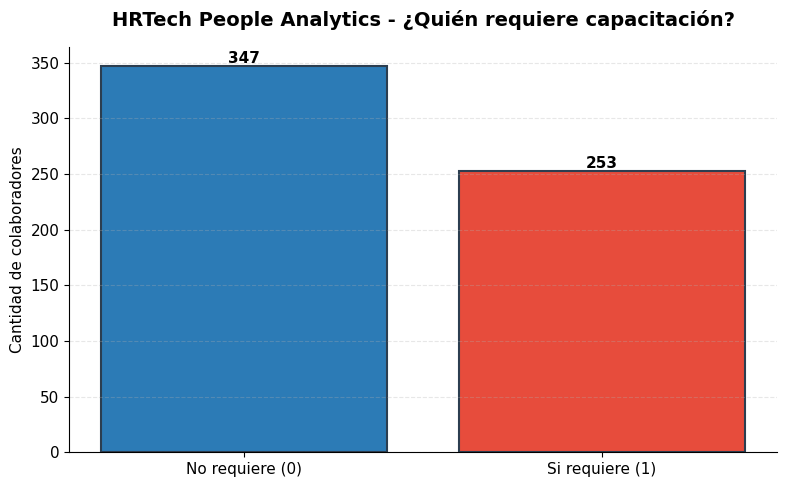

In [ ]:
# GRÁFICO 1: Distribucion de la variable objetivo
conteo = df_g8["requiere_capacitacion"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(["No requiere (0)", "Si requiere (1)"], conteo.values,
                color=['#2c7bb6', '#e74c3c'], edgecolor='#2c3e50', linewidth=1.5)

for barra, valor in zip(barras, conteo.values):
    ax.text(barra.get_x() + barra.get_width()/2., barra.get_height(),
            f'{valor}', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('HRTech People Analytics - ¿Quién requiere capacitación?', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Cantidad de colaboradores', fontsize=11)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')

plt.tight_layout()
plt.show()

FACTORES PROMEDIO SEGÚN LA NECESIDAD DE CAPACITACIÓN:
                       desempeño  satisfaccion  horas_capacitacion  horas_extra
requiere_capacitacion                                                          
0                          82.33          3.19                9.24         7.61
1                          76.28          2.50                8.66         8.76


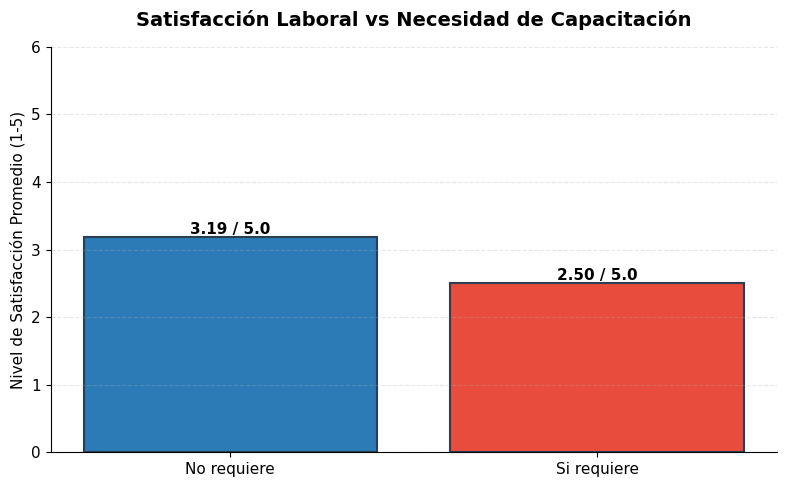


HALLAZGOS (calculados sobre df_g8, no escritos a mano):
   • desempeño: 76.28 en quienes requieren capacitación vs 82.33 en quienes no (menor en quienes requieren)
   • satisfaccion: 2.50 en quienes requieren capacitación vs 3.19 en quienes no (menor en quienes requieren)
   • horas_capacitacion: 8.66 en quienes requieren capacitación vs 9.24 en quienes no (menor en quienes requieren)
   • horas_extra: 8.76 en quienes requieren capacitación vs 7.61 en quienes no (mayor en quienes requieren)


In [ ]:
# COMPARAR FACTORES ENTRE LOS QUE REQUIEREN Y NO REQUIEREN CAPACITACIÓN
promedios = df_g8.groupby("requiere_capacitacion")[["desempeño", "satisfaccion", "horas_capacitacion", "horas_extra"]].mean()

print("FACTORES PROMEDIO SEGÚN LA NECESIDAD DE CAPACITACIÓN:")
print("=" * 50)
print(promedios.round(2).to_string())

# Gráfico comparativo de la satisfacción
fig, ax = plt.subplots(figsize=(8, 5))
categorias = ['No requiere', 'Si requiere']
valores = [promedios.loc[0, 'satisfaccion'], promedios.loc[1, 'satisfaccion']]
barras = ax.bar(categorias, valores, color=['#2c7bb6', '#e74c3c'], edgecolor='#2c3e50', linewidth=1.5)

for barra, valor in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width()/2., barra.get_height(),
            f'{valor:.2f} / 5.0', ha='center', va='bottom', fontsize=11, fontweight='bold')

ax.set_title('Satisfacción Laboral vs Necesidad de Capacitación', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Nivel de Satisfacción Promedio (1-5)', fontsize=11)
ax.grid(True, alpha=0.3, axis='y', linestyle='--')
ax.set_ylim(0, 6)

plt.tight_layout()
plt.show()

print("\nHALLAZGOS (calculados sobre df_g8, no escritos a mano):")
for var in promedios.columns:
    si, no = promedios.loc[1, var], promedios.loc[0, var]
    sentido = "mayor" if si > no else "menor"
    print(f"   • {var}: {si:.2f} en quienes requieren capacitación vs {no:.2f} en quienes no ({sentido} en quienes requieren)")

In [ ]:
# 5.2.1 DEFINIR VARIABLES PREDICTORAS (X) Y OBJETIVO (y)

# CORRECCIÓN: Se utiliza el DataFrame sintético df_g8 en lugar del original df, para incluir todas las variables simuladas
df_modelo = pd.get_dummies(df_g8, columns=["departamento"], drop_first=True, dtype=int)

features = [
    "edad",
    "desempeño",
    "salario",
    "tiempo_empresa_anios",
    "horas_capacitacion",
    "satisfaccion",
    "horas_extra",
    "curso_aprobado",
] + [c for c in df_modelo.columns if c.startswith("departamento_")]

X = df_modelo[features]
y = df_modelo["requiere_capacitacion"]

print("VARIABLES DEFINIDAS:")
print("=" * 60)
print(f"Variables predictoras (X): {len(features)}")
for i, f in enumerate(features, 1):
    print(f"   {i}. {f}")
print("\nTRANSFORMACIONES:")
print("   • Numéricas (edad, desempeño, salario, tiempo, horas, satisfacción): Normalización (StandardScaler)")
print("   • Categórica (departamento): One-Hot Encoding (get_dummies); las dummies también pasan por StandardScaler")
print("   • Booleana (curso_aprobado): codificada 0/1; el Pipeline también la normaliza con StandardScaler")
print(f"\nVariable objetivo (y): requiere_capacitacion")
print(f"\nDimensiones:")
print(f"   X: {X.shape}")
print(f"   y: {y.shape}")

VARIABLES DEFINIDAS:
Variables predictoras (X): 12
   1. edad
   2. desempeño
   3. salario
   4. tiempo_empresa_anios
   5. horas_capacitacion
   6. satisfaccion
   7. horas_extra
   8. curso_aprobado
   9. departamento_IT
   10. departamento_Marketing
   11. departamento_RRHH
   12. departamento_Ventas

TRANSFORMACIONES:
   • Numéricas (edad, desempeño, salario, tiempo, horas, satisfacción): Normalización (StandardScaler)
   • Categórica (departamento): One-Hot Encoding (get_dummies); las dummies también pasan por StandardScaler
   • Booleana (curso_aprobado): codificada 0/1; el Pipeline también la normaliza con StandardScaler

Variable objetivo (y): requiere_capacitacion

Dimensiones:
   X: (600, 12)
   y: (600,)


In [ ]:
# 5.3 DIVISIÓN DE DATOS 70 / 15 / 15

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print("DIVISIÓN 70 / 15 / 15")
print("=" * 60)
print(f"Total de registros: {len(X)}")
print(f"Entrenamiento: {len(X_train)} registros (70%) -> Entrenar el modelo")
print(f"Validación:    {len(X_val)} registros (15%) -> Ajustar hiperparámetros")
print(f"Prueba:        {len(X_test)} registros (15%) -> Evaluar el rendimiento final")

DIVISIÓN 70 / 15 / 15
Total de registros: 600
Entrenamiento: 420 registros (70%) -> Entrenar el modelo
Validación:    90 registros (15%) -> Ajustar hiperparámetros
Prueba:        90 registros (15%) -> Evaluar el rendimiento final


In [ ]:
# CONSTRUIR BASELINE
# Estrategia: predecir siempre la clase más frecuente del entrenamiento

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

pred_baseline = baseline.predict(X_test)

acc_base = accuracy_score(y_test, pred_baseline)
f1_base = f1_score(y_test, pred_baseline, zero_division=0)

print("BASELINE (Clase más frecuente)")
print("=" * 60)
print(f"Clase más frecuente: {y_train.mode()[0]}")
print(f"\nMÉTRICAS DEL BASELINE:")
print(f"   Accuracy: {acc_base:.4f}")
print(f"   F1-Score: {f1_base:.4f}")

BASELINE (Clase más frecuente)
Clase más frecuente: 0

MÉTRICAS DEL BASELINE:
   Accuracy: 0.5444
   F1-Score: 0.0000


In [ ]:
# 5.4.1 ENTRENAR MODELO DE REGRESIÓN LOGÍSTICA

modelo = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(random_state=42))
])

modelo.fit(X_train, y_train)

print("Modelo entrenado:")
print(modelo)

# Revisar el modelo en el conjunto de VALIDACIÓN
pred_val = modelo.predict(X_val)
print("\nRESULTADO EN VALIDACIÓN:")
print(f"   Accuracy: {accuracy_score(y_val, pred_val):.4f}")
print(f"   F1-Score: {f1_score(y_val, pred_val):.4f}")

Modelo entrenado:
Pipeline(steps=[('scaler', StandardScaler()),
                ('clf', LogisticRegression(random_state=42))])

RESULTADO EN VALIDACIÓN:
   Accuracy: 0.7556
   F1-Score: 0.6857


In [ ]:
# 5.4.2 PREDICCIONES EN EL CONJUNTO DE PRUEBA
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

resultados = pd.DataFrame({
    "id_empleado": df_modelo.loc[X_test.index, "id_empleado"].values,
    "real": y_test.values,
    "prediccion": y_pred,
    "probabilidad": y_prob.round(3)
})
resultados["acierto"] = resultados["real"] == resultados["prediccion"]

print("PRIMERAS 10 PREDICCIONES:")
print(resultados.head(10).to_string(index=False))

PRIMERAS 10 PREDICCIONES:
 id_empleado  real  prediccion  probabilidad  acierto
          87     1           1         0.843     True
         507     1           0         0.257    False
         333     0           1         0.856    False
         560     1           1         0.761     True
         118     1           1         0.627     True
         235     0           0         0.051     True
         369     0           0         0.406     True
          82     1           1         0.636     True
         585     0           0         0.087     True
         495     0           0         0.202     True


In [ ]:
# 5.5 MÉTRICAS DE EVALUACIÓN Y COMPARACIÓN CON EL BASELINE

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

comparacion = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Regresión Logística": [accuracy, precision, recall, f1, roc_auc],
    "Baseline": [acc_base,
                 precision_score(y_test, pred_baseline, zero_division=0),
                 recall_score(y_test, pred_baseline),
                 f1_base,
                 0.5],
    "Interpretación": ["Precisión global",
                       "Precisión de los positivos",
                       "Cobertura de los positivos",
                       "Balance entre precision y recall",
                       "Capacidad de discriminación"]
})

print("COMPARACIÓN BASELINE vs MODELO:")
print("=" * 70)
print(comparacion.round(4).to_string(index=False))

print(f"\nMEJORA DEL MODELO vs BASELINE:")
print(f"   Accuracy: {(accuracy - acc_base) * 100:.1f} puntos porcentuales más")

COMPARACIÓN BASELINE vs MODELO:
  Métrica  Regresión Logística  Baseline                   Interpretación
 Accuracy               0.7000    0.5444                 Precisión global
Precision               0.6750    0.0000       Precisión de los positivos
   Recall               0.6585    0.0000       Cobertura de los positivos
 F1-Score               0.6667    0.0000 Balance entre precision y recall
  ROC-AUC               0.7511    0.5000      Capacidad de discriminación

MEJORA DEL MODELO vs BASELINE:
   Accuracy: 15.6 puntos porcentuales más


In [ ]:
# 5.6.1 COEFICIENTES DEL MODELO

coeficientes = pd.DataFrame({
    "variable": features,
    "coeficiente": modelo.named_steps['clf'].coef_[0]
}).sort_values("coeficiente", key=abs, ascending=False)

# Importancia según el tamaño del coeficiente
coeficientes["importancia"] = np.where(coeficientes["coeficiente"].abs() >= 0.8, "Alta",
                              np.where(coeficientes["coeficiente"].abs() >= 0.3, "Media", "Baja"))

print("COEFICIENTES DEL MODELO:")
print("=" * 60)
print(coeficientes.round(4).to_string(index=False))

print(f"\nIntercepto (b0): {modelo.named_steps['clf'].intercept_[0]:.4f}")
print("\nINTERPRETACIÓN:")
print("   • Coeficiente positivo: la variable aumenta la probabilidad de requerir capacitación")
print("   • Coeficiente negativo: la variable disminuye la probabilidad de requerir capacitación")
print("   • Mientras más grande el valor (sin importar el signo), más influye la variable")

COEFICIENTES DEL MODELO:
              variable  coeficiente importancia
             desempeño      -0.9106        Alta
          satisfaccion      -0.6083       Media
    horas_capacitacion      -0.4130       Media
           horas_extra       0.3770       Media
        curso_aprobado      -0.1324        Baja
               salario      -0.1003        Baja
  tiempo_empresa_anios      -0.0828        Baja
                  edad       0.0795        Baja
   departamento_Ventas       0.0751        Baja
       departamento_IT      -0.0259        Baja
     departamento_RRHH      -0.0192        Baja
departamento_Marketing      -0.0057        Baja

Intercepto (b0): -0.4485

INTERPRETACIÓN:
   • Coeficiente positivo: la variable aumenta la probabilidad de requerir capacitación
   • Coeficiente negativo: la variable disminuye la probabilidad de requerir capacitación
   • Mientras más grande el valor (sin importar el signo), más influye la variable


MATRIZ DE CONFUSIÓN:
                    Predicho negativo   Predicho positivo
   Real negativo         TN = 36             FP = 13
   Real positivo         FN = 14             TP = 27


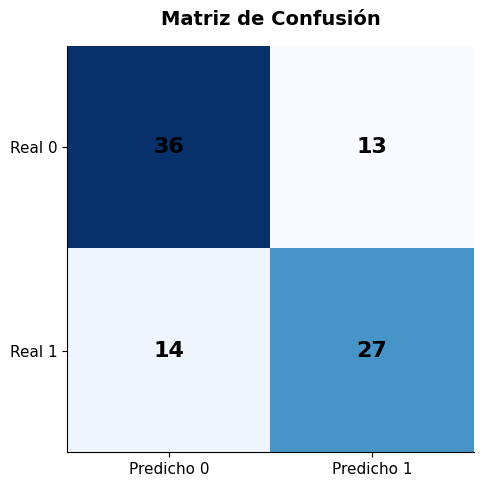

OBSERVACIONES:
   • TP: colaboradores que sí requieren capacitación y el modelo los detectó
   • FN: colaboradores que requieren capacitación pero el modelo NO los detectó
   • FP: el modelo dijo que requieren capacitación, pero en realidad no


In [ ]:
# GRÁFICO: Matriz de confusión

cm = confusion_matrix(y_test, y_pred)

print("MATRIZ DE CONFUSIÓN:")
print("=" * 50)
print(f"                    Predicho negativo   Predicho positivo")
print(f"   Real negativo         TN = {cm[0, 0]:<12}   FP = {cm[0, 1]}")
print(f"   Real positivo         FN = {cm[1, 0]:<12}   TP = {cm[1, 1]}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=16, fontweight='bold')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Predicho 0', 'Predicho 1'])
ax.set_yticks([0, 1])
ax.set_yticklabels(['Real 0', 'Real 1'])
ax.set_title('Matriz de Confusión', fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

print("OBSERVACIONES:")
print("   • TP: colaboradores que sí requieren capacitación y el modelo los detectó")
print("   • FN: colaboradores que requieren capacitación pero el modelo NO los detectó")
print("   • FP: el modelo dijo que requieren capacitación, pero en realidad no")

In [ ]:
# ANÁLISIS DE ERRORES
errores = resultados[resultados["acierto"] == False]

print(f"Total de errores: {len(errores)} de {len(resultados)}")
print(f"   Falsos positivos (FP): {((resultados['real'] == 0) & (resultados['prediccion'] == 1)).sum()}")
print(f"   Falsos negativos (FN): {((resultados['real'] == 1) & (resultados['prediccion'] == 0)).sum()}")

print(f"\nTOP 5 ERRORES CON MAYOR PROBABILIDAD:")
print(errores.sort_values("probabilidad", ascending=False).head(5).to_string(index=False))

Total de errores: 27 de 90
   Falsos positivos (FP): 13
   Falsos negativos (FN): 14

TOP 5 ERRORES CON MAYOR PROBABILIDAD:
 id_empleado  real  prediccion  probabilidad  acierto
         333     0           1         0.856    False
         178     0           1         0.790    False
          80     0           1         0.760    False
         438     0           1         0.739    False
         350     0           1         0.723    False


In [ ]:
print("NOTA: las métricas provienen de datos SINTÉTICOS generados con las mismas variables predictoras;")
print("      sirven para demostrar la metodología, no para tomar decisiones sobre personas reales.\n")
# 5.6 INTERPRETACIÓN PRELIMINAR Y LIMITACIONES
top3 = coeficientes["variable"].head(3).tolist()

print("INTERPRETACIÓN:")
print("=" * 60)
print(f"El modelo de Regresión Logística alcanza un F1-Score de {f1:.2f} y un ROC-AUC de {roc_auc:.2f},")
print(f"lo que indica que distingue de forma aceptable a los colaboradores que requieren capacitación")
print(f"(el baseline tiene F1-Score de {f1_base:.2f}). Las variables más influyentes son {', '.join(top3)},")
print(f"lo que sugiere que RRHH debe priorizar a quienes tienen bajo desempeño y baja satisfacción.")
print(f"Sin embargo, deben considerarse las siguientes limitaciones:")

print("\nLIMITACIONES DEL MODELO:")
print("1. Tamaño de la muestra: el dataset real solo tiene 10 colaboradores; se usaron 600 datos sintéticos.")
print("2. Variables omitidas: no se incluyen factores como liderazgo del jefe o carga de trabajo real.")
print("3. Supuestos del modelo: la regresión logística supone relaciones lineales entre variables y probabilidad.")
print("4. Capacidad de generalización: debe validarse con datos reales antes de usarse para tomar decisiones.")
print("5. Circularidad: la etiqueta se generó con una fórmula de las mismas variables predictoras; el AUC está acotado por esa fórmula y no es evidencia de poder predictivo real.")


NOTA: las métricas provienen de datos SINTÉTICOS generados con las mismas variables predictoras;
      sirven para demostrar la metodología, no para tomar decisiones sobre personas reales.

INTERPRETACIÓN:
El modelo de Regresión Logística alcanza un F1-Score de 0.67 y un ROC-AUC de 0.75,
lo que indica que distingue de forma aceptable a los colaboradores que requieren capacitación
(el baseline tiene F1-Score de 0.00). Las variables más influyentes son desempeño, satisfaccion, horas_capacitacion,
lo que sugiere que RRHH debe priorizar a quienes tienen bajo desempeño y baja satisfacción.
Sin embargo, deben considerarse las siguientes limitaciones:

LIMITACIONES DEL MODELO:
1. Tamaño de la muestra: el dataset real solo tiene 10 colaboradores; se usaron 600 datos sintéticos.
2. Variables omitidas: no se incluyen factores como liderazgo del jefe o carga de trabajo real.
3. Supuestos del modelo: la regresión logística supone relaciones lineales entre variables y probabilidad.
4. Capacidad de 

In [ ]:
# GUARDAR RESULTADOS
from pathlib import Path

BASE = Path('/content/')
(BASE / 'datos' / 'procesados').mkdir(parents=True, exist_ok=True)
(BASE / 'documentos').mkdir(parents=True, exist_ok=True)

# Guardar predicciones
ruta_pred = BASE / 'datos' / 'procesados' / 'predicciones_hrtech_people_analytics.csv'
resultados.to_csv(ruta_pred, index=False, encoding='utf-8')
print(f"Predicciones guardadas: {ruta_pred.name}")

# Guardar métricas
ruta_metricas = BASE / 'documentos' / 'metricas_hrtech_people_analytics.csv'
comparacion.to_csv(ruta_metricas, index=False, encoding='utf-8')
print(f"Métricas guardadas: {ruta_metricas.name}")

# Guardar coeficientes
ruta_coef = BASE / 'documentos' / 'coeficientes_hrtech_people_analytics.csv'
coeficientes.to_csv(ruta_coef, index=False, encoding='utf-8')
print(f"Coeficientes guardados: {ruta_coef.name}")

# Descargar
from google.colab import files
files.download(str(ruta_pred))
files.download(str(ruta_metricas))
files.download(str(ruta_coef))
print("\nArchivos descargados")

Predicciones guardadas: predicciones_hrtech_people_analytics.csv
Métricas guardadas: metricas_hrtech_people_analytics.csv
Coeficientes guardados: coeficientes_hrtech_people_analytics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Archivos descargados


#**Guia 9**

In [ ]:
#Entrenamiento de modelos de Machine Learning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modelos
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Preprocesamiento, validación y clonación
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.base import clone

# Métricas
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

# Persistencia
import joblib

# Configuración global
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print("Librerías importadas correctamente")
print(f"   - numpy: {np.__version__}")
print(f"   - pandas: {pd.__version__}")
print(f"   - scikit-learn: {__import__('sklearn').__version__}")
print(f"\nSemilla de reproducibilidad: {RANDOM_STATE}")

Librerías importadas correctamente
   - numpy: 2.4.6
   - pandas: 2.2.3
   - scikit-learn: 1.6.1

Semilla de reproducibilidad: 42


In [ ]:
#CELDA 2: Reconstruir dataset de Guía 8
# Mismas llamadas aleatorias y en el mismo orden que la Guía 8 (con semilla 42),
# para obtener exactamente los mismos 600 colaboradores.
n = 600

df_g8 = pd.DataFrame({"id_empleado": range(1, n + 1)})
df_g8["departamento"] = np.random.choice(["IT", "RRHH", "Finanzas", "Marketing", "Ventas"], n)
df_g8["edad"] = np.random.randint(21, 56, n)
df_g8["desempeño"] = np.random.normal(80, 9, n).clip(50, 100).round(0)
df_g8["salario"] = np.random.choice([550, 600, 650, 700, 750, 800, 900, 950], n)
df_g8["tiempo_empresa_anios"] = np.random.randint(0, 11, n)
df_g8["horas_capacitacion"] = np.random.choice([6, 8, 10, 12], n)
df_g8["satisfaccion"] = np.random.randint(1, 6, n)
df_g8["horas_extra"] = np.random.randint(0, 16, n)
df_g8["curso_aprobado"] = np.random.binomial(1, 0.75, n)

# Fórmula generadora (idéntica a Guía 8)
riesgo = (
    - 0.10 * (df_g8["desempeño"] - 80)
    - 0.45 * (df_g8["satisfaccion"] - 3)
    - 0.15 * (df_g8["horas_capacitacion"] - 9)
    + 0.06 * (df_g8["horas_extra"] - 7)
    - 0.60 * df_g8["curso_aprobado"]
    + np.random.normal(0, 0.8, n)
)
probabilidad = 1 / (1 + np.exp(-riesgo))
df_g8["requiere_capacitacion"] = np.random.binomial(1, probabilidad)

# One-Hot Encoding de departamento (idéntico a Guía 8)
df_modelo = pd.get_dummies(df_g8, columns=["departamento"], drop_first=True, dtype=int)

print(f"Dataset reconstruido: {df_modelo.shape[0]} filas, {df_modelo.shape[1]} columnas")
print(f"Colaboradores que requieren capacitación: {df_modelo['requiere_capacitacion'].mean()*100:.1f} %")
print(f"\nPrimeras 3 filas:")
print(df_modelo.head(3).to_string())

Dataset reconstruido: 600 filas, 14 columnas
Colaboradores que requieren capacitación: 42.2 %

Primeras 3 filas:
   id_empleado  edad  desempeño  salario  tiempo_empresa_anios  horas_capacitacion  satisfaccion  horas_extra  curso_aprobado  requiere_capacitacion  departamento_IT  departamento_Marketing  departamento_RRHH  departamento_Ventas
0            1    31       84.0      950                     2                  10             2            1               1                      1                0                       1                  0                    0
1            2    55       78.0      700                    10                   8             4           12               1                      0                0                       0                  0                    1
2            3    39       90.0      550                     7                  10             1           12               1                      0                0                       0        

In [ ]:
#CELDA 3: Definir X, y y split 80/20 estratificado
features = [
    "edad", "desempeño", "salario", "tiempo_empresa_anios",
    "horas_capacitacion", "satisfaccion", "horas_extra", "curso_aprobado"
] + [c for c in df_modelo.columns if c.startswith("departamento_")]

X = df_modelo[features]
y = df_modelo["requiere_capacitacion"]

# Split 80/20 estratificado (mantiene la proporción de clases en train y test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("SPLIT 80/20 ESTRATIFICADO")
print("=" * 55)
print(f"Entrenamiento: {X_train.shape}")
print(f"Prueba:        {X_test.shape}")
print(f"\n% positivos en train: {y_train.mean()*100:.1f} %")
print(f"% positivos en test:  {y_test.mean()*100:.1f} %")

SPLIT 80/20 ESTRATIFICADO
Entrenamiento: (480, 12)
Prueba:        (120, 12)

% positivos en train: 42.1 %
% positivos en test:  42.5 %


In [ ]:
#CELDA 4: Catálogo de modelos candidatos
modelos = {
    "Baseline clase frecuente": DummyClassifier(strategy="most_frequent"),
    "Regresión logística":      Pipeline([
                                    ("scaler", StandardScaler()),
                                    ("clf", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
                                ]),
    "Árbol de decisión":        DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":            RandomForestClassifier(random_state=RANDOM_STATE)
}

print("MODELOS EN EL CATÁLOGO")
print("=" * 55)
for i, nombre in enumerate(modelos.keys(), 1):
    print(f"  {i}. {nombre}")

MODELOS EN EL CATÁLOGO
  1. Baseline clase frecuente
  2. Regresión logística
  3. Árbol de decisión
  4. Random Forest


In [ ]:
#CELDA 5: Función de métricas y evaluación holdout
def metricas_clasificacion(modelo, X_, y_real):
    """Calcula Accuracy, Precision, Recall, F1 y ROC-AUC."""
    y_pred = modelo.predict(X_)
    y_prob = modelo.predict_proba(X_)[:, 1]
    return {
        "Accuracy":  accuracy_score(y_real, y_pred),
        "Precision": precision_score(y_real, y_pred, zero_division=0),
        "Recall":    recall_score(y_real, y_pred, zero_division=0),
        "F1":        f1_score(y_real, y_pred, zero_division=0),
        "ROC_AUC":   roc_auc_score(y_real, y_prob)
    }


def evaluar_holdout(nombre, estimador):
    """
    Entrena un modelo clonado, evalúa en train y test,
    y devuelve (modelo, fila_resultado, predicciones_test).
    """
    modelo = clone(estimador)
    modelo.fit(X_train, y_train)

    mt = metricas_clasificacion(modelo, X_train, y_train)
    mp = metricas_clasificacion(modelo, X_test,  y_test)

    fila = {
        "Modelo":     nombre,
        "F1_train":   mt["F1"],
        "Acc_test":   mp["Accuracy"],
        "Prec_test":  mp["Precision"],
        "Rec_test":   mp["Recall"],
        "F1_test":    mp["F1"],
        "AUC_test":   mp["ROC_AUC"],
        "Brecha_F1":  mt["F1"] - mp["F1"]     # train - test: si es grande, hay sobreajuste
    }

    return modelo, fila, modelo.predict(X_test)


print("Funciones definidas correctamente")

Funciones definidas correctamente


In [ ]:
#CELDA 6: Entrenar y evaluar todos los modelos (holdout)
resultados_holdout = []
modelos_entrenados = {}
predicciones       = {}

for nombre, estimador in modelos.items():
    modelo, fila, pred = evaluar_holdout(nombre, estimador)
    modelos_entrenados[nombre] = modelo
    predicciones[nombre]       = pred
    resultados_holdout.append(fila)

tabla_holdout = pd.DataFrame(resultados_holdout)

print("RESULTADOS EN HOLDOUT (sin ordenar)")
print("=" * 95)
print(tabla_holdout.round(3).to_string(index=False))

RESULTADOS EN HOLDOUT (sin ordenar)
                  Modelo  F1_train  Acc_test  Prec_test  Rec_test  F1_test  AUC_test  Brecha_F1
Baseline clase frecuente     0.000     0.575      0.000     0.000    0.000     0.500      0.000
     Regresión logística     0.656     0.692      0.652     0.588    0.619     0.747      0.038
       Árbol de decisión     1.000     0.567      0.492     0.569    0.527     0.567      0.473
           Random Forest     1.000     0.708      0.667     0.627    0.646     0.743      0.354


In [ ]:
#CELDA 7: Ordenar por F1_test y mejora vs baseline
f1_baseline = tabla_holdout.loc[
    tabla_holdout["Modelo"] == "Baseline clase frecuente", "F1_test"
].iloc[0]

# El baseline suele tener F1 = 0, así que la mejora se mide en puntos, no en %
tabla_holdout["Mejora_F1_vs_baseline"] = tabla_holdout["F1_test"] - f1_baseline

tabla_holdout = tabla_holdout.sort_values("F1_test", ascending=False).reset_index(drop=True)

print(f"F1 del baseline: {f1_baseline:.3f}")
print("\nTABLA COMPARATIVA (ordenada por F1_test)")
print("=" * 105)
print(tabla_holdout.round(3).to_string(index=False))

F1 del baseline: 0.000

TABLA COMPARATIVA (ordenada por F1_test)
                  Modelo  F1_train  Acc_test  Prec_test  Rec_test  F1_test  AUC_test  Brecha_F1  Mejora_F1_vs_baseline
           Random Forest     1.000     0.708      0.667     0.627    0.646     0.743      0.354                  0.646
     Regresión logística     0.656     0.692      0.652     0.588    0.619     0.747      0.038                  0.619
       Árbol de decisión     1.000     0.567      0.492     0.569    0.527     0.567      0.473                  0.527
Baseline clase frecuente     0.000     0.575      0.000     0.000    0.000     0.500      0.000                  0.000


In [ ]:
#CELDA 8: Diagnóstico de sobreajuste (brecha train/test)
print("DIAGNÓSTICO DE SOBREAJUSTE")
print("=" * 75)

for _, row in tabla_holdout.iterrows():
    nombre = row["Modelo"]
    brecha = row["Brecha_F1"]
    f1_tr  = row["F1_train"]

    if f1_tr >= 0.99 and brecha > 0.15:
        señal = "(ROJO) Posible sobreajuste severo (F1_train ≈ 1)"
    elif brecha > 0.10:
        señal = "(NARANJA) Posible sobreajuste (brecha F1 > 0.10)"
    elif brecha < 0:
        señal = "(AMARILLO) Brecha negativa (test más fácil que train)"
    else:
        señal = "(VERDE) Brecha razonable"

    print(f"\n{nombre}")
    print(f"   F1_train: {f1_tr:>6.3f}")
    print(f"   F1_test:  {row['F1_test']:>6.3f}")
    print(f"   Brecha:   {brecha:>6.3f}")
    print(f"   → {señal}")

DIAGNÓSTICO DE SOBREAJUSTE

Random Forest
   F1_train:  1.000
   F1_test:   0.646
   Brecha:    0.354
   → (ROJO) Posible sobreajuste severo (F1_train ≈ 1)

Regresión logística
   F1_train:  0.656
   F1_test:   0.619
   Brecha:    0.038
   → (VERDE) Brecha razonable

Árbol de decisión
   F1_train:  1.000
   F1_test:   0.527
   Brecha:    0.473
   → (ROJO) Posible sobreajuste severo (F1_train ≈ 1)

Baseline clase frecuente
   F1_train:  0.000
   F1_test:   0.000
   Brecha:    0.000
   → (VERDE) Brecha razonable


In [ ]:
#CELDA 9: Crear StratifiedKFold y visualizar folds
# No hay fechas en el dataset, así que se usa validación cruzada estratificada
# (con mezcla) en lugar de TimeSeriesSplit.
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("FOLDS DE VALIDACIÓN CRUZADA ESTRATIFICADA")
print("=" * 75)
print(f"{'Fold':<6}{'Filas train':<14}{'Filas val':<14}{'% positivos train':<20}{'% positivos val':<16}")

for fold, (idx_tr, idx_val) in enumerate(skf.split(X_train, y_train), 1):
    print(
        f"{fold:<6}"
        f"{len(idx_tr):<14}"
        f"{len(idx_val):<14}"
        f"{y_train.iloc[idx_tr].mean()*100:<20.1f}"
        f"{y_train.iloc[idx_val].mean()*100:<16.1f}"
    )

print(f"\nTotal de filas en X_train: {len(X_train)}")
print(f"Filas por fold de validación: ~{len(X_train) // skf.get_n_splits()}")

FOLDS DE VALIDACIÓN CRUZADA ESTRATIFICADA
Fold  Filas train   Filas val     % positivos train   % positivos val 
1     384           96            41.9                42.7            
2     384           96            41.9                42.7            
3     384           96            42.2                41.7            
4     384           96            42.2                41.7            
5     384           96            42.2                41.7            

Total de filas en X_train: 480
Filas por fold de validación: ~96


In [ ]:
#CELDA 10: Función de validación cruzada
def validar_cruzada(nombre, estimador):
    """Aplica StratifiedKFold a un estimador y devuelve métricas por fold."""
    filas = []

    for fold, (idx_tr, idx_val) in enumerate(skf.split(X_train, y_train), 1):
        X_tr,  X_val = X_train.iloc[idx_tr], X_train.iloc[idx_val]
        y_tr,  y_val = y_train.iloc[idx_tr], y_train.iloc[idx_val]

        m = clone(estimador)
        m.fit(X_tr, y_tr)

        pred_tr  = m.predict(X_tr)
        pred_val = m.predict(X_val)
        prob_val = m.predict_proba(X_val)[:, 1]

        filas.append({
            "Modelo":   nombre,
            "Fold":     fold,
            "F1_train": f1_score(y_tr,  pred_tr,  zero_division=0),
            "F1_val":   f1_score(y_val, pred_val, zero_division=0),
            "Acc_val":  accuracy_score(y_val, pred_val),
            "AUC_val":  roc_auc_score(y_val, prob_val)
        })

    return pd.DataFrame(filas)


print("Función 'validar_cruzada' definida correctamente")

Función 'validar_cruzada' definida correctamente


In [ ]:
#CELDA 11: Ejecutar validación cruzada
validaciones = []
for nombre, estimador in modelos.items():
    validaciones.append(validar_cruzada(nombre, estimador))

df_cv = pd.concat(validaciones, ignore_index=True)

print("DETALLE DE VALIDACIÓN CRUZADA")
print("=" * 75)
print(df_cv.round(3).to_string(index=False))

DETALLE DE VALIDACIÓN CRUZADA
                  Modelo  Fold  F1_train  F1_val  Acc_val  AUC_val
Baseline clase frecuente     1     0.000   0.000    0.573    0.500
Baseline clase frecuente     2     0.000   0.000    0.573    0.500
Baseline clase frecuente     3     0.000   0.000    0.583    0.500
Baseline clase frecuente     4     0.000   0.000    0.583    0.500
Baseline clase frecuente     5     0.000   0.000    0.583    0.500
     Regresión logística     1     0.647   0.648    0.740    0.795
     Regresión logística     2     0.667   0.649    0.729    0.727
     Regresión logística     3     0.662   0.585    0.646    0.699
     Regresión logística     4     0.654   0.690    0.729    0.818
     Regresión logística     5     0.667   0.568    0.667    0.732
       Árbol de decisión     1     1.000   0.596    0.604    0.614
       Árbol de decisión     2     1.000   0.532    0.615    0.602
       Árbol de decisión     3     1.000   0.500    0.562    0.557
       Árbol de decisión     4  

In [ ]:
#CELDA 12: Resumen por modelo (media y std)
resumen_cv = (
    df_cv
    .groupby("Modelo")
    .agg(
        F1_cv_media   = ("F1_val",  "mean"),
        F1_cv_std     = ("F1_val",  "std"),
        Acc_cv_media  = ("Acc_val", "mean"),
        AUC_cv_media  = ("AUC_val", "mean")
    )
    .reset_index()
    .sort_values("F1_cv_media", ascending=False)
    .reset_index(drop=True)
)

print("RESUMEN DE VALIDACIÓN CRUZADA")
print("=" * 85)
print(resumen_cv.round(3).to_string(index=False))

RESUMEN DE VALIDACIÓN CRUZADA
                  Modelo  F1_cv_media  F1_cv_std  Acc_cv_media  AUC_cv_media
     Regresión logística        0.628      0.050         0.702         0.754
           Random Forest        0.565      0.066         0.669         0.703
       Árbol de decisión        0.540      0.040         0.600         0.594
Baseline clase frecuente        0.000      0.000         0.579         0.500


In [ ]:
#CELDA 13: Integrar holdout + CV y marcar candidatos
comparacion = tabla_holdout.merge(resumen_cv, on="Modelo", how="left")
comparacion = comparacion.sort_values("F1_test", ascending=False).reset_index(drop=True)

# Criterios de selección
comparacion["Supera_baseline"] = comparacion["Mejora_F1_vs_baseline"] > 0
comparacion["CV_estable"]      = (
    comparacion["F1_cv_std"] < comparacion["F1_cv_media"] * 0.25
)

columnas_mostrar = [
    "Modelo", "F1_test", "AUC_test", "Mejora_F1_vs_baseline",
    "F1_cv_media", "F1_cv_std", "Brecha_F1",
    "Supera_baseline", "CV_estable"
]

print("TABLA COMPARATIVA INTEGRADA")
print("=" * 110)
print(comparacion[columnas_mostrar].round(3).to_string(index=False))

TABLA COMPARATIVA INTEGRADA
                  Modelo  F1_test  AUC_test  Mejora_F1_vs_baseline  F1_cv_media  F1_cv_std  Brecha_F1  Supera_baseline  CV_estable
           Random Forest    0.646     0.743                  0.646        0.565      0.066      0.354             True        True
     Regresión logística    0.619     0.747                  0.619        0.628      0.050      0.038             True        True
       Árbol de decisión    0.527     0.567                  0.527        0.540      0.040      0.473             True        True
Baseline clase frecuente    0.000     0.500                  0.000        0.000      0.000      0.000            False       False


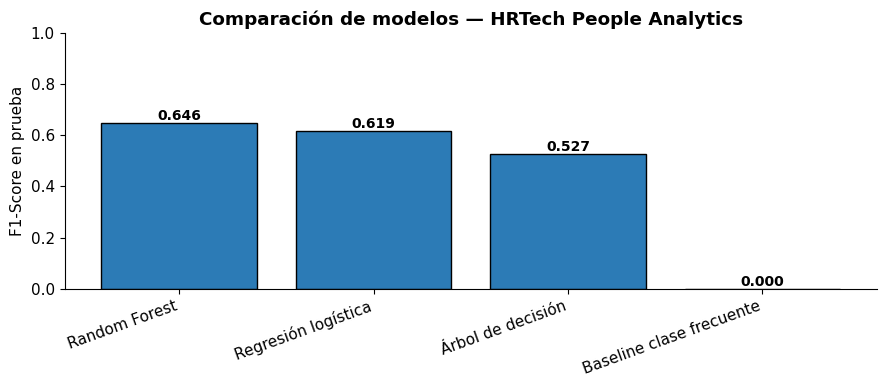

In [ ]:
#CELDA 14: Gráfico de barras F1_test por modelo
graf = comparacion.sort_values("F1_test", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4))
colores = ['#4781AD' if m == "Baseline clase frecuente" else '#2c7bb6'
           for m in graf["Modelo"]]

bars = ax.bar(graf["Modelo"], graf["F1_test"], color=colores, edgecolor='black')

# Etiquetas de valor sobre cada barra
for bar, val in zip(bars, graf["F1_test"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{val:.3f}", ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_ylabel("F1-Score en prueba")
ax.set_ylim(0, 1)
ax.set_title("Comparación de modelos — HRTech People Analytics", fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

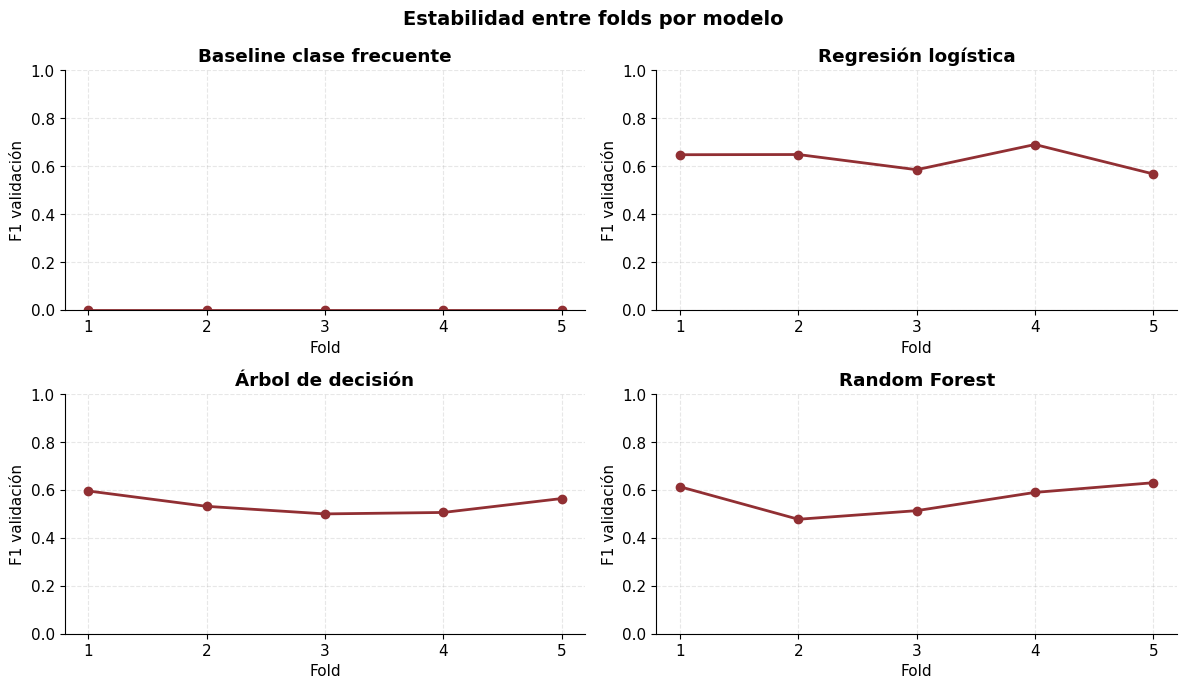

In [ ]:
#CELDA 15: Estabilidad entre folds (una gráfica por modelo)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes = axes.flatten()

for i, nombre in enumerate(df_cv["Modelo"].unique()):
    temp = df_cv[df_cv["Modelo"] == nombre]
    axes[i].plot(temp["Fold"], temp["F1_val"],
                 marker='o', linewidth=2, color='#912F33')
    axes[i].set_title(nombre, fontweight='bold')
    axes[i].set_xlabel("Fold")
    axes[i].set_ylabel("F1 validación")
    axes[i].set_ylim(0, 1)
    axes[i].grid(alpha=0.3, linestyle='--')
    axes[i].set_xticks(temp["Fold"].tolist())

plt.suptitle("Estabilidad entre folds por modelo", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
#CELDA 16: Seleccionar candidato provisional
candidatos = comparacion[comparacion["Supera_baseline"]].copy()

# Se ordena por F1_test y, en caso de empate, por AUC_test
candidato_ordenado = candidatos.sort_values(["F1_test", "AUC_test"], ascending=False)

nombre_candidato = candidato_ordenado.iloc[0]["Modelo"]
modelo_candidato = modelos_entrenados[nombre_candidato]
pred_candidato   = predicciones[nombre_candidato]
prob_candidato   = modelo_candidato.predict_proba(X_test)[:, 1]

print("CANDIDATO PROVISIONAL")
print("=" * 55)
print(f"  Modelo: {nombre_candidato}")
print(f"  F1_test:        {candidato_ordenado.iloc[0]['F1_test']:.3f}")
print(f"  Accuracy_test:  {candidato_ordenado.iloc[0]['Acc_test']:.3f}")
print(f"  Precision_test: {candidato_ordenado.iloc[0]['Prec_test']:.3f}")
print(f"  Recall_test:    {candidato_ordenado.iloc[0]['Rec_test']:.3f}")
print(f"  ROC-AUC_test:   {candidato_ordenado.iloc[0]['AUC_test']:.3f}")
print(f"  Mejora F1 vs baseline: {candidato_ordenado.iloc[0]['Mejora_F1_vs_baseline']:+.3f} puntos")

print(f"\nModelos que superan al baseline:")
for _, row in candidato_ordenado.iterrows():
    print(f"  - {row['Modelo']}: F1 = {row['F1_test']:.3f}")

CANDIDATO PROVISIONAL
  Modelo: Random Forest
  F1_test:        0.646
  Accuracy_test:  0.708
  Precision_test: 0.667
  Recall_test:    0.627
  ROC-AUC_test:   0.743
  Mejora F1 vs baseline: +0.646 puntos

Modelos que superan al baseline:
  - Random Forest: F1 = 0.646
  - Regresión logística: F1 = 0.619
  - Árbol de decisión: F1 = 0.527


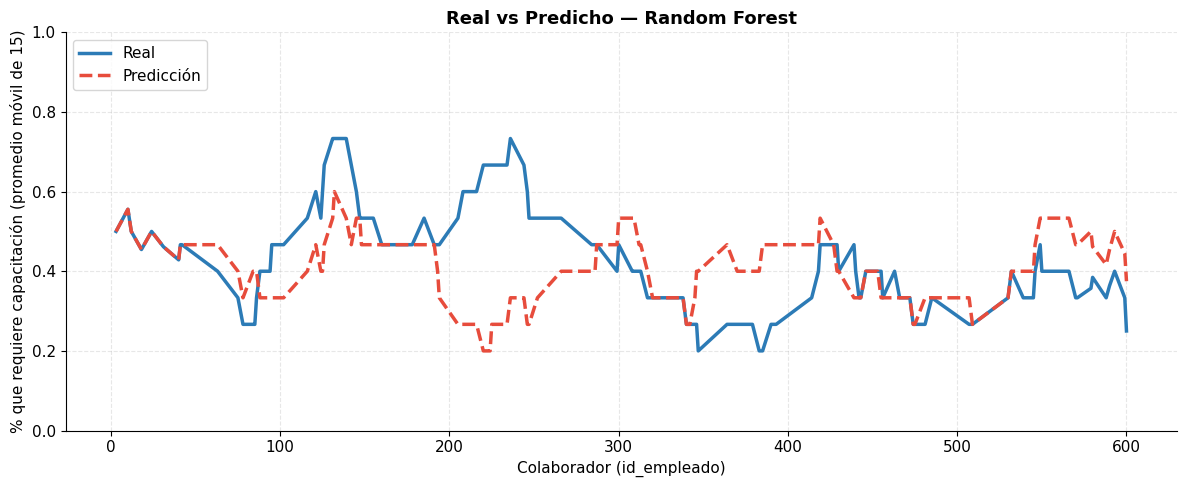

In [ ]:
#CELDA 17: Gráfico Real vs Predicho del candidato

VENTANA  = 15
ids_test = df_modelo.loc[X_test.index, "id_empleado"].values
orden    = np.argsort(ids_test)

real_mov = pd.Series(y_test.values[orden]).rolling(VENTANA, center=True, min_periods=1).mean()
pred_mov = pd.Series(pred_candidato[orden]).rolling(VENTANA, center=True, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(ids_test[orden], real_mov, label="Real",
        color='#2c7bb6', linewidth=2.5)
ax.plot(ids_test[orden], pred_mov, label="Predicción",
        color='#e74c3c', linewidth=2.5, linestyle='--')

ax.set_title(f"Real vs Predicho — {nombre_candidato}",
             fontsize=13, fontweight='bold')
ax.set_xlabel("Colaborador (id_empleado)")
ax.set_ylabel(f"% que requiere capacitación (promedio móvil de {VENTANA})")
ax.set_ylim(0, 1)
ax.legend(loc='upper left')
ax.grid(alpha=0.3, linestyle='--')
plt.tight_layout()
plt.show()

In [ ]:
#CELDA 18: Top 5 errores más graves del candidato
errores = pd.DataFrame({
    "id_empleado":  df_modelo.loc[X_test.index, "id_empleado"].values,
    "real":         y_test.values,
    "predicho":     pred_candidato,
    "probabilidad": prob_candidato.round(3)
})

errores["acierto"]   = errores["real"] == errores["predicho"]
errores["tipo_error"] = np.where(
    errores["acierto"], "Acierto",
    np.where(errores["real"] == 1, "FN (no detectado)", "FP (falsa alarma)")
)

# Gravedad = qué tan seguro estaba el modelo en su equivocación
errores["error_abs"] = (errores["real"] - errores["probabilidad"]).abs().round(3)

solo_errores = errores[~errores["acierto"]]

print("ESTADÍSTICAS DE ERROR")
print("=" * 55)
print(f"  Total de errores:         {len(solo_errores)} de {len(errores)} ({len(solo_errores)/len(errores)*100:.1f} %)")
print(f"  Falsos positivos (FP):    {(solo_errores['tipo_error'] == 'FP (falsa alarma)').sum()}")
print(f"  Falsos negativos (FN):    {(solo_errores['tipo_error'] == 'FN (no detectado)').sum()}")
print(f"  Error absoluto promedio:  {errores['error_abs'].mean():.3f}")

print(f"\nTOP 5 ERRORES MÁS GRAVES")
print("=" * 75)
print(solo_errores.nlargest(5, "error_abs").to_string(index=False))

print("\nNOTA: un FN es el error más costoso en este proyecto (un colaborador que necesita")
print("      capacitación y no fue detectado). Datos sintéticos: no usar para decisiones reales.")

ESTADÍSTICAS DE ERROR
  Total de errores:         35 de 120 (29.2 %)
  Falsos positivos (FP):    16
  Falsos negativos (FN):    19
  Error absoluto promedio:  0.413

TOP 5 ERRORES MÁS GRAVES
 id_empleado  real  predicho  probabilidad  acierto        tipo_error  error_abs
         220     1         0          0.17    False FN (no detectado)       0.83
         131     1         0          0.20    False FN (no detectado)       0.80
         390     0         1          0.79    False FP (falsa alarma)       0.79
         234     1         0          0.25    False FN (no detectado)       0.75
         507     1         0          0.29    False FN (no detectado)       0.71

NOTA: un FN es el error más costoso en este proyecto (un colaborador que necesita
      capacitación y no fue detectado). Datos sintéticos: no usar para decisiones reales.


In [ ]:
# Interpretación de variables del candidato
# Si el modelo es un Pipeline (ej. regresión logística con StandardScaler),
estimador_final = (modelo_candidato.steps[-1][1]
                   if isinstance(modelo_candidato, Pipeline) else modelo_candidato)

if hasattr(estimador_final, "coef_"):
    importancia = pd.DataFrame({
        "variable":   features,
        "valor":      estimador_final.coef_[0],
        "odds_ratio": np.exp(estimador_final.coef_[0])
    }).sort_values("valor", key=lambda s: s.abs(), ascending=False)

    print(f"COEFICIENTES — {nombre_candidato} (variables estandarizadas)")
    print("=" * 65)
    print(importancia.round(4).to_string(index=False))
    print(f"\nIntercepto: {estimador_final.intercept_[0]:.4f}")
    print("Coeficiente > 0: aumenta la probabilidad de requerir capacitación")
    print("Coeficiente < 0: la disminuye")

elif hasattr(estimador_final, "feature_importances_"):
    importancia = pd.DataFrame({
        "variable": features,
        "valor":    estimador_final.feature_importances_
    }).sort_values("valor", ascending=False)

    print(f"FEATURE IMPORTANCE — {nombre_candidato}")
    print("=" * 65)
    print(importancia.round(4).to_string(index=False))
    print(f"\nSuma de importancias: {importancia['valor'].sum():.4f}")
    print("NOTA: la importancia indica cuánto usa el modelo cada variable,")
    print("      no la dirección del efecto (no dice si sube o baja el riesgo).")

else:
    importancia = pd.DataFrame()
    print("El modelo no expone coeficientes ni importancias.")


FEATURE IMPORTANCE — Random Forest
              variable  valor
             desempeño 0.2227
           horas_extra 0.1420
                  edad 0.1368
          satisfaccion 0.1105
  tiempo_empresa_anios 0.1067
               salario 0.0938
    horas_capacitacion 0.0704
        curso_aprobado 0.0275
   departamento_Ventas 0.0233
       departamento_IT 0.0232
departamento_Marketing 0.0221
     departamento_RRHH 0.0211

Suma de importancias: 1.0000
NOTA: la importancia indica cuánto usa el modelo cada variable,
      no la dirección del efecto (no dice si sube o baja el riesgo).


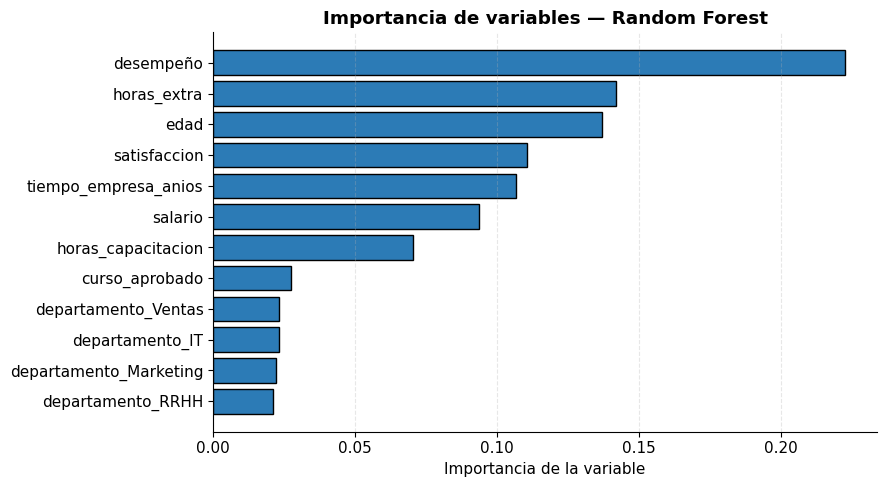

In [ ]:
# Gráfico de importancia de variables
if not importancia.empty:
    graf_imp = importancia.sort_values("valor", key=lambda s: s.abs(), ascending=True)

    fig, ax = plt.subplots(figsize=(9, 5))

    if "odds_ratio" in graf_imp.columns:
        # Regresión logística: el signo importa (rojo = sube el riesgo, azul = lo baja)
        colores = ['#912F33' if v > 0 else '#2c7bb6' for v in graf_imp["valor"]]
        ax.barh(graf_imp["variable"], graf_imp["valor"], color=colores, edgecolor='black')
        ax.axvline(0, color='black', linewidth=0.8)
        ax.set_xlabel("Coeficiente (rojo: aumenta el riesgo | azul: lo reduce)")
    else:
        # Random Forest / Árbol: solo magnitud
        ax.barh(graf_imp["variable"], graf_imp["valor"].abs(),
                color='#2c7bb6', edgecolor='black')
        ax.set_xlabel("Importancia de la variable")

    ax.set_title(f"Importancia de variables — {nombre_candidato}", fontweight='bold')
    ax.grid(alpha=0.3, axis='x', linestyle='--')
    plt.tight_layout()
    plt.show()
else:
    print("Sin datos de importancia para graficar.")

In [ ]:
# Matriz de decisión técnica
import time

fila_c = candidato_ordenado.iloc[0]

# Costo: tiempo real de entrenamiento del candidato
t0 = time.perf_counter()
clone(modelos[nombre_candidato]).fit(X_train, y_train)
tiempo_fit = time.perf_counter() - t0

# Riesgo: FN = colaborador que necesita capacitación y no fue detectado
n_fn = int((solo_errores["tipo_error"] == "FN (no detectado)").sum())
n_pos_test = int(y_test.sum())

def semaforo(cond_verde, cond_amarillo):
    return "VERDE" if cond_verde else ("AMARILLO" if cond_amarillo else "ROJO")

matriz = pd.DataFrame({
    "Criterio": ["Desempeño", "Generalización", "Estabilidad",
                 "Interpretabilidad", "Costo", "Riesgo"],
    "Pregunta": [
        "¿Supera claramente al baseline?",
        "¿La brecha train/test es razonable?",
        "¿Los folds son consistentes?",
        "¿Podemos explicar la salida?",
        "¿Tiempo y recursos adecuados?",
        "¿Errores graves en escenarios críticos?"
    ],
    "Valor observado": [
        f"F1 {fila_c['F1_test']:.3f} (+{fila_c['Mejora_F1_vs_baseline']:.3f} vs baseline), AUC {fila_c['AUC_test']:.3f}",
        f"Brecha F1 = {fila_c['Brecha_F1']:.3f}",
        f"F1 CV = {fila_c['F1_cv_media']:.3f} ± {fila_c['F1_cv_std']:.3f}",
        "Coeficientes (con signo)" if hasattr(estimador_final, "coef_") else "Feature importances (sin signo)",
        f"{tiempo_fit:.2f} s de entrenamiento",
        f"{n_fn} FN de {n_pos_test} que sí requerían capacitación (Recall {fila_c['Rec_test']:.3f})"
    ],
    "Semáforo": [
        semaforo(fila_c["AUC_test"] >= 0.70, fila_c["AUC_test"] >= 0.60),
        semaforo(fila_c["Brecha_F1"] <= 0.10, fila_c["Brecha_F1"] <= 0.20),
        semaforo(fila_c["F1_cv_std"] < fila_c["F1_cv_media"] * 0.10,
                 fila_c["F1_cv_std"] < fila_c["F1_cv_media"] * 0.25),
        "VERDE" if hasattr(estimador_final, "coef_") else "AMARILLO",
        semaforo(tiempo_fit < 1, tiempo_fit < 10),
        semaforo(fila_c["Rec_test"] >= 0.80, fila_c["Rec_test"] >= 0.60)
    ]
})

print("MATRIZ DE DECISIÓN TÉCNICA")
print("=" * 110)
print(matriz.to_string(index=False))

# Contraste con el modelo más estable en validación cruzada
mejor_cv = resumen_cv[resumen_cv["Modelo"] != "Baseline clase frecuente"].iloc[0]
print("\nCONTRASTE CON LA VALIDACIÓN CRUZADA")
print("=" * 110)
print(f"  Candidato por F1_test:           {nombre_candidato} (F1_cv = {fila_c['F1_cv_media']:.3f})")
print(f"  Mejor modelo por F1_cv_media:    {mejor_cv['Modelo']} (F1_cv = {mejor_cv['F1_cv_media']:.3f}, AUC_cv = {mejor_cv['AUC_cv_media']:.3f})")
if mejor_cv["Modelo"] != nombre_candidato:
    print("  → El candidato no es el mejor en validación cruzada: la ventaja en test puede ser")
    print("    ruido de un solo split de 120 filas. Se mantiene como candidato PROVISIONAL y se")
    print("    comparan ambos con hiperparámetros ajustados en la Guía 10.")

MATRIZ DE DECISIÓN TÉCNICA
         Criterio                                Pregunta                                          Valor observado Semáforo
        Desempeño         ¿Supera claramente al baseline?                 F1 0.646 (+0.646 vs baseline), AUC 0.743    VERDE
   Generalización     ¿La brecha train/test es razonable?                                        Brecha F1 = 0.354     ROJO
      Estabilidad            ¿Los folds son consistentes?                                    F1 CV = 0.565 ± 0.066 AMARILLO
Interpretabilidad            ¿Podemos explicar la salida?                          Feature importances (sin signo) AMARILLO
            Costo           ¿Tiempo y recursos adecuados?                                  0.57 s de entrenamiento    VERDE
           Riesgo ¿Errores graves en escenarios críticos? 19 FN de 51 que sí requerían capacitación (Recall 0.627) AMARILLO

CONTRASTE CON LA VALIDACIÓN CRUZADA
  Candidato por F1_test:           Random Forest (F1_cv = 0.565)
  M

In [ ]:
#CELDA 22: Crear estructura de carpetas
from pathlib import Path

BASE = Path('/content/')
(BASE / 'datos' / 'procesados').mkdir(parents=True, exist_ok=True)
(BASE / 'documentos').mkdir(parents=True, exist_ok=True)
(BASE / 'modelos').mkdir(parents=True, exist_ok=True)

print(f"Estructura creada en: {BASE}")
print(f"  - datos/procesados/")
print(f"  - documentos/")
print(f"  - modelos/")

Estructura creada en: /content
  - datos/procesados/
  - documentos/
  - modelos/


In [ ]:
# Exportar artefactos reproducibles

# 1) Tabla comparativa completa (holdout + CV)
ruta_comparacion = BASE / 'documentos' / 'comparacion_modelos_guia09_hrtech.csv'
comparacion.to_csv(ruta_comparacion, index=False, encoding='utf-8')

# 2) Detalle de validación cruzada
ruta_cv = BASE / 'documentos' / 'validacion_cruzada_guia09_hrtech.csv'
df_cv.to_csv(ruta_cv, index=False, encoding='utf-8')

# 3) Matriz de decisión técnica
ruta_matriz = BASE / 'documentos' / 'matriz_decision_guia09_hrtech.csv'
matriz.to_csv(ruta_matriz, index=False, encoding='utf-8')

# 4) Predicciones del candidato sobre el conjunto de prueba
ruta_pred = BASE / 'datos' / 'procesados' / 'predicciones_guia09_hrtech.csv'
errores.to_csv(ruta_pred, index=False, encoding='utf-8')

# 5) Modelo candidato persistido
ruta_modelo = BASE / 'modelos' / 'modelo_candidato_guia09_hrtech.joblib'
joblib.dump(modelo_candidato, ruta_modelo)

print("ARTEFACTOS EXPORTADOS")
print("=" * 75)
for r in [ruta_comparacion, ruta_cv, ruta_matriz, ruta_pred, ruta_modelo]:
    print(f"  {r.name}  ({r.stat().st_size / 1024:.1f} KB)")

ARTEFACTOS EXPORTADOS
  comparacion_modelos_guia09_hrtech.csv  (1.0 KB)
  validacion_cruzada_guia09_hrtech.csv  (1.5 KB)
  matriz_decision_guia09_hrtech.csv  (0.5 KB)
  predicciones_guia09_hrtech.csv  (4.0 KB)
  modelo_candidato_guia09_hrtech.joblib  (1925.1 KB)


In [ ]:
# Registrar versiones y metadata
import sklearn
import sys
from datetime import datetime

metadata = {
    "fecha_ejecucion":  datetime.now().isoformat(),
    "python":           sys.version.split()[0],
    "scikit_learn":     sklearn.__version__,
    "pandas":           pd.__version__,
    "numpy":            np.__version__,
    "random_state":     RANDOM_STATE,
    "n_filas":          len(df_modelo),
    "n_train":          len(X_train),
    "n_test":           len(X_test),
    "n_features":       len(features),
    "validacion":       "StratifiedKFold(n_splits=5, shuffle=True)",
    "metrica_seleccion": "F1_test",
    "modelo_candidato": nombre_candidato,
    "F1_test":          round(float(fila_c["F1_test"]), 4),
    "AUC_test":         round(float(fila_c["AUC_test"]), 4),
    "F1_cv_media":      round(float(fila_c["F1_cv_media"]), 4)
}

ruta_meta = BASE / 'documentos' / 'metadata_guia09_hrtech.csv'
pd.DataFrame([metadata]).to_csv(ruta_meta, index=False, encoding='utf-8')

print("METADATA DEL EXPERIMENTO")
print("=" * 75)
for k, v in metadata.items():
    print(f"  {k}: {v}")
print(f"\nGuardado en: {ruta_meta.name}")

METADATA DEL EXPERIMENTO
  fecha_ejecucion: 2026-11-18T17:16:59.881431
  python: 3.13.18
  scikit_learn: 1.6.1
  pandas: 2.2.3
  numpy: 2.4.6
  random_state: 42
  n_filas: 600
  n_train: 480
  n_test: 120
  n_features: 12
  validacion: StratifiedKFold(n_splits=5, shuffle=True)
  metrica_seleccion: F1_test
  modelo_candidato: Random Forest
  F1_test: 0.6465
  AUC_test: 0.7433
  F1_cv_media: 0.5649

Guardado en: metadata_guia09_hrtech.csv


In [ ]:
# Descargar artefactos desde Colab
try:
    from google.colab import files

    archivos = [ruta_comparacion, ruta_cv, ruta_matriz, ruta_pred, ruta_modelo, ruta_meta]
    for r in archivos:
        files.download(str(r))

    print(f"Descarga iniciada para {len(archivos)} archivos")
except ImportError:
    print("No se está ejecutando en Google Colab: los archivos quedan en las carpetas del proyecto.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (3 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descarga iniciada para 6 archivos


In [ ]:
# Resumen ejecutivo del experimento
print("=" * 75)
print("RESUMEN EJECUTIVO — GUÍA 9 — HRTECH PEOPLE ANALYTICS")
print("=" * 75)

print(f"\nPROBLEMA: clasificar si un colaborador requiere capacitación (1) o no (0)")
print(f"DATOS:    {len(df_modelo)} colaboradores sintéticos | {len(features)} variables | "
      f"train {len(X_train)} / test {len(X_test)}")

print(f"\nMODELOS EVALUADOS: {len(modelos)}")
for nombre in modelos.keys():
    print(f"   • {nombre}")

print(f"\nMODELO CANDIDATO (PROVISIONAL): {nombre_candidato}")
print(f"   F1_test:             {fila_c['F1_test']:.3f}")
print(f"   Accuracy_test:       {fila_c['Acc_test']:.3f}")
print(f"   Precision / Recall:  {fila_c['Prec_test']:.3f} / {fila_c['Rec_test']:.3f}")
print(f"   ROC-AUC_test:        {fila_c['AUC_test']:.3f}")
print(f"   Mejora F1 vs baseline: {fila_c['Mejora_F1_vs_baseline']:+.3f} puntos")
print(f"   F1 en CV (media±std):  {fila_c['F1_cv_media']:.3f} ± {fila_c['F1_cv_std']:.3f}")
print(f"   Brecha F1 train-test:  {fila_c['Brecha_F1']:.3f}")

print(f"\nVARIABLES MÁS INFLUYENTES:")
for _, r in importancia.head(3).iterrows():
    print(f"   • {r['variable']}")

print(f"\nLIMITACIONES:")
print(f"   • Datos sintéticos: los resultados no sirven para decisiones reales")
print(f"   • Un solo split de {len(X_test)} filas: las métricas de test tienen mucha varianza")
print(f"   • Modelo sin ajustar hiperparámetros (valores por defecto)")

print(f"\nARTEFACTOS GENERADOS:")
for r in [ruta_comparacion, ruta_cv, ruta_matriz, ruta_pred, ruta_modelo, ruta_meta]:
    print(f"   • {r.name}")

print(f"\nSIGUIENTE PASO (Guía 10): optimizar hiperparámetros")
print("=" * 75)

RESUMEN EJECUTIVO — GUÍA 9 — HRTECH PEOPLE ANALYTICS

PROBLEMA: clasificar si un colaborador requiere capacitación (1) o no (0)
DATOS:    600 colaboradores sintéticos | 12 variables | train 480 / test 120

MODELOS EVALUADOS: 4
   • Baseline clase frecuente
   • Regresión logística
   • Árbol de decisión
   • Random Forest

MODELO CANDIDATO (PROVISIONAL): Random Forest
   F1_test:             0.646
   Accuracy_test:       0.708
   Precision / Recall:  0.667 / 0.627
   ROC-AUC_test:        0.743
   Mejora F1 vs baseline: +0.646 puntos
   F1 en CV (media±std):  0.565 ± 0.066
   Brecha F1 train-test:  0.354

VARIABLES MÁS INFLUYENTES:
   • desempeño
   • horas_extra
   • edad

LIMITACIONES:
   • Datos sintéticos: los resultados no sirven para decisiones reales
   • Un solo split de 120 filas: las métricas de test tienen mucha varianza
   • Modelo sin ajustar hiperparámetros (valores por defecto)

ARTEFACTOS GENERADOS:
   • comparacion_modelos_guia09_hrtech.csv
   • validacion_cruzada_guia0

In [ ]:
#VERIFICACIÓN FINAL
modelo_recargado = joblib.load(ruta_modelo)
mismas_preds = np.array_equal(modelo_recargado.predict(X_test), pred_candidato)

verificaciones = {
    "Dataset reconstruido (600 filas)":              len(df_modelo) == 600,
    "X_train tiene 480 filas":                       len(X_train) == 480,
    "X_test tiene 120 filas":                        len(X_test) == 120,
    "Split estratificado (diferencia < 2 puntos)":   abs(y_train.mean() - y_test.mean()) < 0.02,
    "id_empleado NO está en las variables (sin fuga)": "id_empleado" not in features,
    "4 modelos evaluados":                           len(resultados_holdout) == 4,
    "F1 del baseline es 0 o muy bajo":               f1_baseline < 0.05,
    "Al menos 1 modelo supera baseline":             bool(comparacion["Supera_baseline"].any()),
    "Candidato seleccionado":                        nombre_candidato is not None,
    "Validación cruzada tiene 20 filas (4 x 5)":     len(df_cv) == 20,
    "Matriz de decisión con 6 criterios":            len(matriz) == 6,
    "Artefactos exportados (6 archivos)":            all(r.exists() for r in [ruta_comparacion, ruta_cv, ruta_matriz, ruta_pred, ruta_modelo, ruta_meta]),
    "Modelo recargado con joblib da las mismas predicciones": mismas_preds,
}

print("CHECKLIST DE VERIFICACIÓN")
print("=" * 70)
todo_ok = True
for descripcion, ok in verificaciones.items():
    icono = "SUCCESS" if ok else "FAILED"
    print(f"  {icono} {descripcion}")
    if not ok:
        todo_ok = False

print("\n" + "=" * 70)
if todo_ok:
    print("TODAS LAS VERIFICACIONES PASARON")
else:
    print("ALGUNAS VERIFICACIONES FALLARON — revisar celdas previas")

CHECKLIST DE VERIFICACIÓN
  SUCCESS Dataset reconstruido (600 filas)
  SUCCESS X_train tiene 480 filas
  SUCCESS X_test tiene 120 filas
  SUCCESS Split estratificado (diferencia < 2 puntos)
  SUCCESS id_empleado NO está en las variables (sin fuga)
  SUCCESS 4 modelos evaluados
  SUCCESS F1 del baseline es 0 o muy bajo
  SUCCESS Al menos 1 modelo supera baseline
  SUCCESS Candidato seleccionado
  SUCCESS Validación cruzada tiene 20 filas (4 x 5)
  SUCCESS Matriz de decisión con 6 criterios
  SUCCESS Artefactos exportados (6 archivos)
  SUCCESS Modelo recargado con joblib da las mismas predicciones

TODAS LAS VERIFICACIONES PASARON


In [ ]:
# Resumen ejecutivo del experimento
print("=" * 75)
print("RESUMEN EJECUTIVO — HRTECH PEOPLE ANALYTICS")
print("=" * 75)

print(f"\nPROBLEMA: clasificar si un colaborador requiere capacitación (1) o no (0)")
print(f"DATOS:    {len(df_modelo)} colaboradores sintéticos | {len(features)} variables | "
      f"train {len(X_train)} / test {len(X_test)}")

print(f"\nMODELOS EVALUADOS: {len(modelos)}")
for nombre in modelos.keys():
    print(f"   • {nombre}")

print(f"\nMODELO CANDIDATO (PROVISIONAL): {nombre_candidato}")
print(f"   F1_test:             {fila_c['F1_test']:.3f}")
print(f"   Accuracy_test:       {fila_c['Acc_test']:.3f}")
print(f"   Precision / Recall:  {fila_c['Prec_test']:.3f} / {fila_c['Rec_test']:.3f}")
print(f"   ROC-AUC_test:        {fila_c['AUC_test']:.3f}")
print(f"   Mejora F1 vs baseline: {fila_c['Mejora_F1_vs_baseline']:+.3f} puntos")
print(f"   F1 en CV (media±std):  {fila_c['F1_cv_media']:.3f} ± {fila_c['F1_cv_std']:.3f}")
print(f"   Brecha F1 train-test:  {fila_c['Brecha_F1']:.3f}")

print(f"\nVARIABLES MÁS INFLUYENTES:")
for _, r in importancia.head(3).iterrows():
    print(f"   • {r['variable']}")

print(f"\nLIMITACIONES:")
print(f"   • Datos sintéticos: los resultados no sirven para decisiones reales")
print(f"   • Un solo split de {len(X_test)} filas: las métricas de test tienen mucha varianza")
print(f"   • Modelo sin ajustar hiperparámetros (valores por defecto)")

print(f"\nARTEFACTOS GENERADOS:")
for r in [ruta_comparacion, ruta_cv, ruta_matriz, ruta_pred, ruta_modelo, ruta_meta]:
    print(f"   • {r.name}")


RESUMEN EJECUTIVO — HRTECH PEOPLE ANALYTICS

PROBLEMA: clasificar si un colaborador requiere capacitación (1) o no (0)
DATOS:    600 colaboradores sintéticos | 12 variables | train 480 / test 120

MODELOS EVALUADOS: 4
   • Baseline clase frecuente
   • Regresión logística
   • Árbol de decisión
   • Random Forest

MODELO CANDIDATO (PROVISIONAL): Random Forest
   F1_test:             0.646
   Accuracy_test:       0.708
   Precision / Recall:  0.667 / 0.627
   ROC-AUC_test:        0.743
   Mejora F1 vs baseline: +0.646 puntos
   F1 en CV (media±std):  0.565 ± 0.066
   Brecha F1 train-test:  0.354

VARIABLES MÁS INFLUYENTES:
   • desempeño
   • horas_extra
   • edad

LIMITACIONES:
   • Datos sintéticos: los resultados no sirven para decisiones reales
   • Un solo split de 120 filas: las métricas de test tienen mucha varianza
   • Modelo sin ajustar hiperparámetros (valores por defecto)

ARTEFACTOS GENERADOS:
   • comparacion_modelos_guia09_hrtech.csv
   • validacion_cruzada_guia09_hrtech.

# **Guía 10**

In [ ]:
# Montar Drive y verificar artefactos de Guía 9

from google.colab import drive
drive.mount('/content/drive')

import os

# Carpeta raíz del proyecto HRTech
BASE = "/content/drive/MyDrive/Proyecto_datos_ia_HRTech_People_Analytics"

# Crear carpetas si no existen
for carpeta in ["modelos", "documentos", "datos/procesados", "notebooks"]:
    os.makedirs(f"{BASE}/{carpeta}", exist_ok=True)

print("modelos/:")
print(os.listdir(f"{BASE}/modelos"))

print("\ndocumentos/:")
print(os.listdir(f"{BASE}/documentos"))

# Verificación de artefacto crítico
ruta_g9 = f"{BASE}/modelos/modelo_candidato_guia09_hrtech.joblib"

print(
    f"\n{'OK' if os.path.exists(ruta_g9) else 'WARNING'} "
    f".joblib de Guía 9: "
    f"{'encontrado' if os.path.exists(ruta_g9) else 'NO encontrado'}"
)


Mounted at /content/drive
modelos/:
[]

documentos/:
[]

WARNING .joblib de Guía 9: NO encontrado


In [ ]:
# Imports y configuración global

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, sys, time, joblib

# Herramientas NUEVAS de la Guía 10
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, ParameterGrid
from sklearn.model_selection import train_test_split

# Métricas de Guía 9
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.dummy import DummyClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False


print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("Semilla:", RANDOM_STATE)

Python: 3.13.18
scikit-learn: 1.6.1
Semilla: 42


In [ ]:

# RECONSTRUIR EL DATASET HRTECH
# Recuperar exactamente los datos utilizados en la Guía 9
# Reconstruir dataset de Guía 8

n = 600

df_g8 = pd.DataFrame({"id_empleado": range(1, n + 1)})

df_g8["departamento"] = np.random.choice(
    ["IT", "RRHH", "Finanzas", "Marketing", "Ventas"], n
)
df_g8["edad"] = np.random.randint(21, 56, n)
df_g8["desempeño"] = np.random.normal(80, 9, n).clip(50, 100).round(0)
df_g8["salario"] = np.random.choice(
    [550, 600, 650, 700, 750, 800, 900, 950], n
)
df_g8["tiempo_empresa_anios"] = np.random.randint(0, 11, n)
df_g8["horas_capacitacion"] = np.random.choice([6, 8, 10, 12], n)
df_g8["satisfaccion"] = np.random.randint(1, 6, n)
df_g8["horas_extra"] = np.random.randint(0, 16, n)
df_g8["curso_aprobado"] = np.random.binomial(1, 0.75, n)

# Fórmula generadora (idéntica a Guía 8)
riesgo = (
    -0.10 * (df_g8["desempeño"] - 80)
    -0.45 * (df_g8["satisfaccion"] - 3)
    -0.15 * (df_g8["horas_capacitacion"] - 9)
    +0.06 * (df_g8["horas_extra"] - 7)
    -0.60 * df_g8["curso_aprobado"]
    +np.random.normal(0, 0.8, n)
)

probabilidad = 1 / (1 + np.exp(-riesgo))
df_g8["requiere_capacitacion"] = np.random.binomial(
    1, probabilidad
)

# One-Hot Encoding
df_modelo = pd.get_dummies(
    df_g8,
    columns=["departamento"],
    drop_first=True,
    dtype=int
)

print(f"Dataset: {df_modelo.shape[0]} filas, {df_modelo.shape[1]} columnas")
df_modelo.head(3)


Dataset: 600 filas, 14 columnas


,id_empleado,edad,desempeño,salario,tiempo_empresa_anios,horas_capacitacion,satisfaccion,horas_extra,curso_aprobado,requiere_capacitacion,departamento_IT,departamento_Marketing,departamento_RRHH,departamento_Ventas
0,1,31,84.0,950,2,10,2,1,1,1,0,1,0,0
1,2,55,78.0,700,10,8,4,12,1,0,0,0,0,1
2,3,39,90.0,550,7,10,1,12,1,0,0,0,0,0


In [ ]:
# Features y split estratificado 80/20 + guardián

features = [
    "edad", "desempeño", "salario",
    "tiempo_empresa_anios", "horas_capacitacion",
    "satisfaccion", "horas_extra", "curso_aprobado"
] + [c for c in df_modelo.columns if c.startswith("departamento_")]

X = df_modelo[features]
y = df_modelo["requiere_capacitacion"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y
)

# Guardián del experimento
assert set(X_train.index).isdisjoint(set(X_test.index)), "Hay registros repetidos!!!!"

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Distribución train: {y_train.value_counts(normalize=True).round(2).to_dict()}")
print(f"Distribución test: {y_test.value_counts(normalize=True).round(2).to_dict()}")

Train: (480, 12)  |  Test: (120, 12)
Distribución train: {0: 0.58, 1: 0.42}
Distribución test: {0: 0.57, 1: 0.42}


In [ ]:
# Cargar modelo de Guía 9 (con fallback) y calcular referencia

ruta_g9 = f"{BASE}/modelos/modelo_candidato_guia09_hrtech.joblib"

if os.path.exists(ruta_g9):
    modelo_guia9 = joblib.load(ruta_g9)
    print("OK Modelo de Guía 9 cargado desde Drive")
else:
    from sklearn.ensemble import RandomForestClassifier
    modelo_guia9 = RandomForestClassifier(
        random_state=RANDOM_STATE
    ).fit(X_train, y_train)
    print("WARNING .joblib no encontrado. Modelo de referencia reconstruido (RandomForestClassifier).")

# Métricas de referencia en el MISMO test
pred_guia9 = modelo_guia9.predict(X_test)
accuracy_guia9  = accuracy_score(y_test, pred_guia9)
precision_guia9 = precision_score(y_test, pred_guia9)
recall_guia9    = recall_score(y_test, pred_guia9)
f1_guia9        = f1_score(y_test, pred_guia9)

# Baseline como piso absoluto
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_base = baseline.predict(X_test)
accuracy_base  = accuracy_score(y_test, pred_base)
precision_base = precision_score(y_test, pred_base, zero_division=0)
recall_base    = recall_score(y_test, pred_base, zero_division=0)
f1_base        = f1_score(y_test, pred_base, zero_division=0)

print("\nReferencia:")
print(f"   Baseline → Accuracy: {accuracy_base:.4f} | Precision: {precision_base:.4f} | Recall: {recall_base:.4f} | F1: {f1_base:.4f}")
print(f"   Guía 9   → Accuracy: {accuracy_guia9:.4f} | Precision: {precision_guia9:.4f} | Recall: {recall_guia9:.4f} | F1: {f1_guia9:.4f}")

WARNING .joblib no encontrado. Modelo de referencia reconstruido (RandomForestClassifier).

Referencia:
   Baseline → Accuracy: 0.5750 | Precision: 0.0000 | Recall: 0.0000 | F1: 0.0000
   Guía 9   → Accuracy: 0.7083 | Precision: 0.6667 | Recall: 0.6275 | F1: 0.6465


In [ ]:
# Pipeline — el anti-fuga

# WARNING Cambiar aquí si la familia ganadora en tu Guía 9 fue otra
pipeline = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("modelo", RandomForestClassifier(
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

print(pipeline)

Pipeline(steps=[('imputador', SimpleImputer(strategy='median')),
                ('modelo', RandomForestClassifier(n_jobs=1, random_state=42))])


In [ ]:
# Grid de hiperparámetros

param_grid = {
    "modelo__n_estimators":     [100, 200],
    "modelo__max_depth":        [5, 10, None],
    "modelo__min_samples_leaf": [1, 3, 5],
    "modelo__class_weight":    [None, "balanced"]
}

combinaciones = list(ParameterGrid(param_grid))
print(f"Combinaciones totales: {len(combinaciones)}")
print(f"Entrenamientos esperados (combos × folds): {len(combinaciones) * 4}")

Combinaciones totales: 36
Entrenamientos esperados (combos × folds): 144


In [ ]:
# Configurar GridSearchCV (NO ejecuta todavía)

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

print("Folds de validación estratificada (solo sobre X_train):")
for fold, (idx_tr, idx_val) in enumerate(cv.split(X_train, y_train), 1):
    print(f"  Fold {fold}: train {len(idx_tr)} registros | val {len(idx_val)} registros")

busqueda = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    error_score="raise",
    verbose=1
)

print("\nOK GridSearchCV configurado. Listo para .fit()")

Folds de validación estratificada (solo sobre X_train):
  Fold 1: train 360 registros | val 120 registros
  Fold 2: train 360 registros | val 120 registros
  Fold 3: train 360 registros | val 120 registros
  Fold 4: train 360 registros | val 120 registros

OK GridSearchCV configurado. Listo para .fit()


In [ ]:
# Ejecutar la búsqueda (SOLO X_train)

inicio = time.perf_counter()
busqueda.fit(X_train, y_train)   # <-- NUNCA "X, y"
tiempo_total = time.perf_counter() - inicio

print("\n" + "=" * 55)
print(f"Tiempo total: {tiempo_total:.2f} s")
print(f"Mejores parámetros: {busqueda.best_params_}")
print(f"Mejor Recall real en CV: {busqueda.best_score_:.4f}")
print("=" * 55)

Fitting 4 folds for each of 36 candidates, totalling 144 fits

Tiempo total: 51.93 s
Mejores parámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
Mejor Recall real en CV: 0.6289


In [ ]:
# Convertir cv_results_ a tabla analizable

resultados = pd.DataFrame(busqueda.cv_results_)

columnas = ["rank_test_score", "mean_test_score", "std_test_score",
            "mean_train_score", "std_train_score", "mean_fit_time", "params"]
tabla_grid = resultados[columnas].copy()

tabla_grid["Recall_validacion"] = tabla_grid["mean_test_score"]
tabla_grid["Recall_entrenamiento"] = tabla_grid["mean_train_score"]
tabla_grid["Brecha_Recall"] = tabla_grid["Recall_entrenamiento"] - tabla_grid["Recall_validacion"]

tabla_grid.sort_values("rank_test_score").head(10)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,mean_fit_time,params,Recall_validacion,Recall_entrenamiento,Brecha_Recall
23,1,0.628922,0.060525,0.803612,0.020663,0.593029,"{'modelo__class_weight': 'balanced', 'modelo__...",0.628922,0.803612,0.174690
28,2,0.618725,0.057403,0.848172,0.016883,0.312803,"{'modelo__class_weight': 'balanced', 'modelo__...",0.618725,0.848172,0.229447
22,3,0.613824,0.041196,0.808590,0.021233,0.385395,"{'modelo__class_weight': 'balanced', 'modelo__...",0.613824,0.808590,0.194766
34,3,0.613824,0.053825,0.851462,0.017913,0.576641,"{'modelo__class_weight': 'balanced', 'modelo__...",0.613824,0.851462,0.237638
35,5,0.609020,0.058040,0.859707,0.017308,0.619830,"{'modelo__class_weight': 'balanced', 'modelo__...",0.609020,0.859707,0.250688
29,6,0.608922,0.051414,0.861363,0.012582,0.868470,"{'modelo__class_weight': 'balanced', 'modelo__...",0.608922,0.861363,0.252441
21,7,0.608824,0.060913,0.826714,0.022151,1.020597,"{'modelo__class_weight': 'balanced', 'modelo__...",0.608824,0.826714,0.217891
18,8,0.604020,0.064295,0.858073,0.017225,0.405912,"{'modelo__class_weight': 'balanced', 'modelo__...",0.604020,0.858073,0.254054
19,9,0.599020,0.071056,0.849839,0.015667,1.133146,"{'modelo__class_weight': 'balanced', 'modelo__...",0.599020,0.849839,0.250819
32,10,0.598922,0.074869,0.919092,0.019091,0.587790,"{'modelo__class_weight': 'balanced', 'modelo__...",0.598922,0.919092,0.320170


In [ ]:
# Top 10 configuraciones y métricas resumidas

tabla_grid = tabla_grid.sort_values("rank_test_score").reset_index(drop=True)

top10 = tabla_grid.head(10).copy()
top10["config"] = top10["params"].apply(lambda d: dict(d))
top10[["rank_test_score", "Recall_validacion", "std_test_score",
       "Recall_entrenamiento", "Brecha_Recall", "mean_fit_time"]].round(2)

,rank_test_score,Recall_validacion,std_test_score,Recall_entrenamiento,Brecha_Recall,mean_fit_time
0,1,0.63,0.06,0.80,0.17,0.59
1,2,0.62,0.06,0.85,0.23,0.31
2,3,0.61,0.04,0.81,0.19,0.39
3,3,0.61,0.05,0.85,0.24,0.58
4,5,0.61,0.06,0.86,0.25,0.62
5,6,0.61,0.05,0.86,0.25,0.87
6,7,0.61,0.06,0.83,0.22,1.02
7,8,0.60,0.06,0.86,0.25,0.41
8,9,0.60,0.07,0.85,0.25,1.13
9,10,0.60,0.07,0.92,0.32,0.59


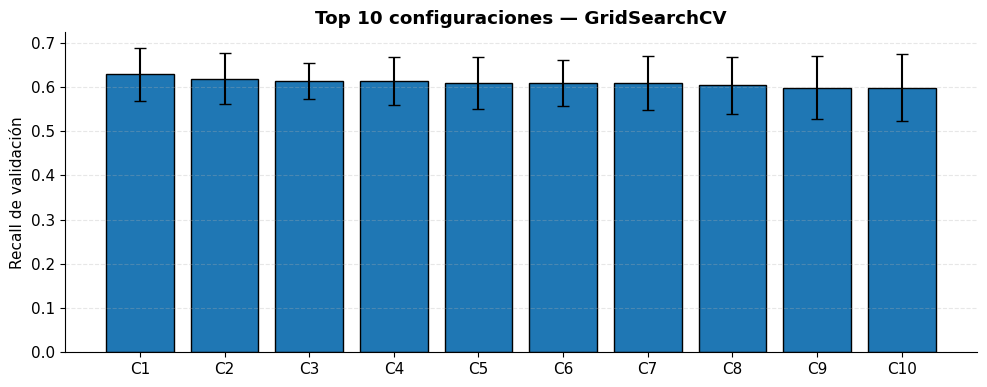

In [ ]:
# Gráfico del top 10 (media ± std)

top = tabla_grid.nlargest(10, "Recall_validacion").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(top)), top["Recall_validacion"],
       yerr=top["std_test_score"], capsize=4, edgecolor="black")
ax.set_xticks(range(len(top)))
ax.set_xticklabels([f"C{i+1}" for i in range(len(top))])
ax.set_ylabel("Recall de validación")
ax.set_title("Top 10 configuraciones — GridSearchCV", fontweight="bold")
ax.grid(alpha=0.3, axis="y", linestyle="--")
plt.tight_layout()
plt.show()

In [ ]:
# Evaluar el modelo optimizado con los datos de prueba
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix

# Mejor pipeline encontrado por GridSearchCV.
# Como refit=True, ya fue reentrenado con TODO X_train usando los mejores parámetros.
modelo_optimizado = busqueda.best_estimator_

# El conjunto de prueba (X_test)
pred_opt = modelo_optimizado.predict(X_test)
prob_opt = modelo_optimizado.predict_proba(X_test)[:, 1]

# Métricas de clasificación (las mismas de la Guía 9)
accuracy_opt  = accuracy_score(y_test, pred_opt)
precision_opt = precision_score(y_test, pred_opt, zero_division=0)
recall_opt    = recall_score(y_test, pred_opt, zero_division=0)
f1_opt        = f1_score(y_test, pred_opt, zero_division=0)
auc_opt       = roc_auc_score(y_test, prob_opt)

# MAE, RMSE y R²: como el problema es de clasificación, se calculan comparando
# la PROBABILIDAD predicha (0 a 1) con el valor real (0 o 1)
mae_opt  = mean_absolute_error(y_test, prob_opt)
rmse_opt = np.sqrt(mean_squared_error(y_test, prob_opt))
r2_opt   = r2_score(y_test, prob_opt)

cm_opt = confusion_matrix(y_test, pred_opt)

print("EVALUACIÓN DEL MODELO OPTIMIZADO EN PRUEBA")
print("=" * 60)
print(f"Mejores parámetros: {busqueda.best_params_}")
print(f"Registros de prueba: {len(X_test)}")

print("\nMÉTRICAS DE CLASIFICACIÓN:")
print(f"   Accuracy:  {accuracy_opt:.4f}")
print(f"   Precision: {precision_opt:.4f}")
print(f"   Recall:    {recall_opt:.4f}   <- métrica usada en GridSearchCV")
print(f"   F1-Score:  {f1_opt:.4f}")
print(f"   ROC-AUC:   {auc_opt:.4f}")

print("\nMÉTRICAS DE ERROR (sobre la probabilidad):")
print(f"   MAE:  {mae_opt:.4f}")
print(f"   RMSE: {rmse_opt:.4f}")
print(f"   R²:   {r2_opt:.4f}")

print("\nMATRIZ DE CONFUSIÓN:")
print(f"                    Predicho 0   Predicho 1")
print(f"   Real 0           TN = {cm_opt[0, 0]:<8} FP = {cm_opt[0, 1]}")
print(f"   Real 1           FN = {cm_opt[1, 0]:<8} TP = {cm_opt[1, 1]}")

print(f"\nRecall en CV: {busqueda.best_score_:.4f}  |  Recall en prueba: {recall_opt:.4f}")
print(f"Diferencia CV - prueba: {busqueda.best_score_ - recall_opt:+.4f}")

EVALUACIÓN DEL MODELO OPTIMIZADO EN PRUEBA
Mejores parámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
Registros de prueba: 120

MÉTRICAS DE CLASIFICACIÓN:
   Accuracy:  0.6833
   Precision: 0.6226
   Recall:    0.6471   <- métrica usada en GridSearchCV
   F1-Score:  0.6346
   ROC-AUC:   0.7582

MÉTRICAS DE ERROR (sobre la probabilidad):
   MAE:  0.4304
   RMSE: 0.4513
   R²:   0.1665

MATRIZ DE CONFUSIÓN:
                    Predicho 0   Predicho 1
   Real 0           TN = 49       FP = 20
   Real 1           FN = 18       TP = 33

Recall en CV: 0.6289  |  Recall en prueba: 0.6471
Diferencia CV - prueba: -0.0181


COMPARACIÓN FINAL — MISMO CONJUNTO DE PRUEBA
                Modelo  Accuracy  Precision  Recall     F1  ROC_AUC    MAE   RMSE      R2
              Baseline    0.5750     0.0000  0.0000 0.0000   0.5000 0.4250 0.6519 -0.7391
Guía 9 (sin optimizar)    0.7083     0.6667  0.6275 0.6465   0.7433 0.4128 0.4495  0.1732
  Guía 10 (optimizado)    0.6833     0.6226  0.6471 0.6346   0.7582 0.4304 0.4513  0.1665

GUÍA 10 vs GUÍA 9
  Métrica  Guía 9  Guía 10  Diferencia ¿Mejoró?
 Accuracy  0.7083   0.6833     -0.0250       No
Precision  0.6667   0.6226     -0.0440       No
   Recall  0.6275   0.6471      0.0196       Sí
       F1  0.6465   0.6346     -0.0118       No
  ROC_AUC  0.7433   0.7582      0.0149       Sí
      MAE  0.4128   0.4304      0.0177       No
     RMSE  0.4495   0.4513      0.0018       No
       R2  0.1732   0.1665     -0.0067       No


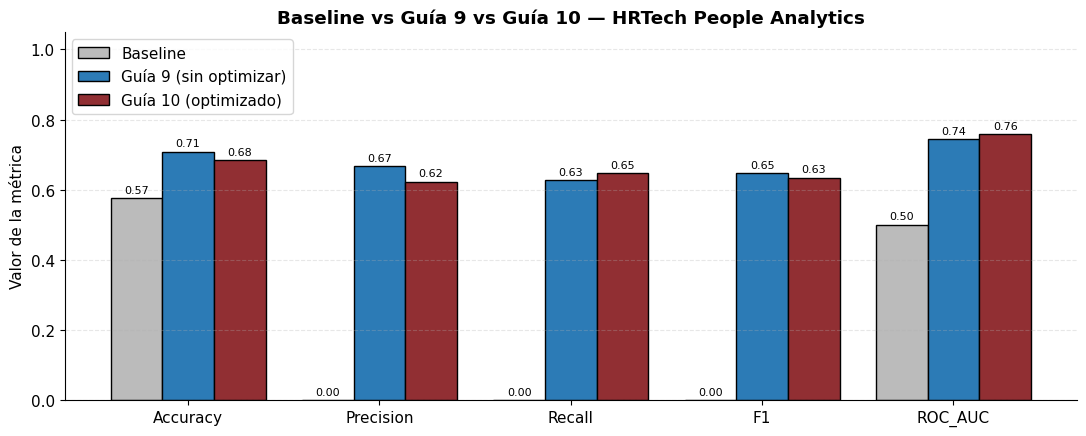


VEREDICTO:
   El modelo optimizado MEJORÓ el Recall en +2.0 puntos porcentuales
   (0.627 -> 0.647): detecta más colaboradores que sí requieren capacitación.
   Cambio en F1: -1.2 puntos | Cambio en Precision: -4.4 puntos


In [ ]:
# Comparar Baseline, Guía 9 y Guía 10 (mismo conjunto de prueba)

prob_guia9 = modelo_guia9.predict_proba(X_test)[:, 1]
prob_base  = baseline.predict_proba(X_test)[:, 1]

def resumen_metricas(nombre, pred, prob):
    """Calcula todas las métricas de un modelo sobre X_test."""
    return {
        "Modelo":    nombre,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred, zero_division=0),
        "F1":        f1_score(y_test, pred, zero_division=0),
        "ROC_AUC":   roc_auc_score(y_test, prob),
        "MAE":       mean_absolute_error(y_test, prob),
        "RMSE":      np.sqrt(mean_squared_error(y_test, prob)),
        "R2":        r2_score(y_test, prob)
    }

comparacion_final = pd.DataFrame([
    resumen_metricas("Baseline",               pred_base,  prob_base),
    resumen_metricas("Guía 9 (sin optimizar)", pred_guia9, prob_guia9),
    resumen_metricas("Guía 10 (optimizado)",   pred_opt,   prob_opt)
])

print("COMPARACIÓN FINAL — MISMO CONJUNTO DE PRUEBA")
print("=" * 100)
print(comparacion_final.round(4).to_string(index=False))

# ¿Mejoró la Guía 10 respecto a la Guía 9? (en MAE y RMSE, menor es mejor)
mayor_es_mejor = {"Accuracy": True, "Precision": True, "Recall": True, "F1": True,
                  "ROC_AUC": True, "MAE": False, "RMSE": False, "R2": True}

g9  = comparacion_final.iloc[1]
g10 = comparacion_final.iloc[2]

tabla_mejora = pd.DataFrame({
    "Métrica": list(mayor_es_mejor.keys()),
    "Guía 9":  [g9[m]  for m in mayor_es_mejor],
    "Guía 10": [g10[m] for m in mayor_es_mejor],
})
tabla_mejora["Diferencia"] = tabla_mejora["Guía 10"] - tabla_mejora["Guía 9"]
tabla_mejora["¿Mejoró?"] = [
    "Sí" if (d > 0 if mayor_es_mejor[m] else d < 0) else ("Igual" if d == 0 else "No")
    for m, d in zip(tabla_mejora["Métrica"], tabla_mejora["Diferencia"])
]

print("\nGUÍA 10 vs GUÍA 9")
print("=" * 60)
print(tabla_mejora.round(4).to_string(index=False))

# Gráfico de barras agrupadas
metricas_graf = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
x = np.arange(len(metricas_graf))
ancho = 0.27
colores = ["#BBBBBB", "#2c7bb6", "#912F33"]

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, (_, fila) in enumerate(comparacion_final.iterrows()):
    valores = [fila[m] for m in metricas_graf]
    barras = ax.bar(x + (i - 1) * ancho, valores, ancho, label=fila["Modelo"],
                    color=colores[i], edgecolor="black")
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{v:.2f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metricas_graf)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Baseline vs Guía 9 vs Guía 10 — HRTech People Analytics", fontweight="bold")
ax.legend(loc="upper left")
ax.grid(alpha=0.3, axis="y", linestyle="--")
plt.tight_layout()
plt.show()

# Veredicto (la métrica principal es Recall, porque fue la usada en GridSearchCV)
mejora_recall = recall_opt - recall_guia9
mejora_f1     = f1_opt - f1_guia9
print("\nVEREDICTO:")
if mejora_recall > 0:
    print(f"   El modelo optimizado MEJORÓ el Recall en {mejora_recall*100:+.1f} puntos porcentuales")
    print(f"   ({recall_guia9:.3f} -> {recall_opt:.3f}): detecta más colaboradores que sí requieren capacitación.")
else:
    print(f"   El modelo optimizado NO mejoró el Recall ({recall_guia9:.3f} -> {recall_opt:.3f}).")
print(f"   Cambio en F1: {mejora_f1*100:+.1f} puntos | Cambio en Precision: {(precision_opt - precision_guia9)*100:+.1f} puntos")

TOP 10 ERRORES ABSOLUTOS MÁS GRANDES — MODELO OPTIMIZADO
 id_empleado  desempeño  satisfaccion  horas_capacitacion  horas_extra  curso_aprobado  real  predicho  probabilidad  error_abs              tipo
         220       86.0             5                  12           10               0     1         0         0.199      0.801 FN (no detectado)
         234       90.0             3                  10            5               0     1         0         0.301      0.699 FN (no detectado)
         545       77.0             2                   6           14               1     0         1         0.692      0.692 FP (falsa alarma)
         178       77.0             1                   8           14               0     0         1         0.669      0.669 FP (falsa alarma)
         160       77.0             2                   8            7               1     0         1         0.668      0.668 FP (falsa alarma)
          10       92.0             1                  10          

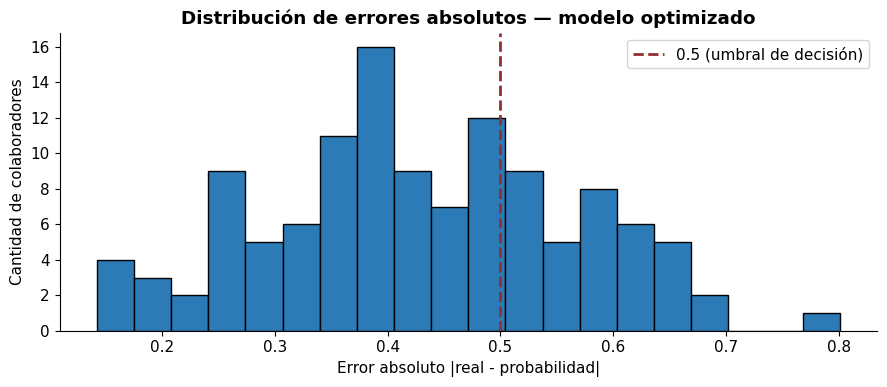

NOTA: un error absoluto > 0.5 significa que el modelo clasificó mal al colaborador.


In [ ]:
# Analizar los 10 errores absolutos más grandes

errores_opt = X_test[["desempeño", "satisfaccion", "horas_capacitacion",
                      "horas_extra", "curso_aprobado"]].copy()
errores_opt.insert(0, "id_empleado", df_modelo.loc[X_test.index, "id_empleado"].values)
errores_opt["real"]         = y_test.values
errores_opt["predicho"]     = pred_opt
errores_opt["probabilidad"] = prob_opt.round(3)

# Error absoluto = qué tan lejos quedó la probabilidad del valor real
errores_opt["error_abs"] = (errores_opt["real"] - errores_opt["probabilidad"]).abs().round(3)
errores_opt["tipo"] = np.where(
    errores_opt["real"] == errores_opt["predicho"], "Acierto",
    np.where(errores_opt["real"] == 1, "FN (no detectado)", "FP (falsa alarma)")
)

top10_errores = errores_opt.nlargest(10, "error_abs").reset_index(drop=True)

print("TOP 10 ERRORES ABSOLUTOS MÁS GRANDES — MODELO OPTIMIZADO")
print("=" * 110)
print(top10_errores.to_string(index=False))

print("\nRESUMEN DEL TOP 10:")
print(f"   Falsos negativos (FN): {(top10_errores['tipo'] == 'FN (no detectado)').sum()}")
print(f"   Falsos positivos (FP): {(top10_errores['tipo'] == 'FP (falsa alarma)').sum()}")
print(f"   Error absoluto promedio del top 10:      {top10_errores['error_abs'].mean():.3f}")
print(f"   Error absoluto promedio de toda la prueba: {errores_opt['error_abs'].mean():.3f}")

# ¿En qué se parecen los casos con más error? Comparar promedios
vars_perfil = ["desempeño", "satisfaccion", "horas_capacitacion", "horas_extra", "curso_aprobado"]
perfil = pd.DataFrame({
    "Top 10 errores":   top10_errores[vars_perfil].mean(),
    "Todo el test":     errores_opt[vars_perfil].mean()
}).round(2)

print("\nPERFIL PROMEDIO: TOP 10 ERRORES vs TODO EL CONJUNTO DE PRUEBA")
print(perfil.to_string())

# Distribución de los errores absolutos
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(errores_opt["error_abs"], bins=20, color="#2c7bb6", edgecolor="black")
ax.axvline(0.5, color="#912F33", linestyle="--", linewidth=2, label="0.5 (umbral de decisión)")
ax.set_xlabel("Error absoluto |real - probabilidad|")
ax.set_ylabel("Cantidad de colaboradores")
ax.set_title("Distribución de errores absolutos — modelo optimizado", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

print("NOTA: un error absoluto > 0.5 significa que el modelo clasificó mal al colaborador.")

In [ ]:
# Evaluar el modelo optimizado con los datos de prueba
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix

# Mejor pipeline encontrado por GridSearchCV.
# Como refit=True, ya fue reentrenado con TODO X_train usando los mejores parámetros.
modelo_optimizado = busqueda.best_estimator_

# El conjunto de prueba (X_test)
pred_opt = modelo_optimizado.predict(X_test)
prob_opt = modelo_optimizado.predict_proba(X_test)[:, 1]

# Métricas de clasificación (las mismas de la Guía 9)
accuracy_opt  = accuracy_score(y_test, pred_opt)
precision_opt = precision_score(y_test, pred_opt, zero_division=0)
recall_opt    = recall_score(y_test, pred_opt, zero_division=0)
f1_opt        = f1_score(y_test, pred_opt, zero_division=0)
auc_opt       = roc_auc_score(y_test, prob_opt)

# MAE, RMSE y R²: como el problema es de clasificación, se calculan comparando
# la PROBABILIDAD predicha (0 a 1) con el valor real (0 o 1)
mae_opt  = mean_absolute_error(y_test, prob_opt)
rmse_opt = np.sqrt(mean_squared_error(y_test, prob_opt))
r2_opt   = r2_score(y_test, prob_opt)

cm_opt = confusion_matrix(y_test, pred_opt)

print("EVALUACIÓN DEL MODELO OPTIMIZADO EN PRUEBA")
print("=" * 60)
print(f"Mejores parámetros: {busqueda.best_params_}")
print(f"Registros de prueba: {len(X_test)}")

print("\nMÉTRICAS DE CLASIFICACIÓN:")
print(f"   Accuracy:  {accuracy_opt:.4f}")
print(f"   Precision: {precision_opt:.4f}")
print(f"   Recall:    {recall_opt:.4f}   <- métrica usada en GridSearchCV")
print(f"   F1-Score:  {f1_opt:.4f}")
print(f"   ROC-AUC:   {auc_opt:.4f}")

print("\nMÉTRICAS DE ERROR (sobre la probabilidad):")
print(f"   MAE:  {mae_opt:.4f}")
print(f"   RMSE: {rmse_opt:.4f}")
print(f"   R²:   {r2_opt:.4f}")

print("\nMATRIZ DE CONFUSIÓN:")
print(f"                    Predicho 0   Predicho 1")
print(f"   Real 0           TN = {cm_opt[0, 0]:<8} FP = {cm_opt[0, 1]}")
print(f"   Real 1           FN = {cm_opt[1, 0]:<8} TP = {cm_opt[1, 1]}")

print(f"\nRecall en CV: {busqueda.best_score_:.4f}  |  Recall en prueba: {recall_opt:.4f}")
print(f"Diferencia CV - prueba: {busqueda.best_score_ - recall_opt:+.4f}")

EVALUACIÓN DEL MODELO OPTIMIZADO EN PRUEBA
Mejores parámetros: {'modelo__class_weight': 'balanced', 'modelo__max_depth': 5, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 200}
Registros de prueba: 120

MÉTRICAS DE CLASIFICACIÓN:
   Accuracy:  0.6833
   Precision: 0.6226
   Recall:    0.6471   <- métrica usada en GridSearchCV
   F1-Score:  0.6346
   ROC-AUC:   0.7582

MÉTRICAS DE ERROR (sobre la probabilidad):
   MAE:  0.4304
   RMSE: 0.4513
   R²:   0.1665

MATRIZ DE CONFUSIÓN:
                    Predicho 0   Predicho 1
   Real 0           TN = 49       FP = 20
   Real 1           FN = 18       TP = 33

Recall en CV: 0.6289  |  Recall en prueba: 0.6471
Diferencia CV - prueba: -0.0181


COMPARACIÓN FINAL — MISMO CONJUNTO DE PRUEBA
                Modelo  Accuracy  Precision  Recall     F1  ROC_AUC    MAE   RMSE      R2
              Baseline    0.5750     0.0000  0.0000 0.0000   0.5000 0.4250 0.6519 -0.7391
Guía 9 (sin optimizar)    0.7083     0.6667  0.6275 0.6465   0.7433 0.4128 0.4495  0.1732
  Guía 10 (optimizado)    0.6833     0.6226  0.6471 0.6346   0.7582 0.4304 0.4513  0.1665

GUÍA 10 vs GUÍA 9
  Métrica  Guía 9  Guía 10  Diferencia ¿Mejoró?
 Accuracy  0.7083   0.6833     -0.0250       No
Precision  0.6667   0.6226     -0.0440       No
   Recall  0.6275   0.6471      0.0196       Sí
       F1  0.6465   0.6346     -0.0118       No
  ROC_AUC  0.7433   0.7582      0.0149       Sí
      MAE  0.4128   0.4304      0.0177       No
     RMSE  0.4495   0.4513      0.0018       No
       R2  0.1732   0.1665     -0.0067       No


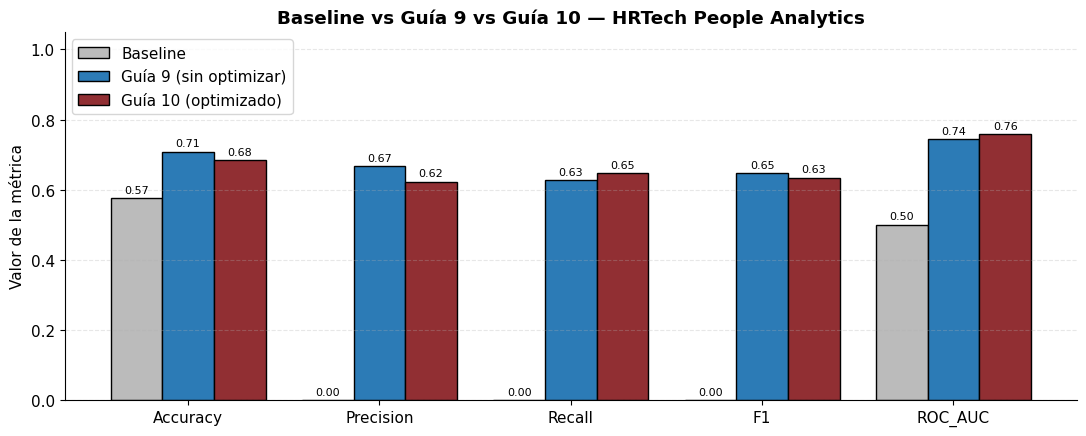


VEREDICTO:
   El modelo optimizado MEJORÓ el Recall en +2.0 puntos porcentuales
   (0.627 -> 0.647): detecta más colaboradores que sí requieren capacitación.
   Cambio en F1: -1.2 puntos | Cambio en Precision: -4.4 puntos


In [ ]:
# Comparar Baseline, Guía 9 y Guía 10

prob_guia9 = modelo_guia9.predict_proba(X_test)[:, 1]
prob_base  = baseline.predict_proba(X_test)[:, 1]

def resumen_metricas(nombre, pred, prob):
    """Calcula todas las métricas de un modelo sobre X_test."""
    return {
        "Modelo":    nombre,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall":    recall_score(y_test, pred, zero_division=0),
        "F1":        f1_score(y_test, pred, zero_division=0),
        "ROC_AUC":   roc_auc_score(y_test, prob),
        "MAE":       mean_absolute_error(y_test, prob),
        "RMSE":      np.sqrt(mean_squared_error(y_test, prob)),
        "R2":        r2_score(y_test, prob)
    }

comparacion_final = pd.DataFrame([
    resumen_metricas("Baseline",               pred_base,  prob_base),
    resumen_metricas("Guía 9 (sin optimizar)", pred_guia9, prob_guia9),
    resumen_metricas("Guía 10 (optimizado)",   pred_opt,   prob_opt)
])

print("COMPARACIÓN FINAL — MISMO CONJUNTO DE PRUEBA")
print("=" * 100)
print(comparacion_final.round(4).to_string(index=False))

# ¿Mejoró la Guía 10 respecto a la Guía 9? (en MAE y RMSE, menor es mejor)
mayor_es_mejor = {"Accuracy": True, "Precision": True, "Recall": True, "F1": True,
                  "ROC_AUC": True, "MAE": False, "RMSE": False, "R2": True}

g9  = comparacion_final.iloc[1]
g10 = comparacion_final.iloc[2]

tabla_mejora = pd.DataFrame({
    "Métrica": list(mayor_es_mejor.keys()),
    "Guía 9":  [g9[m]  for m in mayor_es_mejor],
    "Guía 10": [g10[m] for m in mayor_es_mejor],
})
tabla_mejora["Diferencia"] = tabla_mejora["Guía 10"] - tabla_mejora["Guía 9"]
tabla_mejora["¿Mejoró?"] = [
    "Sí" if (d > 0 if mayor_es_mejor[m] else d < 0) else ("Igual" if d == 0 else "No")
    for m, d in zip(tabla_mejora["Métrica"], tabla_mejora["Diferencia"])
]

print("\nGUÍA 10 vs GUÍA 9")
print("=" * 60)
print(tabla_mejora.round(4).to_string(index=False))

# Gráfico de barras agrupadas
metricas_graf = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]
x = np.arange(len(metricas_graf))
ancho = 0.27
colores = ["#BBBBBB", "#2c7bb6", "#912F33"]

fig, ax = plt.subplots(figsize=(11, 4.5))
for i, (_, fila) in enumerate(comparacion_final.iterrows()):
    valores = [fila[m] for m in metricas_graf]
    barras = ax.bar(x + (i - 1) * ancho, valores, ancho, label=fila["Modelo"],
                    color=colores[i], edgecolor="black")
    for b, v in zip(barras, valores):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{v:.2f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(metricas_graf)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Baseline vs Guía 9 vs Guía 10 — HRTech People Analytics", fontweight="bold")
ax.legend(loc="upper left")
ax.grid(alpha=0.3, axis="y", linestyle="--")
plt.tight_layout()
plt.show()

# Veredicto (la métrica principal es Recall, porque fue la usada en GridSearchCV)
mejora_recall = recall_opt - recall_guia9
mejora_f1     = f1_opt - f1_guia9
print("\nVEREDICTO:")
if mejora_recall > 0:
    print(f"   El modelo optimizado MEJORÓ el Recall en {mejora_recall*100:+.1f} puntos porcentuales")
    print(f"   ({recall_guia9:.3f} -> {recall_opt:.3f}): detecta más colaboradores que sí requieren capacitación.")
else:
    print(f"   El modelo optimizado NO mejoró el Recall ({recall_guia9:.3f} -> {recall_opt:.3f}).")
print(f"   Cambio en F1: {mejora_f1*100:+.1f} puntos | Cambio en Precision: {(precision_opt - precision_guia9)*100:+.1f} puntos")

In [ ]:
# Guardar los resultados y archivos del modelo
from pathlib import Path

BASE_P = Path(BASE)   # carpeta del proyecto en Drive (definida al inicio de la Guía 10)
(BASE_P / "modelos").mkdir(parents=True, exist_ok=True)
(BASE_P / "documentos").mkdir(parents=True, exist_ok=True)
(BASE_P / "datos" / "procesados").mkdir(parents=True, exist_ok=True)

# 1) Modelo optimizado (pipeline completo: imputador + Random Forest)
ruta_modelo_opt = BASE_P / "modelos" / "modelo_optimizado_guia10_hrtech.joblib"
joblib.dump(modelo_optimizado, ruta_modelo_opt)

# 2) Comparación Baseline vs Guía 9 vs Guía 10
ruta_comp_final = BASE_P / "documentos" / "comparacion_final_guia10_hrtech.csv"
comparacion_final.to_csv(ruta_comp_final, index=False, encoding="utf-8")

# 3) Resultados completos del GridSearchCV (36 combinaciones)
ruta_grid = BASE_P / "documentos" / "resultados_gridsearch_guia10_hrtech.csv"
tabla_grid.to_csv(ruta_grid, index=False, encoding="utf-8")

# 4) Top 10 errores absolutos
ruta_top10 = BASE_P / "documentos" / "top10_errores_guia10_hrtech.csv"
top10_errores.to_csv(ruta_top10, index=False, encoding="utf-8")

# 5) Predicciones del modelo optimizado sobre todo el conjunto de prueba
ruta_pred_opt = BASE_P / "datos" / "procesados" / "predicciones_guia10_hrtech.csv"
errores_opt.to_csv(ruta_pred_opt, index=False, encoding="utf-8")

archivos_guia10 = [ruta_modelo_opt, ruta_comp_final, ruta_grid, ruta_top10, ruta_pred_opt]

print("ARCHIVOS GUARDADOS")
print("=" * 75)
for r in archivos_guia10:
    print(f"  {str(r.relative_to(BASE_P)):<55} {r.stat().st_size / 1024:>8.1f} KB")

ARCHIVOS GUARDADOS
  modelos/modelo_optimizado_guia10_hrtech.joblib             745.9 KB
  documentos/comparacion_final_guia10_hrtech.csv               0.5 KB
  documentos/resultados_gridsearch_guia10_hrtech.csv           9.8 KB
  documentos/top10_errores_guia10_hrtech.csv                   0.6 KB
  datos/procesados/predicciones_guia10_hrtech.csv              5.3 KB


In [ ]:
# Crear los metadatos del experimento
import json
from datetime import datetime

metadata_g10 = {
    "proyecto":        "HRTech People Analytics",
    "guia":            "Guía 10 - Optimización de hiperparámetros",
    "fecha_ejecucion": datetime.now().isoformat(timespec="seconds"),
    "versiones": {
        "python":       sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "pandas":       pd.__version__,
        "numpy":        np.__version__
    },
    "random_state": RANDOM_STATE,
    "datos": {
        "tipo":              "Sintéticos (reconstruidos con la fórmula de la Guía 8)",
        "variable_objetivo": "requiere_capacitacion",
        "n_filas":           len(df_modelo),
        "n_train":           len(X_train),
        "n_test":            len(X_test),
        "n_features":        len(features),
        "features":          features
    },
    "busqueda": {
        "metodo":             "GridSearchCV",
        "modelo":             "RandomForestClassifier (Pipeline con SimpleImputer)",
        "validacion":         f"StratifiedKFold(n_splits={cv.get_n_splits()}, shuffle=True)",
        "scoring":            "recall",
        "param_grid":         param_grid,
        "combinaciones":      len(combinaciones),
        "entrenamientos":     len(combinaciones) * cv.get_n_splits(),
        "tiempo_segundos":    round(tiempo_total, 2),
        "mejores_parametros": busqueda.best_params_,
        "mejor_recall_cv":    round(float(busqueda.best_score_), 4)
    },
    "metricas_test_guia10": {
        "accuracy":  round(float(accuracy_opt), 4),
        "precision": round(float(precision_opt), 4),
        "recall":    round(float(recall_opt), 4),
        "f1":        round(float(f1_opt), 4),
        "roc_auc":   round(float(auc_opt), 4),
        "mae":       round(float(mae_opt), 4),
        "rmse":      round(float(rmse_opt), 4),
        "r2":        round(float(r2_opt), 4)
    },
    "comparacion": {
        "recall_baseline": round(float(recall_base), 4),
        "recall_guia9":    round(float(recall_guia9), 4),
        "recall_guia10":   round(float(recall_opt), 4),
        "f1_guia9":        round(float(f1_guia9), 4),
        "f1_guia10":       round(float(f1_opt), 4),
        "mejoro_recall":   bool(recall_opt > recall_guia9)
    },
    "archivos": [str(r.relative_to(BASE_P)) for r in archivos_guia10]
}

ruta_meta_g10 = BASE_P / "documentos" / "metadata_guia10_hrtech.json"
with open(ruta_meta_g10, "w", encoding="utf-8") as f:
    json.dump(metadata_g10, f, ensure_ascii=False, indent=4, default=str)

print("METADATOS DEL EXPERIMENTO")
print("=" * 75)
print(json.dumps(metadata_g10, ensure_ascii=False, indent=2, default=str))
print(f"\nGuardado en: {ruta_meta_g10.relative_to(BASE_P)}")

METADATOS DEL EXPERIMENTO
{
  "proyecto": "HRTech People Analytics",
  "guia": "Guía 10 - Optimización de hiperparámetros",
  "fecha_ejecucion": "2026-11-18T17:19:34",
  "versiones": {
    "python": "3.13.18",
    "scikit_learn": "1.6.1",
    "pandas": "2.2.3",
    "numpy": "2.4.6"
  },
  "random_state": 42,
  "datos": {
    "tipo": "Sintéticos (reconstruidos con la fórmula de la Guía 8)",
    "variable_objetivo": "requiere_capacitacion",
    "n_filas": 600,
    "n_train": 480,
    "n_test": 120,
    "n_features": 12,
    "features": [
      "edad",
      "desempeño",
      "salario",
      "tiempo_empresa_anios",
      "horas_capacitacion",
      "satisfaccion",
      "horas_extra",
      "curso_aprobado",
      "departamento_IT",
      "departamento_Marketing",
      "departamento_RRHH",
      "departamento_Ventas"
    ]
  },
  "busqueda": {
    "metodo": "GridSearchCV",
    "modelo": "RandomForestClassifier (Pipeline con SimpleImputer)",
    "validacion": "StratifiedKFold(n_splits=4

In [ ]:
#  Verificación final de los archivos (auditoría)

archivos_auditar = archivos_guia10 + [ruta_meta_g10]

# Recargar el modelo y los metadatos desde el disco
modelo_recargado = joblib.load(ruta_modelo_opt)
with open(ruta_meta_g10, encoding="utf-8") as f:
    meta_leida = json.load(f)
comp_leida = pd.read_csv(ruta_comp_final)

verificaciones = {
    "Train y test sin registros en común":                set(X_train.index).isdisjoint(set(X_test.index)),
    "Train 480 filas / Test 120 filas":                   len(X_train) == 480 and len(X_test) == 120,
    "GridSearchCV probó todas las combinaciones (36)":    len(tabla_grid) == len(combinaciones),
    "El modelo optimizado supera al baseline (F1)":       f1_opt > f1_base,
    "Comparación incluye 3 modelos":                      len(comp_leida) == 3,
    "Top 10 errores analizados":                          len(top10_errores) == 10,
    "Todos los archivos existen y no están vacíos":       all(r.exists() and r.stat().st_size > 0 for r in archivos_auditar),
    "Modelo recargado da las mismas predicciones":        np.array_equal(modelo_recargado.predict(X_test), pred_opt),
    "Modelo recargado da las mismas probabilidades":      np.allclose(modelo_recargado.predict_proba(X_test)[:, 1], prob_opt),
    "Metadatos se leen y tienen los mejores parámetros":  meta_leida["busqueda"]["mejores_parametros"] == busqueda.best_params_,
    "Recall de los metadatos coincide con el calculado":  abs(meta_leida["metricas_test_guia10"]["recall"] - recall_opt) < 1e-4,
    "Métricas dentro del rango válido [0, 1]":            all(0 <= v <= 1 for v in [accuracy_opt, precision_opt, recall_opt, f1_opt, auc_opt, mae_opt, rmse_opt]),
}

print("AUDITORÍA FINAL — CHECKLIST")
print("=" * 75)
todo_ok = True
for descripcion, ok in verificaciones.items():
    print(f"  {'OK    ' if ok else 'FALLÓ '} {descripcion}")
    todo_ok = todo_ok and bool(ok)

print("\nINVENTARIO DE ARCHIVOS")
print("=" * 75)
for r in archivos_auditar:
    print(f"  {str(r.relative_to(BASE_P)):<55} {r.stat().st_size / 1024:>8.1f} KB")

print("\n" + "=" * 75)
print("TODAS LAS VERIFICACIONES PASARON" if todo_ok else "ALGUNAS VERIFICACIONES FALLARON — revisar celdas previas")

AUDITORÍA FINAL — CHECKLIST
  OK     Train y test sin registros en común
  OK     Train 480 filas / Test 120 filas
  OK     GridSearchCV probó todas las combinaciones (36)
  OK     El modelo optimizado supera al baseline (F1)
  OK     Comparación incluye 3 modelos
  OK     Top 10 errores analizados
  OK     Todos los archivos existen y no están vacíos
  OK     Modelo recargado da las mismas predicciones
  OK     Modelo recargado da las mismas probabilidades
  OK     Metadatos se leen y tienen los mejores parámetros
  OK     Recall de los metadatos coincide con el calculado
  OK     Métricas dentro del rango válido [0, 1]

INVENTARIO DE ARCHIVOS
  modelos/modelo_optimizado_guia10_hrtech.joblib             745.9 KB
  documentos/comparacion_final_guia10_hrtech.csv               0.5 KB
  documentos/resultados_gridsearch_guia10_hrtech.csv           9.8 KB
  documentos/top10_errores_guia10_hrtech.csv                   0.6 KB
  datos/procesados/predicciones_guia10_hrtech.csv              5.3 

In [ ]:
# Empaquetar los archivos en un ZIP
import zipfile

ruta_zip = BASE_P / "entregables_guia10_hrtech.zip"

# Se incluye también el modelo de la Guía 9 para poder repetir la comparación
ruta_g9_p = Path(ruta_g9)
archivos_zip = archivos_auditar + ([ruta_g9_p] if ruta_g9_p.exists() else [])

with zipfile.ZipFile(ruta_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for r in archivos_zip:
        z.write(r, arcname=str(r.relative_to(BASE_P)))   # conserva la estructura de carpetas

# Verificar el ZIP
with zipfile.ZipFile(ruta_zip) as z:
    contenido = z.namelist()
    zip_ok = z.testzip() is None      # None = ningún archivo dañado

print("ZIP CREADO")
print("=" * 75)
print(f"Ruta: {ruta_zip}")
print(f"Tamaño: {ruta_zip.stat().st_size / 1024:.1f} KB")
print(f"Archivos dentro ({len(contenido)}):")
for nombre in contenido:
    print(f"   • {nombre}")
print(f"\nIntegridad del ZIP: {'OK' if zip_ok else 'ARCHIVO DAÑADO'}")

# Descargar desde Colab
try:
    from google.colab import files
    files.download(str(ruta_zip))
    print("Descarga iniciada")
except ImportError:
    print("No se está ejecutando en Colab: el ZIP queda en la carpeta del proyecto.")

ZIP CREADO
Ruta: /content/drive/MyDrive/Proyecto_datos_ia_HRTech_People_Analytics/entregables_guia10_hrtech.zip
Tamaño: 246.0 KB
Archivos dentro (6):
   • modelos/modelo_optimizado_guia10_hrtech.joblib
   • documentos/comparacion_final_guia10_hrtech.csv
   • documentos/resultados_gridsearch_guia10_hrtech.csv
   • documentos/top10_errores_guia10_hrtech.csv
   • datos/procesados/predicciones_guia10_hrtech.csv
   • documentos/metadata_guia10_hrtech.json

Integridad del ZIP: OK


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Descarga iniciada


In [ ]:
#CELDA 4: Catálogo de modelos candidatos
modelos = {
    "Baseline clase frecuente": DummyClassifier(strategy="most_frequent"),
    "Regresión logística":      Pipeline([
                                    ("scaler", StandardScaler()),
                                    ("clf", LogisticRegression(random_state=RANDOM_STATE, max_iter=1000))
                                ]),
    "Árbol de decisión":        DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest":            RandomForestClassifier(random_state=RANDOM_STATE)
}

print("MODELOS EN EL CATÁLOGO")
print("=" * 55)
for i, nombre in enumerate(modelos.keys(), 1):
    print(f"  {i}. {nombre}")

MODELOS EN EL CATÁLOGO
  1. Baseline clase frecuente
  2. Regresión logística
  3. Árbol de decisión
  4. Random Forest
